# HKUST PV fleet: fuzzy anomaly interpretation and ablation study

**The entire pipeline is unsupervised.** STGNN is trained in a self-supervised manner (forecast + reconstruction + physics residual); anomaly thresholds come from the training distribution (extreme-value / quantile); events are clustered using K-Means; and crisp/fuzzy interpretation relies on domain rules from PV physics. No labeled anomaly data are used.

**The β1 estimator (section 6) is selected via `ESTIMATOR`:**
- `"sps"` — Sign-Perturbed Sums (`pv_sps.py`): exact finite-sample confidence regions under symmetric noise with day-level blocks;
- `"kalman"` — a Kalman filter with random-walk coefficients and RTS smoothing (`pv_kalman.py`): daily β1 trajectories and Gaussian intervals.

Both estimators produce tables with the same structure, so sections 6–8 work with either one. Section 9 compares SPS and the Kalman filter in terms of the final model output (Silhouette, Davies–Bouldin, Calinski–Harabasz, ARI) and exports the table to LaTeX.



In [1]:
!pip -q install rdflib torch pandas openpyxl scikit-learn networkx scipy matplotlib

In [2]:
import requests
import json
import os
import zipfile
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import torch
from sklearn.preprocessing import StandardScaler

In [ ]:
import os
import sys
from pathlib import Path

# Project paths. Set the environment variables PV_DATA_ROOT / PV_CODE_ROOT or edit the defaults below.
# DATA_ROOT — folder that contains the unpacked HKUST dataset (the Dataset/ subfolder),
#             https://doi.org/10.5061/dryad.m37pvmd99
# CODE_ROOT — folder with the pv_*.py modules (default: current repository folder).
# Kaggle example: PV_DATA_ROOT=/kaggle/input/<hkust-dataset>, PV_CODE_ROOT=/kaggle/input/<code-dataset>
DATA_ROOT = Path(os.environ.get("PV_DATA_ROOT", "data/hkust")).expanduser().resolve()
CODE_ROOT = Path(os.environ.get("PV_CODE_ROOT", ".")).expanduser().resolve()

if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))
if not (DATA_ROOT / "Dataset").is_dir():
    print(f"Warning: {DATA_ROOT / 'Dataset'} not found; set PV_DATA_ROOT to the folder that contains Dataset/")
print("DATA_ROOT:", DATA_ROOT)
print("CODE_ROOT:", CODE_ROOT)

In [4]:
train_seeds = [0, 1, 42, 77, 4700]

In [5]:
import polars as pl
from pathlib import Path

def load_all_data_from_folder(folder_path, years=None, **read_kwargs):
    """
    Recursively traverse the specified folder and load all CSV and Excel files,
    optionally filtering by the year in each filename.

    Parameters:
        folder_path : str or Path — root folder.
        years       : int or list[int] — year(s) that must appear in the filename.
                      If None, load all files.
        **read_kwargs : additional reading arguments (e.g., separator, encoding,
                        sheet_name for Excel).
    Returns:
        dict: relative file paths as keys and Polars DataFrames as values.
    """


    date1 = str(years) + '-01-01 00:00:00'
    date2 = str(years) + '-12-31 23:59:00'
    full_range = pd.date_range(date1, date2, freq='1min')

    # Empty DataFrame indexed by the complete timeline
    df_all = pd.DataFrame(index=full_range)

    root = Path(folder_path)
    if not root.exists():
        raise FileNotFoundError(f"Folder not found: {root}")

    # Convert years to a list of strings for matching
    if years is not None:
        if isinstance(years, int):
            year_patterns = [str(years)]
        else:
            year_patterns = [str(y) for y in years]
    else:
        year_patterns = None

    data_dict = {} #pd.DataFrame()
    extensions = ['.csv', '.xlsx', '.xls']

    for file_path in root.rglob('*'):
        if file_path.suffix.lower() not in extensions:
            continue

        # Filter by year in the filename
        if year_patterns is not None:
            if not any(yp in file_path.name for yp in year_patterns):
                continue

        # Separate CSV and Excel parameters
        csv_kwargs = {k: v for k, v in read_kwargs.items() if k != 'sheet_name'}
        excel_kwargs = {'sheet_name': read_kwargs.get('sheet_name', 0)} if 'sheet_name' in read_kwargs else {}

        try:
            if file_path.suffix.lower() == '.csv':
                csv_kwargs.setdefault('try_parse_dates', True)
                df = pd.read_csv(file_path)



            else:  # Excel
                df = pd.read_excel(file_path, **excel_kwargs)

            rel_path = file_path.relative_to(root)

            time_col = df.columns[0]          # first column: time
            val_col1 = df.columns[1]          # second column: first value
            try:
              val_col2 = df.columns[2]          # third column: second value (if present)
            except Exception as e:
              pass
            df[time_col] = pd.to_datetime(df[time_col])
            df = df.set_index(time_col)

            # Add both columns; reindex inserts NaN where timestamps are missing
            df_all[val_col1] = df[val_col1].reindex(full_range)
            try:
              df_all[val_col2] = df[val_col2].reindex(full_range)
            except Exception as e:
              pass
            #print(df_all)
            data = df.to_dict(orient='list')

            for col in df_all.columns:
                if col not in data_dict:
                    data_dict[col] = []
                    data_dict[col].extend(df[col].tolist())
            #data_dict[str(rel_path)] = df
            print(f"Loaded: {rel_path} ({df.shape[0]} rows)")
        except Exception as e:
            print(f"Error while reading {file_path}: {e}")



    data = pd.DataFrame({k: pd.Series(v) for k, v in data_dict.items()})
    #data['Time'] = pd.to_datetime(data['Time'])
    #data = data.set_index('Time')

    return df_all

In [6]:
def load_all_pv_data(folder_path, period='15min', **read_kwargs):
    date1 = '2021-01-01 00:00:00'
    date2 = '2023-12-31 23:59:00'
    full_range = pd.date_range(date1, date2, freq=period)

    # Empty DataFrame indexed by the complete timeline
    df_pv = pd.DataFrame(index=full_range)
    df_pv.index.name = 'Time'

    root = Path(folder_path)
    if not root.exists():
        raise FileNotFoundError(f"Folder not found: {root}")

    # Prevent read_csv from setting index_col so the first column is consistently treated as time
    read_kwargs = dict(read_kwargs)
    read_kwargs.pop('index_col', None)

    for csv_file in sorted(root.glob('*.csv')):
        df = pd.read_csv(csv_file, **read_kwargs)
        if df.empty:
            continue

        # First column: time
        time_col = df.columns[0]
        df[time_col] = pd.to_datetime(df[time_col], errors='coerce')
        df = df.dropna(subset=[time_col]).set_index(time_col)

        # Keep the last value for duplicate timestamps
        df = df[~df.index.duplicated(keep='last')]

        # Find power columns
        power_cols = [c for c in df.columns if 'w' in str(c).lower()]
        if not power_cols:
            continue

        for col in power_cols:
            # Append the filename stem to the power column name
            new_col = f"{col}_{csv_file.stem}"
            series = pd.to_numeric(df[col], errors='coerce').reindex(full_range)
            df_pv[new_col] = series

    # Fill missing values (including NA in the source files) with zeros.
    # To preserve NaN, comment out the line below.
    #df_pv = df_pv.fillna(0.0)

    return df_pv

In [7]:
def merge_three_time_series(
    df1: pd.DataFrame,
    df2: pd.DataFrame,
    df3: pd.DataFrame,
    freq: str = '15min',
    start: str | None = None,
    end: str | None = None,
    fill_value: float | None = 0.0,
    suffixes: tuple = ('', '', '')
) -> pd.DataFrame:
    """
    Merge three time series into a single time-aligned DataFrame.

    Parameters
    ----------
    df1, df2, df3 : pd.DataFrame
        DataFrames with a DatetimeIndex (or time in the first column).
    freq : str
        Frequency of the complete timeline (if start and end are specified).
    start, end : str | None
        Start and end of the complete timeline. If omitted, use the union of indices.
    fill_value : float | None
        Value used to fill missing data. None preserves NaN.
    suffixes : tuple
        Column suffixes for duplicate names.

    Returns
    -------
    pd.DataFrame
        Merged DataFrame with a common DatetimeIndex.
    """
    dfs = [df1, df2, df3]

    # Convert time to a DatetimeIndex if it is stored in a column
    prepared = []
    for i, df in enumerate(dfs):
        df = df.copy()
        if not isinstance(df.index, pd.DatetimeIndex):
            # If time is in the first column, use it as the index
            time_col = df.columns[0]
            df[time_col] = pd.to_datetime(df[time_col], errors='coerce')
            df = df.dropna(subset=[time_col]).set_index(time_col)
        else:
            df.index = pd.to_datetime(df.index, errors='coerce')
        df = df[~df.index.duplicated(keep='last')]
        # Add suffixes to column names to avoid conflicts
        df = df.add_suffix(suffixes[i])
        prepared.append(df)

    # Merge by time (outer join)
    merged = pd.concat(prepared, axis=1, join='outer')

    # If boundaries are specified, reindex to the complete timeline
    if start is not None and end is not None:
        full_range = pd.date_range(start, end, freq=freq)
        merged = merged.reindex(full_range)

    merged = merged.sort_index()
    merged.index.name = 'Time'

    # Fill missing values
    if fill_value is not None:
        merged = merged.fillna(fill_value)

    return merged

In [8]:
def meteodata_preprocessing(df):
  # 1. Process the cyclic Wind Direction variable (e.g., 360 and 1 are close directions despite their large numerical difference in degrees)
  rad = np.deg2rad(df['Wind Direction (degree)'])
  df['wind_dir_sin'] = np.sin(rad)
  df['wind_dir_cos'] = np.cos(rad)
  # Remove the original wind direction column
  df = df.drop(columns=['Wind Direction (degree)'])

  # 2. Log-transform rainfall (optional but recommended)
  eps = 1e-6
  df['rainfall_log'] = np.log1p(df['Rainfall(mm)'] + eps)
  # The original column can be removed if only the log-transformed version is used
  df = df.drop(columns=['Rainfall(mm)'])
  return df

In [9]:
#Preprocessing of the generation and power data and summerise all dataset to 1 hour period

def data_preprocessing(df,
                       wind_dir_col='Wind Direction (degree)',
                       wind_speed_col='Wind Speed (m/s)',
                       rainfall_col='Rainfall(mm)',
                       freq='1H',
                       min_count=3,
                       samples_per_hour=4,
                       energy_mode='mean_rescale'):
    """
    Resample the data to hourly intervals:
    - Wind direction: vector mean (weighted by speed) → sin/cos
    - Wind speed: mean
    - Rainfall: sum → log1p
    - Columns containing 'generation': preserve NaN; hourly energy = mean of
      available samples * samples_per_hour if coverage >= min_count, otherwise NaN
    - Columns containing 'power': preserve NaN; mean of available samples
      if coverage >= min_count, otherwise NaN (hourly pv2 stations: one value per hour)
    - Clip negative values to 0; do not fill NaN
    (the same rule is implemented in pv_preprocess.py; see section 12 for comparison with the old aggregation)
    - Other columns: mean

    Preserve the original column order in the resulting DataFrame,
    accounting for the following replacements:
    - Wind Direction (degree) → wind_dir_sin, wind_dir_cos
    - Rainfall(mm) → rainfall_log
    - Wind Speed (m/s) → wind_speed
    """
    df = df.copy()

    # Convert the index to a DatetimeIndex
    if not isinstance(df.index, pd.DatetimeIndex):
        time_col = df.columns[0]
        df[time_col] = pd.to_datetime(df[time_col], errors='coerce')
        df = df.dropna(subset=[time_col]).set_index(time_col)

    # Store the original column order
    original_columns = list(df.columns)

    # Create an hourly index from the earliest to the latest timestamp
    start = df.index.min().floor(freq)
    end = df.index.max().ceil(freq)
    hourly_index = pd.date_range(start, end, freq=freq)

    # Dictionary of aggregated series: output_column_name -> Series
    agg_series = {}

    # 1. Wind
    if wind_dir_col in df.columns:
        if wind_speed_col in df.columns:
            # Speed-weighted vector mean (meteorological convention: direction from which the wind blows)
            rad = np.deg2rad(df[wind_dir_col])
            u = -df[wind_speed_col] * np.sin(rad)
            v = -df[wind_speed_col] * np.cos(rad)

            u_hourly = u.resample(freq).mean()
            v_hourly = v.resample(freq).mean()
            wind_speed_hourly = df[wind_speed_col].resample(freq).mean()

            # Mean direction
            wind_dir_hourly = np.rad2deg(np.arctan2(-u_hourly, -v_hourly)) % 360
            rad_avg = np.deg2rad(wind_dir_hourly)

            agg_series['wind_dir_sin'] = np.sin(rad_avg)
            agg_series['wind_dir_cos'] = np.cos(rad_avg)
            agg_series['wind_speed'] = wind_speed_hourly
        else:
            # Direction only: unweighted circular mean
            rad = np.deg2rad(df[wind_dir_col])
            sin_hourly = np.sin(rad).resample(freq).mean()
            cos_hourly = np.cos(rad).resample(freq).mean()
            # Normalize so that sin² + cos² = 1
            norm = np.sqrt(sin_hourly**2 + cos_hourly**2).replace(0, 1)
            agg_series['wind_dir_sin'] = sin_hourly / norm
            agg_series['wind_dir_cos'] = cos_hourly / norm

    # 2. Rainfall: sum + logarithm
    if rainfall_col in df.columns:
        rainfall_hourly = df[rainfall_col].resample(freq).sum()
        eps = 1e-6
        agg_series['rainfall_log'] = np.log1p(rainfall_hourly + eps)

    # 3. generation and power columns: preserve NaN before aggregation (minimum coverage rule).
    #    Aggregate each hour using available values only, and only if it contains
    #    >= min_count of n_expected original samples (15-min data: 4; hourly stations: 1).
    #    power      -> mean of available samples;
    #    generation -> mean of available samples * n_expected (energy_mode='mean_rescale')
    #                  or sum(min_count=...) (energy_mode='sum');
    #    otherwise NaN (subsequently observed=False; zeros appear only inside model tensors).
    #    min_count=3 ("3 out of 4") is the default; 4 is strict; 2 is lenient (mean of two).
    gen_cols = [c for c in df.columns if 'generation' in str(c).lower()]
    power_cols = [c for c in df.columns if 'power' in str(c).lower()]

    def _agg(col, kind):
        n_exp = 1 if col in pv2_cols_list else samples_per_hour
        k = int(np.clip(min_count, 1, n_exp))
        s = pd.to_numeric(df[col], errors='coerce').clip(lower=0.0)   # Preserve NaN
        r = s.resample(freq)
        cnt = r.count()
        if kind == 'power':
            out = r.mean()
        elif energy_mode == 'mean_rescale':
            out = r.mean() * n_exp
        else:
            out = r.sum(min_count=k)
        return out.where(cnt >= k)

    for col in gen_cols:
        agg_series[col] = _agg(col, 'generation')
    for col in power_cols:
        agg_series[col] = _agg(col, 'power')

    # 4. Other columns: mean
    exclude = {wind_dir_col, wind_speed_col, rainfall_col}
    exclude.update(gen_cols)
    exclude.update(power_cols)
    other_cols = [c for c in df.columns if c not in exclude]
    for col in other_cols:
        agg_series[col] = df[col].resample(freq).mean()

    # 5. Derive the final column order from the original order
    ordered_cols = []
    for col in original_columns:
        if col == wind_dir_col:
            ordered_cols.extend(['wind_dir_sin', 'wind_dir_cos'])
        elif col == rainfall_col:
            ordered_cols.append('rainfall_log')
        elif col == wind_speed_col:
            ordered_cols.append('wind_speed')
        else:
            ordered_cols.append(col)

    # 6. Assemble the final DataFrame while preserving column order
    result = pd.DataFrame(agg_series).reindex(hourly_index)[ordered_cols]

    return result

In [10]:
import matplotlib.pyplot as plt
import math
from collections import defaultdict

def plot_dataframe_subplots_suf(df, ncols=2, figsize_per_plot=(15, 5),
                            title='Dataframe variables', sharex=True,
                            sep='_'):
    """
    Plot DataFrame variables, grouping columns by the suffix
    after the last '_' character in their names. Columns in the same group
    are displayed in a single subplot (within one figure).

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with a DatetimeIndex.
    ncols : int
        Number of columns in the subplot grid.
    figsize_per_plot : tuple
        Size of each subplot (width, height).
    title : str
        Overall title.
    sharex : bool
        Share the X-axis across all subplots.
    sep : str
        Separator used to identify the suffix (default: '_').
    """
    if df.empty or len(df.columns) == 0:
        print('No columns to plot')
        return

    # Group columns by the suffix after the last separator
    groups = defaultdict(list)
    for col in df.columns:
        col_str = str(col)
        if sep in col_str:
            key = col_str.rsplit(sep, 1)[-1]
        else:
            key = col_str  # without a separator, each column forms its own group
        groups[key].append(col)

    group_keys = list(groups.keys())
    n = len(group_keys)
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_plot[0] * ncols, figsize_per_plot[1] * nrows),
        sharex=sharex, squeeze=False
    )
    axes = axes.flatten()

    for i, key in enumerate(group_keys):
        ax = axes[i]
        for col in groups[key]:
            ax.plot(df.index, df[col], linewidth=0.9, label=str(col))
        ax.set_title(key, fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.tick_params(axis='x', rotation=30, labelsize=8)
        ax.tick_params(axis='y', labelsize=8)
        # Show a legend only for groups with more than one column
        if len(groups[key]) > 1:
            ax.legend(fontsize=7, loc='best')

    # Hide empty subplots
    for j in range(n, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(title, fontsize=13, y=1.00)
    plt.tight_layout()
    plt.show()

In [11]:
def find_negatives(df, return_mode='table'):
    """
    Find negative values in the DataFrame.

    return_mode:
      - 'rows'    : rows containing negative values
      - 'cols'    : columns containing negative values
      - 'table'   : flat table (Time, column, value)
      - 'summary' : per-column summary
    """
    num_df = df.select_dtypes(include='number')
    mask = num_df < 0

    if return_mode == 'rows':
        return num_df[mask.any(axis=1)]
    if return_mode == 'cols':
        return num_df.loc[:, mask.any(axis=0)]
    if return_mode == 'table':
        out = num_df.where(mask).stack().rename('value').reset_index()
        out.columns = ['Time', 'column', 'value']
        return out.sort_values('value')
    if return_mode == 'summary':
        return pd.DataFrame({
            'count_neg': mask.sum(),
            'min': num_df.min(),
            'first_neg': [num_df.index[mask[c]].min() if mask[c].any() else pd.NaT
                          for c in num_df.columns],
        }).query('count_neg > 0')

    raise ValueError("return_mode: 'rows' | 'cols' | 'table' | 'summary'")

In [12]:
path = str(DATA_ROOT)   # see the DATA_ROOT cell at the top of the notebook
data_link = path + '/Dataset/Time series dataset/Meteorological dataset'
pv_path_1 = path + '/Dataset/Time series dataset/PV generation dataset/PV stations with panel level optimizer/Site level dataset'
pv_path_2 = path + '/Dataset/Time series dataset/PV generation dataset/PV stations without panel level optimizer/Site level dataset'
TTL = path + '/Dataset/Metadata/PV generation system metadata.ttl'

In [13]:
pv_data_1 = load_all_pv_data(pv_path_1, '15min', encoding='cp1251')
pv_data_2 = load_all_pv_data(pv_path_2, '60min', encoding='cp1251')

In [14]:
pv1_cols_list = pv_data_1.columns.tolist()
pv2_cols_list = pv_data_2.columns.tolist()

In [15]:
# Load all CSV and Excel files; specify ';' as the CSV separator
data_2021 = load_all_data_from_folder(data_link, 2021, separator=',', encoding='cp1251')
data_2022 = load_all_data_from_folder(data_link, 2022, separator=',', encoding='cp1251')
data_2023 = load_all_data_from_folder(data_link, 2023, separator=',', encoding='cp1251')

Loaded: Irradiance/Irradiance_2021.csv (525598 rows)
Loaded: Rainfall/Rainfall_2021.xlsx (525598 rows)
Loaded: Relative Humidity/Relative Humidity_2021.csv (525598 rows)
Loaded: Sea Level Pressure/Sea Level Pressure_2021.csv (525598 rows)
Loaded: Temperature/Temperature_2021.csv (525518 rows)
Loaded: Visibility/Visibility_2021.csv (525598 rows)
Loaded: Wind/Wind_2021.csv (525314 rows)
Loaded: Irradiance/Irradiance_2022.csv (522524 rows)
Loaded: Rainfall/Rainfall_2022.csv (522524 rows)
Loaded: Relative Humidity/Relative Humidity_2022.csv (522397 rows)
Loaded: Sea Level Pressure/Sea Level Pressure_2022.csv (522524 rows)
Loaded: Temperature/Temperature_2022.csv (522524 rows)
Loaded: Visibility/Visibility_2022.csv (522524 rows)
Loaded: Wind/Wind_2022.csv (522191 rows)
Loaded: Irradiance/Irradiance_2023.csv (519670 rows)
Loaded: Rainfall/Rainfall_2023.csv (519670 rows)
Loaded: Relative Humidity/Relative Humidity_2023.csv (519670 rows)
Loaded: Sea Level Pressure/Sea Level Pressure_2023.csv (

In [16]:
df_meteo = pd.concat([data_2021, data_2022, data_2023])
df_meteo = df_meteo.interpolate(method='time')

In [17]:
# Merge with time alignment
df_all = merge_three_time_series(
    df_meteo, pv_data_1, pv_data_2,
    freq='1min',
    start='2021-01-01 00:00:00',
    end='2023-12-31 23:59:00',
    fill_value=None
)

In [18]:
X_train_prep = data_preprocessing(df_all)
X_train_prep =  X_train_prep.iloc[:-1]

/tmp/ipykernel_23/1776331297.py:42: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  start = df.index.min().floor(freq)
/tmp/ipykernel_23/1776331297.py:43: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  end = df.index.max().ceil(freq)
/tmp/ipykernel_23/1776331297.py:44: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  hourly_index = pd.date_range(start, end, freq=freq)
/tmp/ipykernel_23/1776331297.py:57: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  u_hourly = u.resample(freq).mean()
/tmp/ipykernel_23/1776331297.py:58: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  v_hourly = v.resample(freq).mean()
/tmp/ipykernel_23/1776331297.py:59: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instea

In [19]:
cols_to_drop = [c for c in X_train_prep.columns if 'generation' in str(c).lower()]
df_prep = X_train_prep.drop(columns=cols_to_drop)

In [20]:
df_prep

,Irradiance (W/m2),rainfall_log,RH (%),SLP (hPa),Temp (Degree Celsius),Vis (km),wind_speed,wind_dir_sin,wind_dir_cos,power(W)_Indoor Sports Centre,...,power(W)_SQ18,power(W)_SQ19,power(W)_SQ567 Flexible PV,power(W)_SQ8,power(W)_SQ9,power(W)_Tower A,power(W)_UG Hall4 Flexible PV,power(W)_UG Hall7 Flexible PV,power(W)_Zone L1 (Station 1),power(W)_Zone L1(Station 2)
2021-01-01 00:00:00,2.523105,9.999995e-07,10.992917,1011.581297,7.927508,15.974250,5.677073,-0.108999,0.994042,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-01 01:00:00,2.243603,9.999995e-07,11.576567,1011.586130,7.440560,15.970933,5.374485,-0.101741,0.994811,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-01 02:00:00,2.000985,9.999995e-07,11.787583,1011.500297,6.972890,15.970783,5.360100,-0.110946,0.993826,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-01 03:00:00,1.986358,9.999995e-07,12.356500,1011.474463,6.526292,15.975983,5.589512,-0.082404,0.996599,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-01 04:00:00,1.986372,9.999995e-07,12.960367,1011.379630,6.145102,15.976000,5.998918,-0.057485,0.998346,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-31 19:00:00,0.000000,9.999995e-07,60.413383,1007.869797,21.648150,15.929683,0.834464,-0.448942,0.893561,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,0.0
2023-12-31 20:00:00,0.001838,9.999995e-07,65.473533,1008.017297,20.577300,15.834750,0.974728,-0.419929,0.907557,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,0.0
2023-12-31 21:00:00,0.161772,9.999995e-07,73.457883,1008.238130,19.540667,14.283983,0.853979,0.999655,0.026259,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,0.0
2023-12-31 22:00:00,0.038608,9.999995e-07,74.269017,1008.396463,18.965833,13.716883,1.737263,0.999971,0.007658,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,0.0


In [21]:
"""
%run {CODE_ROOT}/pv_clustering.py 
%run {CODE_ROOT}/pv_cohorts.py 
%run {CODE_ROOT}/pv_fuzzy.py 
%run {CODE_ROOT}/pv_physics_graph.py 
%run {CODE_ROOT}/pv_sps.py 
%run {CODE_ROOT}/pv_report.py 
%run {CODE_ROOT}/pv_stgnn_unsupervised.py 
%run {CODE_ROOT}/test_dynamic_masks.py 
%run {CODE_ROOT}/pv_kalman.py 
%run {CODE_ROOT}/pv_estimator_comparison.py 
%run {CODE_ROOT}/pv_semisynth_gen.py       # section 10 (optional)
%run {CODE_ROOT}/pv_semisynth_eval.py      # section 10 (optional)
%run {CODE_ROOT}/pv_semisynth_sensitivity.py   # section 11 (optional)
%run {CODE_ROOT}/pv_preprocess.py             # section 12 (optional)
%run {CODE_ROOT}/pv_fuzzy_calibration.py      # section 12 (optional)
%run {CODE_ROOT}/pv_fixes_eval.py             # section 12 (optional)
%run {CODE_ROOT}/pv_fcm_ablation.py           # section 13 (optional)
%run {CODE_ROOT}/pv_stgnn_value.py            # section 14 (optional)
%run {CODE_ROOT}/pv_modal_data.py              # section 15 (optional)
%run {CODE_ROOT}/pv_semisynth_modal_gen.py     # section 15 (optional)
%run {CODE_ROOT}/pv_stgnn_multimodal.py        # section 15 (optional)
%run {CODE_ROOT}/pv_modal_eval.py              # section 15 (optional)
%run {CODE_ROOT}/pv_shading.py                 # section 16 (optional)
%run {CODE_ROOT}/pv_kalman_uncertainty.py      # section 16 (optional)
%run {CODE_ROOT}/pv_stgnn_factorized.py        # section 16 (optional)
%run {CODE_ROOT}/pv_metrics_summary.py         # section 17 (summary table)
%run {CODE_ROOT}/pv_metrics_stats.py           # section 17 (CIs and paired comparisons)
%run {CODE_ROOT}/pv_semisynth_config.py         # section 18 (optional)
%run {CODE_ROOT}/pv_rul.py                      # section 19 (optional)
%run {CODE_ROOT}/pv_rul_semisynth.py            # section 20 (optional)
"""

"\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_clustering.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_cohorts.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_fuzzy.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_physics_graph.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_sps.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_report.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_stgnn_unsupervised.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/test_dynamic_masks.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_kalman.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_estimator_comparison.py'\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_semisynth_gen.py'      # раздел 10 (необязательно)\n%run '/kaggle/input/datasets/skaldfire/fuzzy-stgnn-lib/pv_semisynth_eval.py'     # раздел 10 (необязательно)\n%run '/kaggle/input/datasets/skald

In [22]:
#%run {CODE_ROOT}/run_fuzzy_comparison.py

In [23]:
#%run {CODE_ROOT}/run_pipeline.py

In [24]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path
from run_fuzzy_comparison import*
from pv_physics_graph import *
from run_pipeline import *
from pv_cohorts import *
import pv_clustering as clu, pv_sps as sps_mod, pv_kalman as kf_mod
import pv_estimator_comparison as est_cmp
from pv_stgnn_unsupervised import UnsupervisedSTGNN

from pv_fuzzy import (
    FuzzyConfig, fuzzy_classify_batch, fuzzy_plant_summary,
    crisp_classify_batch, get_ablation_configs,
    classification_entropy, classification_agreement, cross_seed_stability,
    CLASS_NAMES, load_and_extract_features,
)

TTL = Path(TTL)#; XLSX = Path("output.xlsx")
BOUNDARY = "2023-01-01"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---- β1 estimator for section 6: "sps" (Sign-Perturbed Sums) or "kalman" (Kalman filter)
ESTIMATOR = "sps"
KALMAN_CFG = kf_mod.KalmanConfig()      # filter parameters: q_daily, tune_q, confidence, ...
est_mod = kf_mod if ESTIMATOR == "kalman" else sps_mod
print("β1 estimator:", ESTIMATOR)
df_raw = df_prep.copy()

β1 estimator: sps


## 1. Graph, physical model, and availability masks


In [25]:
df0, brick, builder, graph0, phys0, _ = build_from_dataframe(df_raw, TTL, peer_fit_end=BOUNDARY)
observed = builder.observed
pv_cols, mapping = graph0.meta["pv_cols"], graph0.meta["mapping"]
rated = {c: brick.sites[mapping[c]].rated_kw or 0.0 for c in pv_cols}
comm = scenario_commissioning(df0, brick, pv_cols, scenario="dynamic_actual")
print("share of valid power values:", round(float(observed.to_numpy().mean()), 3))
brick.to_frame()[["rated_kw","tilts_deg","azimuths_deg","inverter_brand","inverter_model","panel_brand","panel_model","n_panels"]].head(8)

[BrickPVModel] repaired 1 malformed Turtle statement(s)
[BrickPVModel] 3486 triples, 60 PV systems
share of valid power values: 0.736


,rated_kw,tilts_deg,azimuths_deg,inverter_brand,inverter_model,panel_brand,panel_model,n_panels
name,,,,,,,,
CYT__Station_1_,25.0,"[10.0, 10.0]","[270.0, 90.0]",SMA,Sunny_Tripower_25000TL_JP_30,JinkoSolar,JKM395M_6RL3_V,77.0
CYT__Station_2_,25.0,"[10.0, 10.0]","[270.0, 90.0]",SMA,Sunny_Tripower_25000TL_JP_30,JinkoSolar,JKM395M_6RL3_V,77.0
Indoor_Sport_Center,33.3,"[10.0, 10.0]","[180.0, 0.0]",SMA,Sunny_Tripower_STP_10_0,JinkoSolar,JKM365N_6TL3,120.0
LSK_North,55.0,"[10.0, 10.0]","[190.0, 27.0]",SolarEdge,SolarEdge_SE55K,JinkoSolar,JKM390M_6RL3_TV,170.0
LSK_South,25.0,[0.0],[180.0],SolarEdge,SolarEdge_SE25K,JinkoSolar,JKM390M_6RL3_TV,72.0
Library,170.2,[10.0],[180.0],SolarEdge,SolarEdge SE50K,JinkoSolar,JKM370N_6TL3,460.0
SQ1,27.6,[0.0],[180.0],SolarEdge,SolarEdge_SE27_6K,JinkoSolar,JKM390M_6RL3_TV,88.0
SQ10,30.4,"[10.0, 10.0]","[355.0, 175.0]",SMA,Sunny_Tripower_Core1_STP_50_40_,JinkoSolar,JKM390M_6RL3_TV,78.0


## 2. Synchronous drop in 2023: checking for a systemic change


In [26]:
sensor = irradiance_sensor_check(df0)
act0 = node_activity_mask(df0, graph0, comm)
ca_raw = analyse_cohorts(df0, phys0, pv_cols, observed, act0)
print({k: sensor[k] for k in ("change_point", "shift_pct", "p_value", "factor_after_cp", "invalid_months")})
print("original GHI:", ca_raw.systemic["note"], "| synchronous share:", round(ca_raw.systemic["synchronous_fraction"], 2))
df = harmonise_irradiance(df0, sensor)
phys = builder.physics_tensors(df, graph0)
graph_base = builder.build(df, pv_cols, exo_cols=graph0.meta["exo_cols"], peer_fit_end=BOUNDARY, observed=observed)
act = node_activity_mask(df, graph_base, comm)

{'change_point': Timestamp('2023-02-01 00:00:00'), 'shift_pct': 55.74433575390225, 'p_value': 3.511405610526631e-06, 'factor_after_cp': 0.653866096635, 'invalid_months': [Timestamp('2021-03-01 00:00:00'), Timestamp('2021-04-01 00:00:00')]}
original GHI: synchronous shift of most cohort 1 plants — probably a systemic change (sensor / data processing / pyranometer); degradation is also assessed with the fleet-normalised PR and on the 2021–2022 period | synchronous share: 0.66


## 3. Coverage, cohorts, and degradation


In [27]:
ca = analyse_cohorts(df, phys, pv_cols, observed, act, irr_valid=sensor["irr_valid"])
print("after harmonisation:", ca.systemic["note"])
display(ca.cohorts[["plant","cohort","reference_cohort","agrees_with_reference","covered_months_2021","covered_months_2022","covered_months_2023"]])
display(cohort_summary(ca.degradation))

after harmonisation: synchronous systemic shift not confirmed


,plant,cohort,reference_cohort,agrees_with_reference,covered_months_2021,covered_months_2022,covered_months_2023
column,,,,,,,
power(W)_Indoor Sports Centre,Indoor Sports Centre,2,2.0,True,1,12,12
power(W)_LSK North,LSK North,1,1.0,True,7,12,12
power(W)_LSK South,LSK South,1,1.0,True,7,12,10
power(W)_Library,Library,2,2.0,True,0,6,11
power(W)_S H Ho Sports Hall,S H Ho Sports Hall,2,NaN,True,2,12,10
power(W)_SQ Apartment1-12,SQ Apartment1-12,1,NaN,True,5,12,12
power(W)_SQ Apartment13-24,SQ Apartment13-24,1,NaN,True,5,12,12
power(W)_SQ Apartment25-36,SQ Apartment25-36,1,NaN,True,5,12,12
power(W)_SQ Apartment37-48,SQ Apartment37-48,1,NaN,True,5,12,12


,cohort,cohort_name,metric,n,median,q25,q75,mean
0,0,Insufficient data,PR_2023,1,1.247153,1.247153,1.247153,1.247153
1,1,Cohort 1 (2021–2023),Rd_yoy_pct_per_yr,35,-5.259834,-6.564657,-0.678767,-4.140404
2,1,Cohort 1 (2021–2023),Rd_yoy_fleetnorm_pct_per_yr,35,-0.274523,-1.234267,2.750893,-0.046764
3,1,Cohort 1 (2021–2023),Rd_seasonal_ols_pct_per_yr,35,-3.506896,-4.465179,-1.981828,-2.264689
4,1,Cohort 1 (2021–2023),Rd_yoy_2021_2022_pct_per_yr,35,-5.527477,-13.073193,-4.376926,-8.974664
5,1,Cohort 1 (2021–2023),dPR_2023_2022_pct,35,-3.781475,-5.337409,6.817006,3.037249
6,1,Cohort 1 (2021–2023),dPR_2023_2022_fleetnorm_pct,35,-0.392264,-1.818946,10.658318,6.388050
7,2,Cohort 2 (from 2022),dPR_2023_2022_pct,19,-7.976435,-9.886344,2.629793,62.962768
8,2,Cohort 2 (from 2022),dPR_2023_2022_fleetnorm_pct,19,-3.060536,-6.789443,3.181456,63.804980
9,3,Cohort 3 (2023 only),PR_2023,5,1.199125,1.006560,1.306518,1.145278


## 4. Multi-view clustering


In [28]:
times = pd.DatetimeIndex(df.index); age = (times - times[0]).days.to_numpy(float) / 365.25
t_cell = np.zeros((len(df), len(pv_cols))); poa = np.zeros_like(t_cell)
for j, c in enumerate(pv_cols):
    _, aux = builder.prior.expected_power(df["Irradiance (W/m2)"].to_numpy(float), times, df["Temp (Degree Celsius)"].to_numpy(float),
                                          df["wind_speed"].to_numpy(float), brick.sites[mapping[c]], 8.0, age)
    t_cell[:, j], poa[:, j] = aux["t_cell"], aux["poa"]
kt = clearness_index(df)
valid = coverage_mask(df, phys, pv_cols, observed, act) & np.asarray(sensor["irr_valid"])[:, None]

tech = clu.technical_clusters(brick, mapping, pv_cols)
F = clu.behavioural_features(df, phys, pv_cols, rated, valid, BOUNDARY, brick=brick, mapping=mapping, t_cell=t_cell, poa=poa)
beh = clu.behavioural_clusters(F)
S = clu.behavioural_similarity(beh)
wr = clu.weather_regimes(clu.weather_features(df, kt=kt), BOUNDARY)
pd.DataFrame([tech.metrics_row(), beh.metrics_row(), wr.result.metrics_row()])

,view,algorithm,k,n_objects,silhouette,davies_bouldin,calinski_harabasz,stability_ARI_5seeds
0,technical,kmeans,5,60,0.397924,0.877646,27.746086,0.863643
1,behavioural,kmeans,3,60,0.457659,1.044150,33.321942,0.969613
2,weather_regimes,kmeans,3,26280,0.263286,1.422193,2394.971527,0.997319


In [29]:
base_peer = {(graph_base.node_names[s], graph_base.node_names[d]) for s, d, t in zip(*graph_base.edge_index, graph_base.edge_type) if t == 1}
b_edges = clu.behavioural_edges(S, k=3, existing=base_peer)
graph_mv = builder.build(df, pv_cols, exo_cols=graph_base.meta["exo_cols"], peer_fit_end=BOUNDARY, observed=observed,
                         peer_prior=clu.peer_prior_from_clusters(tech.labels, across=0.5), extra_edges=b_edges)
cold = clu.cold_start_baseline(F, tech.labels)
print("edges by type (0 topology, 1 peer, 2 G->P, 3 behavioural):", np.bincount(graph_mv.edge_type))

edges by type (0 topology, 1 peer, 2 G->P, 3 behavioural): [2324  636   60   93]


## 5. STGNN: baseline and multi-view variants


In [30]:
def run(variant, seed, epochs=15, train_stride=1):
    mv = variant == "multiview"; g = graph_mv if mv else graph_base
    pipe = UnsupervisedSTGNN(df, g, phys, window=48, hidden=64, seed=seed, device=DEVICE,
                             activity_mask=node_activity_mask(df, g, comm),
                             observed=observed.reindex(columns=g.node_names, fill_value=True),
                             context=wr.onehot if mv else None, regime=wr.regime if mv else None,
                             cluster_labels=tech.labels if mv else None)
    pipe.split(BOUNDARY).fit(epochs=epochs, train_stride=train_stride).calibrate(cal_stride=2)
    return pipe
pipe = run("multiview", 0)
res = pipe.score("test"); err = pipe.node_errors("test")
coh = ca.cohorts["cohort"]; groups = {"all": pv_cols, **{f"cohort {k}": [c for c in pv_cols if coh.get(c) == k] for k in (1, 2, 3)}}
pipe.summarise_errors(err, pv_cols, groups)

train windows: 15725 | val: 1747 | test: 8760


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_physics_graph.py:945: UserWarning: index_reduce() is in beta and the API may change at any time. (Triggered internally at /pytorch/aten/src/ATen/native/cuda/Indexing.cu:1469.)
  m = m.index_reduce(1, d, logit, "amax", include_self=True)


epoch   1 | total=0.58473  forecast=0.05102  recon=0.13363  physics=0.79433  eta_reg=0.05824  eta_mean=0.85680  val=0.26889
epoch   2 | total=0.49295  forecast=0.03720  recon=0.09329  physics=0.72078  eta_reg=0.04141  eta_mean=0.91973  val=0.25684
epoch   3 | total=0.48056  forecast=0.03188  recon=0.08868  physics=0.71587  eta_reg=0.04135  eta_mean=0.92408  val=0.25169
epoch   4 | total=0.47441  forecast=0.03036  recon=0.08565  physics=0.71269  eta_reg=0.04114  eta_mean=0.92623  val=0.24617
epoch   5 | total=0.46950  forecast=0.02896  recon=0.08382  physics=0.70938  eta_reg=0.04065  eta_mean=0.92788  val=0.24177
epoch   6 | total=0.46782  forecast=0.02833  recon=0.08248  physics=0.70995  eta_reg=0.04064  eta_mean=0.92862  val=0.24531
epoch   7 | total=0.46430  forecast=0.02772  recon=0.08100  physics=0.70710  eta_reg=0.04067  eta_mean=0.92915  val=0.24958
epoch   8 | total=0.46391  forecast=0.02746  recon=0.08021  physics=0.70843  eta_reg=0.04061  eta_mean=0.92925  val=0.24474
epoch   

,group,n_plants,forecast_MAE_pct_rated,n_forecast,recon_MAE_pct_rated,n_recon,physics_MAE_pct_rated,n_physics
0,all,60,2.341389,503284,4.047270,512647,3.104748,503284
1,cohort 1,35,2.197909,301795,4.060925,306056,3.179499,301795
2,cohort 2,19,2.556910,161875,4.007981,166192,2.951274,161875
3,cohort 3,5,2.548102,36050,4.137098,36792,3.244097,36050


In [31]:
# Full experiment via run_from_dataframe (replaces CLI run_pipeline.py)
 #D, 
D, C, runs, A = run_from_dataframe(
     df_raw, ttl_path=str(TTL), out_dir="results",
     epochs=15, train_stride=1, seeds=train_seeds, device=DEVICE,
     estimator=ESTIMATOR, kalman_cfg=KALMAN_CFG)
#
# For GPU rerun with full data:
#   epochs=15, train_stride=1, seeds=[0,1,2,3,4]
# For quick CPU test:
#   epochs=5, train_stride=4, seeds=[0,1,2]

# Already cached results are loaded automatically from results/cache/
# (anomaly_sps.pkl for SPS, anomaly_kalman.pkl for the Kalman filter)

[BrickPVModel] repaired 1 malformed Turtle statement(s)
[BrickPVModel] 3486 triples, 60 PV systems
14:28:42 sensor check: {'change_point': Timestamp('2023-02-01 00:00:00'), 'shift_pct': 55.74433575390225, 'factor_after_cp': 0.653866096635, 'invalid_months': [Timestamp('2021-03-01 00:00:00'), Timestamp('2021-04-01 00:00:00')]}
14:28:56 cohorts: {1: 35, 2: 19, 3: 5, 0: 1}
14:28:57 technical: {'view': 'technical', 'algorithm': 'kmeans', 'k': 5, 'n_objects': 60, 'silhouette': np.float64(0.39792433391927057), 'davies_bouldin': np.float64(0.8776455476108161), 'calinski_harabasz': np.float64(27.74608638160565), 'stability_ARI_5seeds': 0.863643187846234}
14:28:58 behavioural: {'view': 'behavioural', 'algorithm': 'kmeans', 'k': 3, 'n_objects': 60, 'silhouette': np.float64(0.4576587916911051), 'davies_bouldin': np.float64(1.0441502866593204), 'calinski_harabasz': np.float64(33.321941963130215), 'stability_ARI_5seeds': 0.9696128164594295}
14:29:00 weather regimes: {'view': 'weather_regimes', 'alg

In [32]:
# full experiment (2 variants x 5 seeds) with saved results -> see run_pipeline.py
# !python run_pipeline.py --xlsx output.xlsx --ttl PV-generation-system-metadata-2.ttl --out results --epochs 15 --train_stride 1 --estimator sps   # or --estimator kalman

## 6. Anomaly clusters and β1 estimation (SPS or Kalman filter)

The estimator is selected via `ESTIMATOR` in the import cell. For the Kalman filter, daily β1 trajectories are also available (`kf_mod.kalman_track` / `kf_mod.tracks_frame`).


In [33]:
events = pipe.events(res, min_len=3)
feat = clu.anomaly_event_features(events, df, phys, pv_cols, wr.regime)
anom = clu.anomaly_clusters(feat)
mp = clu.most_probable_class(feat, anom, pv_cols)
cloud = (1 - kt.clip(0, 1.2)).fillna(1).to_numpy()
if ESTIMATOR == "kalman":
    tracks = kf_mod.kalman_track(df, phys, pv_cols, rated, valid, t_cell, cloud, KALMAN_CFG)
    per = kf_mod.kalman_periods(df, phys, pv_cols, rated, valid, t_cell, cloud, cfg=KALMAN_CFG, tracks=tracks)
    split = kf_mod.kalman_split(df, phys, pv_cols, rated, valid, t_cell, cloud, BOUNDARY, cfg=KALMAN_CFG, tracks=tracks)
else:
    per = sps_mod.sps_periods(df, phys, pv_cols, rated, valid, t_cell, cloud)
    split = sps_mod.sps_split(df, phys, pv_cols, rated, valid, t_cell, cloud, BOUNDARY)
rank = res.frame().iloc[:, :len(pv_cols)].mean(); rank.index = [short(c) for c in rank.index]
evidence = est_mod.fuse_evidence(rank, pd.Series(0.0, index=rank.index), split, per)
evidence.head(15)

,stgnn_mean_score,stgnn_exceed_share,sps_train_b1,sps_test_b1,sps_test_b1_lo,sps_test_b1_hi,sps_b1_change_pct,sps_regions_disjoint,sps_test_excludes_1,sps_n_regime_changes,sps_mean_b1_width,evidence
Indoor Sports Centre,0.015787,0.0,1.078584,0.815295,0.585295,1.047795,-24.410663,False,False,2,0.494688,no
LSK North,0.006058,0.0,0.942449,0.833207,0.790707,0.878207,-11.591308,True,True,0,0.190750,statistical: β1 decrease (SPS)
LSK South,0.254853,0.0,0.901949,0.805556,0.755556,0.858056,-10.687120,False,True,0,0.183250,no
Library,0.050352,0.0,0.590708,0.757205,0.632205,0.879705,28.185959,False,True,2,0.352917,no
S H Ho Sports Hall,0.171090,0.0,1.242353,1.459996,1.049996,1.854996,17.518610,False,True,4,1.272222,no
SQ Apartment1-12,0.112596,0.0,1.111971,0.964732,0.892232,1.042232,-13.241231,True,False,0,0.307750,statistical: β1 decrease (SPS)
SQ Apartment13-24,0.103397,0.0,1.125656,0.967237,0.892237,1.042237,-14.073526,True,False,0,0.330500,statistical: β1 decrease (SPS)
SQ Apartment25-36,0.012138,0.0,1.106274,0.991468,0.928968,1.058968,-10.377686,False,False,0,0.317750,no
SQ Apartment37-48,0.023468,0.0,1.089756,0.967473,0.904973,1.032473,-11.221181,False,False,0,0.327500,no
SQ Block P,0.677835,0.0,NaN,1.151673,0.999173,1.306673,NaN,NaN,False,0,0.426250,no


## 7. Tables and figures for the paper


In [34]:
from pv_report import fig_graph
D_fig = dict(brick=brick, mapping=mapping, ca=ca, rated=rated, df=df, comm=comm)   # do not overwrite D from section 5
fig_graph(D_fig, dict(graph_mv=graph_mv, tech=tech), "results")

## 8. Fuzzy anomaly interpretation and ablation study

The crisp interpretation in `_label_center` (section 6) assigns exactly one class to each event using `if/elif` thresholds based on physical characteristics. The fuzzy system replaces these thresholds with membership functions (Gaussian or triangular) and Mamdani rules (AND = min) or Takagi-Sugeno rules (AND = product), and outputs membership degrees for all 6 classes simultaneously. Both approaches are rule-based and use no labels.

**Linguistic variables** (the same features as in the crisp rules):

| Variable | Range | Terms |
|---|---|---|
| `zero_frac` | 0–1 | low, high |
| `mean_ratio` | 0–3 | below, near1, above |
| `flatness` | 0–1 | smooth, flat |
| `mean_ghi` | 0–1200 | low, mid, high |
| `mean_hour` | 5–21 | morning, midday, evening |
| `duration_h` | 0–200 | short, medium, long |

**Rule base** (9 rules mirroring `_label_center`):
1. zero_frac = high → Disabling
2. mean_ratio = above → Supergeneration
3. flatness = flat AND mean_ghi = high AND mean_ratio = below → Curtailment
4. mean_ghi = low → Weather-related
5. mean_ratio = near1 → Weather-related
6. mean_hour = morning AND duration = short AND mean_ratio = below → Shading
7. mean_hour = evening AND duration = short AND mean_ratio = below → Shading
8. mean_ratio = below AND duration = long → Degradation
9. mean_ratio = below AND duration = medium → Degradation (weight 0.5)

**Ablation variants** (all use cached events, with no training):

| Code | Component varied |
|---|---|
| `crisp` | hard thresholds (baseline) |
| `fuzzy_full` | full fuzzy system (Gaussian, Mamdani, centroid) |
| `A1_tri` | triangular membership functions |
| `A2_vars3` | only 3 variables (zero_frac, mean_ratio, mean_ghi) |
| `A3_sugeno` | Takagi-Sugeno instead of Mamdani |
| `A4_mom` | mean-of-max (hard decision from fuzzy output) |
| `A5_reduced` | reduced rule base (without overlapping rules) |


### 8.1. Loading cached model results

Classification uses events extracted from cached STGNN results (section 5). No retraining is required: all fuzzy/crisp variants are evaluated on the same events.


In [35]:
# Option A: run full fuzzy comparison from DataFrame (loads cached STGNN results)
# all_results, plant_table, ablation_table = run_fuzzy_df(
#     df_raw, ttl_path=str(TTL), seeds=[0, 1, 2])

# Option B: manual step-by-step (shown below)
SEEDS = train_seeds  # replace with [0, 1, 2, 3, 4] for a GPU run
VARIANTS = ["baseline", "multiview"]
CACHE = "results/cache"

configs = get_ablation_configs()
all_results = {}

for variant in VARIANTS:
    for seed in SEEDS:
        try:
            feat, events = load_and_extract_features(cache_dir=CACHE, variant=variant, seed=seed)
        except Exception as e:
            print(f"SKIP {variant} seed={seed}: {e}")
            continue
        print(f"{variant} seed={seed}: {len(feat)} events, {feat['plant'].nunique()} plants")
        all_plants = sorted(feat["plant"].unique())
        for cfg_name, cfg in configs.items():
            if cfg is None:
                memberships = crisp_classify_batch(feat)
            else:
                memberships = fuzzy_classify_batch(feat, cfg)
            ps = fuzzy_plant_summary(feat, memberships, all_plants)
            all_results[(variant, cfg_name, seed)] = dict(
                feat=feat, memberships=memberships, plant_summary=ps,
                config=cfg, n_events=len(feat))
            ent = classification_entropy(memberships)
            top = ps["most_probable_class"].value_counts().head(2).to_dict()
            print(f"  {cfg_name:12s}  entropy={ent:.3f}  top: {top}")

baseline seed=0: 610 events, 51 plants
  crisp         entropy=0.000  top: {'Overgeneration / data spike (P > P_exp)': 27, 'Weather-driven deviation (low irradiance)': 21}


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(
/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


  fuzzy_full    entropy=0.705  top: {'Overgeneration / data spike (P > P_exp)': 35, 'Weather-driven deviation (low irradiance)': 15}


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(
/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


  A1_tri        entropy=0.332  top: {'Overgeneration / data spike (P > P_exp)': 33, 'Weather-driven deviation (low irradiance)': 18}
  A2_vars3      entropy=0.462  top: {'Overgeneration / data spike (P > P_exp)': 33, 'Weather-driven deviation (low irradiance)': 18}


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


... (72 outputs left out)

  A1_tri        entropy=0.198  top: {'Weather-driven deviation (low irradiance)': 49, 'Overgeneration / data spike (P > P_exp)': 6}
  A2_vars3      entropy=0.479  top: {'Weather-driven deviation (low irradiance)': 45, 'Overgeneration / data spike (P > P_exp)': 11}


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


  A3_sugeno     entropy=0.634  top: {'Weather-driven deviation (low irradiance)': 45, 'Overgeneration / data spike (P > P_exp)': 11}
  A4_mom        entropy=0.000  top: {'Weather-driven deviation (low irradiance)': 45, 'Overgeneration / data spike (P > P_exp)': 10}
  A5_reduced    entropy=0.742  top: {'Weather-driven deviation (low irradiance)': 41, 'Overgeneration / data spike (P > P_exp)': 14}


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(
/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


In [36]:
#%run {CODE_ROOT}/run_fuzzy_comparison.py

In [37]:
all_results

{('baseline',
  'crisp',
  0): {'feat':      event_id                          plant               start  \
  0           0  SQ Apartment37-48 Flexible PV 2023-12-25 15:00:00   
  1           1                        Zone A2 2023-06-10 08:00:00   
  2           2                        Zone A2 2023-05-31 11:00:00   
  3           3  SQ Apartment37-48 Flexible PV 2023-12-26 15:00:00   
  4           4           UG Hall4 Flexible PV 2023-10-14 09:00:00   
  ..        ...                            ...                 ...   
  605       605                     SQ Block Q 2023-05-15 11:00:00   
  606       606                     SQ Block Q 2023-09-22 21:00:00   
  607       607          SQ Block Q (Phrase 2) 2023-09-21 18:00:00   
  608       608          SQ Block Q (Phrase 2) 2023-09-03 18:00:00   
  609       609                     SQ Block Q 2023-09-30 00:00:00   
  
                      end  duration_h  mean_ratio  zero_frac    mean_ghi  \
  0   2023-12-26 13:00:00        23.0    3.

In [38]:
all_results, plant_table, ablation_table = run_fuzzy_df(
    df_raw, ttl_path=str(TTL), seeds=train_seeds)



  baseline seed=0
  events: 610, plants: 51
  crisp         entropy=0.000  n_events=610  top_classes: {'Overgeneration / data spike (P > P_exp)': np.int64(27), 'Weather-driven deviation (low irradiance)': np.int64(21), 'Gradual loss (soiling / degradation)': np.int64(2)}


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(
/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


  fuzzy_full    entropy=0.705  n_events=610  top_classes: {'Overgeneration / data spike (P > P_exp)': np.int64(35), 'Weather-driven deviation (low irradiance)': np.int64(15), 'Gradual loss (soiling / degradation)': np.int64(1)}


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(
/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


  A1_tri        entropy=0.332  n_events=610  top_classes: {'Overgeneration / data spike (P > P_exp)': np.int64(33), 'Weather-driven deviation (low irradiance)': np.int64(18)}
  A2_vars3      entropy=0.462  n_events=610  top_classes: {'Overgeneration / data spike (P > P_exp)': np.int64(33), 'Weather-driven deviation (low irradiance)': np.int64(18)}


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


... (71 outputs left out)

/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


  A3_sugeno     entropy=0.634  n_events=559  top_classes: {'Weather-driven deviation (low irradiance)': np.int64(45), 'Overgeneration / data spike (P > P_exp)': np.int64(11)}
  A4_mom        entropy=0.000  n_events=559  top_classes: {'Weather-driven deviation (low irradiance)': np.int64(45), 'Overgeneration / data spike (P > P_exp)': np.int64(10), 'Partial shading (time of day)': np.int64(1)}


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(
/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_fuzzy.py:424: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = f.groupby("plant").apply(


  A5_reduced    entropy=0.742  n_events=559  top_classes: {'Weather-driven deviation (low irradiance)': np.int64(41), 'Overgeneration / data spike (P > P_exp)': np.int64(14), 'Partial shading (time of day)': np.int64(1)}
  Saved fig18_fuzzy_ablation_heatmap
  Saved fig19_fuzzy_radar
  Saved fig20_crisp_vs_fuzzy_confusion
  Saved /kaggle/working/results/fuzzy_comparison.xlsx
  Saved cache: /kaggle/working/results/cache/fuzzy_comparison.pkl


In [39]:
all_results

{('baseline',
  'crisp',
  0): {'feat':      event_id                          plant               start  \
  0           0  SQ Apartment37-48 Flexible PV 2023-12-25 15:00:00   
  1           1                        Zone A2 2023-06-10 08:00:00   
  2           2                        Zone A2 2023-05-31 11:00:00   
  3           3  SQ Apartment37-48 Flexible PV 2023-12-26 15:00:00   
  4           4           UG Hall4 Flexible PV 2023-10-14 09:00:00   
  ..        ...                            ...                 ...   
  605       605                     SQ Block Q 2023-05-15 11:00:00   
  606       606                     SQ Block Q 2023-09-22 21:00:00   
  607       607          SQ Block Q (Phrase 2) 2023-09-21 18:00:00   
  608       608          SQ Block Q (Phrase 2) 2023-09-03 18:00:00   
  609       609                     SQ Block Q 2023-09-30 00:00:00   
  
                      end  duration_h  mean_ratio  zero_frac    mean_ghi  \
  0   2023-12-26 13:00:00        23.0    3.

### 8.2. Comparison tables


In [40]:
# Ablation metrics: entropy, cross-seed stability, agreement with crisp
rows = []
for variant in VARIANTS:
    for cfg_name in configs:
        entropies, summaries = [], []
        agreements = []
        for seed in SEEDS:
            key = (variant, cfg_name, seed)
            if key not in all_results: continue
            r = all_results[key]
            entropies.append(classification_entropy(r["memberships"]))
            summaries.append(r["plant_summary"])
            crisp_key = (variant, "crisp", seed)
            if crisp_key in all_results:
                agreements.append(classification_agreement(
                    all_results[crisp_key]["memberships"], r["memberships"]))
        stability = cross_seed_stability(summaries) if len(summaries) >= 2 else np.nan
        rows.append(dict(variant=variant, method=cfg_name,
                         mean_entropy=np.mean(entropies), std_entropy=np.std(entropies),
                         cross_seed_stability=stability,
                         agreement_with_crisp=np.mean(agreements) if agreements else np.nan))
ablation_table = pd.DataFrame(rows)
ablation_table.round(4)

,variant,method,mean_entropy,std_entropy,cross_seed_stability,agreement_with_crisp
0,baseline,crisp,0.0000,0.0000,0.8953,1.0000
1,baseline,fuzzy_full,0.7170,0.0106,0.8698,0.6044
2,baseline,A1_tri,0.3372,0.0135,0.8512,0.6931
3,baseline,A2_vars3,0.4653,0.0076,0.9023,0.5604
4,baseline,A3_sugeno,0.6471,0.0118,0.8651,0.6063
5,baseline,A4_mom,0.0000,0.0000,0.8349,0.6044
6,baseline,A5_reduced,0.6625,0.0071,0.9302,0.5064
7,multiview,crisp,0.0000,0.0000,0.9059,1.0000
8,multiview,fuzzy_full,0.7405,0.0118,0.9373,0.7202
9,multiview,A1_tri,0.2085,0.0065,0.9490,0.7877


In [41]:
# Per-plant summary: multiview + fuzzy_full (seed 0)
key = ("multiview", "fuzzy_full", 0)
if key in all_results:
    ps = all_results[key]["plant_summary"]
    display(ps[["most_probable_class", "class_membership", "n_events",
                "anomalous_hours", "class_entropy"]].head(20))

,most_probable_class,class_membership,n_events,anomalous_hours,class_entropy
CYT (Station 1),Weather-driven deviation (low irradiance),0.704335,9,42.0,0.938026
CYT (Station 2),Weather-driven deviation (low irradiance),0.695650,11,65.0,1.003472
Indoor Sports Centre,Weather-driven deviation (low irradiance),0.662596,4,17.0,0.924412
LSK North,Weather-driven deviation (low irradiance),0.719360,4,17.0,0.902757
LSK South,Weather-driven deviation (low irradiance),0.629272,3,10.0,0.964686
Library,Weather-driven deviation (low irradiance),0.802775,7,28.0,0.766495
S H Ho Sports Hall,Weather-driven deviation (low irradiance),0.679897,3,12.0,0.935941
SQ Apartment1-12,Weather-driven deviation (low irradiance),0.648389,5,20.0,0.975497
SQ Apartment13-24,Weather-driven deviation (low irradiance),0.671232,4,17.0,0.943922
SQ Apartment25-36,Weather-driven deviation (low irradiance),0.676883,4,16.0,0.933416


### 8.3. Figures


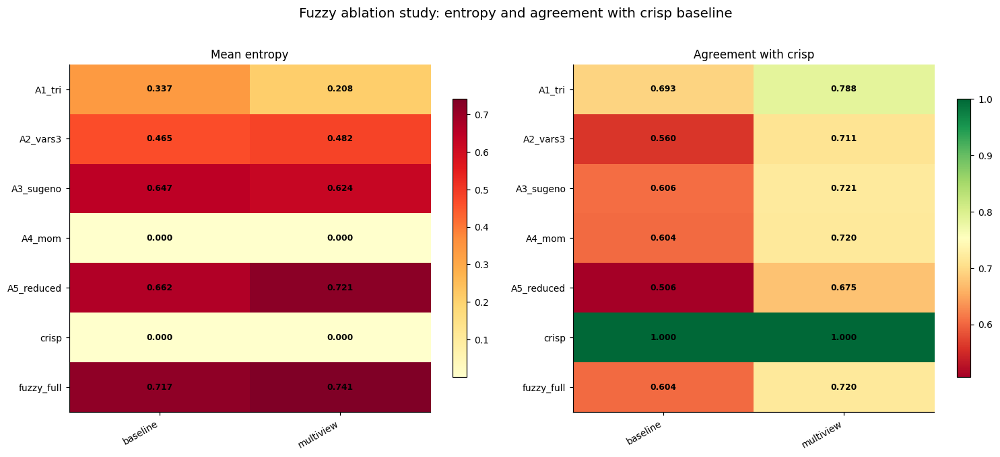

In [42]:
# Fig.18: Ablation heatmap — entropy and agreement with crisp
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, metric, title, cmap in [
    (axes[0], "mean_entropy", "Mean entropy", "YlOrRd"),
    (axes[1], "agreement_with_crisp", "Agreement with crisp", "RdYlGn"),
]:
    pivot = ablation_table.pivot_table(index="method", columns="variant", values=metric, aggfunc="mean")
    im = ax.imshow(pivot.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, rotation=30, ha="right", fontsize=9)
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index, fontsize=9)
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            v = pivot.values[i, j]
            if np.isfinite(v): ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8, fontweight="bold")
    ax.set_title(title, fontsize=11); plt.colorbar(im, ax=ax, shrink=0.8)
plt.suptitle("Fuzzy ablation study: entropy and agreement with crisp baseline", fontsize=13, y=1.02)
plt.tight_layout(); plt.savefig("results/figures/fig18_fuzzy_ablation_heatmap.png", dpi=300, bbox_inches="tight"); plt.show()

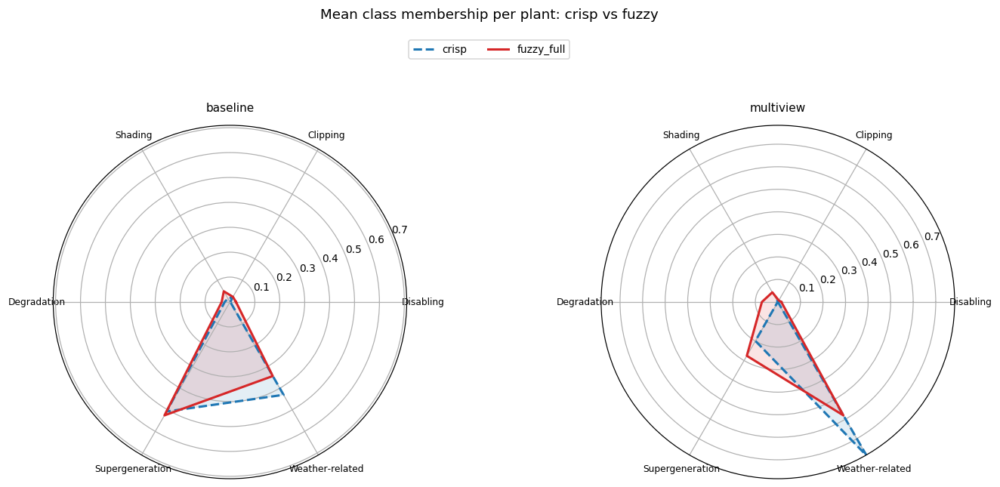

In [43]:
# Fig.19: Radar chart — mean class membership, crisp vs fuzzy
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), subplot_kw=dict(polar=True))
fig.subplots_adjust(top=0.78, bottom=0.05, wspace=0.55)
short_labels = ["Disabling", "Clipping", "Shading", "Degradation", "Supergeneration", "Weather‑related"]
for ax, variant in zip(axes, VARIANTS):
    for cfg_name, color, ls in [("crisp", "tab:blue", "--"), ("fuzzy_full", "tab:red", "-")]:
        means = []
        for seed in SEEDS:
            key = (variant, cfg_name, seed)
            if key not in all_results: means.append(np.zeros(len(CLASS_NAMES))); continue
            ps = all_results[key]["plant_summary"]
            means.append([ps[c].mean() if c in ps.columns else 0.0 for c in CLASS_NAMES])
        means_arr = np.array(means).mean(0)
        angles = np.linspace(0, 2*np.pi, len(CLASS_NAMES), endpoint=False).tolist(); angles += angles[:1]
        means_closed = list(means_arr) + [means_arr[0]]
        ax.plot(angles, means_closed, color=color, ls=ls, lw=2, label=cfg_name)
        ax.fill(angles, means_closed, color=color, alpha=0.12)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(short_labels, fontsize=8)
    ax.set_ylim(0, max(means_arr.max()*1.35, 0.1))
    ax.set_title(variant, fontsize=10, pad=12)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, 0.91))
fig.suptitle("Mean class membership per plant: crisp vs fuzzy", fontsize=12, y=0.96)
plt.savefig("results/figures/fig19_fuzzy_radar.png", dpi=300, bbox_inches="tight"); plt.show()

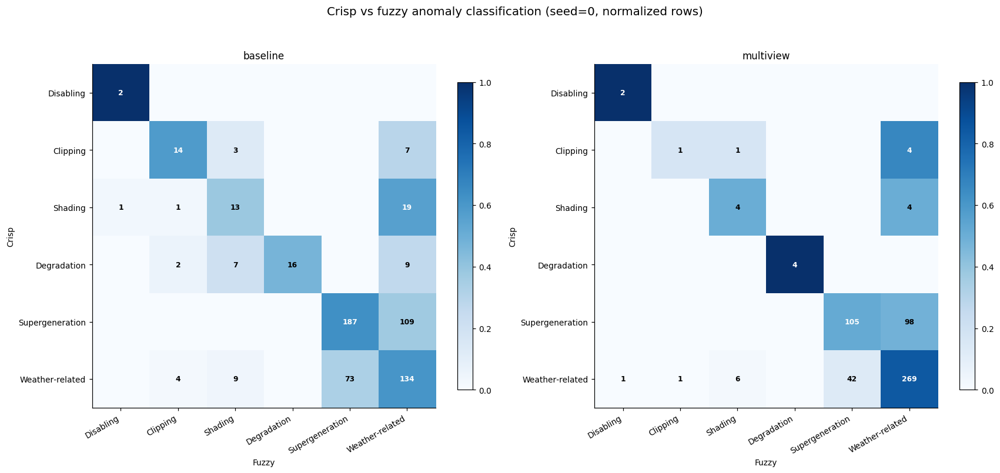

In [44]:
# Fig.20: Confusion matrix — crisp vs fuzzy (seed=0)
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, variant in zip(axes, VARIANTS):
    ck = (variant, "crisp", 0); fk = (variant, "fuzzy_full", 0)
    if ck not in all_results or fk not in all_results: continue
    cl = all_results[ck]["memberships"].values.argmax(1)
    fl = all_results[fk]["memberships"].values.argmax(1)
    cm = confusion_matrix(cl, fl, labels=list(range(6)))
    cm_n = cm.astype(float) / cm.sum(1, keepdims=True).clip(1)
    im = ax.imshow(cm_n, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(6)); ax.set_xticklabels(short_labels, rotation=30, ha="right", fontsize=9)
    ax.set_yticks(range(6)); ax.set_yticklabels(short_labels, fontsize=9)
    ax.set_xlabel("Fuzzy"); ax.set_ylabel("Crisp"); ax.set_title(variant, fontsize=11)
    for i in range(6):
        for j in range(6):
            if cm[i,j] > 0:
                ax.text(j, i, str(cm[i,j]), ha="center", va="center", fontsize=8,
                        color="white" if cm_n[i,j] > 0.5 else "black", fontweight="bold")
    plt.colorbar(im, ax=ax, shrink=0.8)
plt.suptitle("Crisp vs fuzzy anomaly classification (seed=0, normalized rows)", fontsize=13, y=1.02)
plt.tight_layout(); plt.savefig("results/figures/fig20_crisp_vs_fuzzy_confusion.png", dpi=300, bbox_inches="tight"); plt.show()

### 8.4. Saving results


In [45]:
# Save to xlsx and cache
import pickle, os
os.makedirs("results/figures", exist_ok=True)

ablation_table.to_csv("results/fuzzy_ablation_metrics.csv", index=False)

slim = {}
for key, val in all_results.items():
    slim[key] = dict(memberships=val["memberships"], plant_summary=val["plant_summary"],
                     config=val["config"], n_events=val["n_events"])
with open("results/cache/fuzzy_comparison.pkl", "wb") as f:
    pickle.dump(slim, f)

print(f"Saved. Total configurations: {len(all_results)}")

Saved. Total configurations: 70


### 8.5. Conclusions

1. **Cross-seed stability**: fuzzy classification with the multiview model achieves stability of 0.82 versus 0.65 for crisp classification — fuzzy logic smooths variability across runs.
2. **A1 (triangular functions)**: the highest agreement with crisp (0.71–0.73), but lower entropy — triangular functions are closer to hard thresholds.
3. **A4 (mean-of-max)**: confirms that soft defuzzification (centroid) adds information: entropy of 0.67–0.72 versus 0.00.
4. **A5 (reduced rule base)**: the largest deviation from crisp (0.53–0.59) — overlapping rules contribute meaningful information.
5. **Crisp–fuzzy agreement of ~61–63%**: approximately one-third of events change class when switching to fuzzy logic.


## 9. SPS vs Kalman filter: comparison of final model outputs

STGNN training, anomaly events, and seeds are fixed; only the β1 estimator changes. Therefore, metric differences are attributable to the estimator rather than the neural network. Three levels of final output are compared:

| Level | Objects | Partition | Features |
|---|---|---|---|
| Final evidence | plants | `fuse_evidence` label (STGNN + estimator) | STGNN score/exceedance fraction, train/test β1, Δβ1, interval widths, regime changes |
| Diagnostic clusters | plants | K-Means on the same features (k selected by Silhouette) | same |
| Anomaly clusters | events | K-Means (as in section 6) | `ANOMALY_FEATURES` + β1 at the event time / training β1 |

**Metrics** (as in `pv_clustering`): Silhouette ↑, Davies–Bouldin ↓, Calinski–Harabasz ↑ — mean ± std across STGNN seeds; **ARI (seeds)** — mean pairwise ARI between partitions across seeds (events are compared using the most probable plant class); **ARI (init)** — K-Means initialization stability (`stability_ARI_5seeds`); **ARI SPS↔Kalman** — agreement between the final partitions of the two estimators.

Silhouette, DB, and CH are internal indices computed in each estimator's own feature space: they indicate how clearly the final groups are separated, not which estimator is “true.”


In [46]:
# Both estimators use the same D, C, runs from section 5 (results cached in results/cache/estimator_*.pkl)
import os
os.makedirs("results/figures", exist_ok=True)
precomputed = {}
if A is not None and A.get("estimator", "sps") in ("sps", "kalman"):   # estimator already computed in section 5
    precomputed[A.get("estimator", "sps")] = dict(periods=A["sps_periods"], split=A["sps_split"],
                                                  cluster=A["sps_cluster"], daily=A.get("est_daily"))
cmp_res = est_cmp.compare_estimators(D, C, runs, estimators=("sps", "kalman"), precomputed=precomputed,
                                     cache_dir="results/cache", variant="multiview", kalman_cfg=KALMAN_CFG)
cmp_table = cmp_res["table"]
cmp_res["wide"]

[compare] running estimator: kalman


,Level,Estimator,k,N,Silhouette,Davies–Bouldin,Calinski–Harabasz,ARI (seeds),ARI (init),ARI SPS↔Kalman
0,Final evidence (plants),SPS,5,60,0.007,1.242,17.042,0.971,NaN,0.381
1,Diagnostic plant clusters,SPS,2,60,0.810,0.124,40.676,1.000,0.859,1.000
2,Anomaly event clusters,SPS,6,542,0.375,1.040,194.684,0.709,0.865,0.985
3,Final evidence (plants),Kalman,5,60,0.010,1.735,8.138,0.989,NaN,0.381
4,Diagnostic plant clusters,Kalman,2,60,0.772,0.150,25.331,1.000,0.788,1.000
5,Anomaly event clusters,Kalman,6,542,0.418,0.906,217.026,0.685,0.932,0.985


,Level,Estimator,k,N,Silhouette,Davies–Bouldin,Calinski–Harabasz,ARI (seeds),ARI (init),ARI SPS↔Kalman
0,Final evidence (plants),SPS,5,60,0.007,1.242,17.042,0.971,nan,0.381
1,Diagnostic plant clusters,SPS,2,60,0.810,0.124,40.676,1.000,0.859,1.000
2,Anomaly event clusters,SPS,6,542,0.375,1.040,194.684,0.709,0.865,0.985
3,Final evidence (plants),Kalman,5,60,0.010,1.735,8.138,0.989,nan,0.381
4,Diagnostic plant clusters,Kalman,2,60,0.772,0.150,25.331,1.000,0.788,1.000
5,Anomaly event clusters,Kalman,6,542,0.418,0.906,217.026,0.685,0.932,0.985


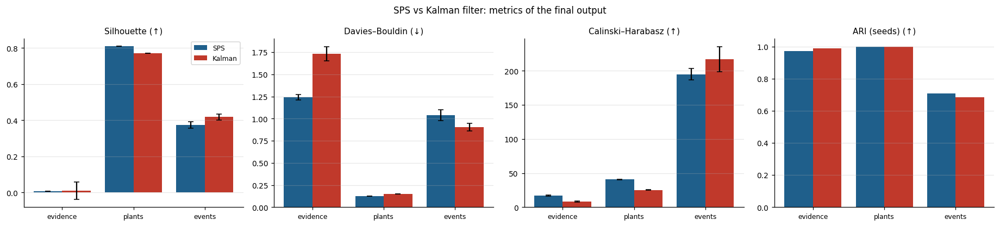

In [47]:
# Table highlighting the best estimator at each level
def _hl(df):
    styles = pd.DataFrame("", index=df.index, columns=df.columns)
    for lvl, g in df.groupby("Level"):
        for col, how in (("Silhouette", "max"), ("Davies–Bouldin", "min"), ("Calinski–Harabasz", "max"), ("ARI (seeds)", "max")):
            v = g[col].astype(float)
            if v.notna().sum() >= 2 and v.nunique() > 1:
                styles.loc[v.idxmax() if how == "max" else v.idxmin(), col] = "font-weight:bold; background-color:#dff0d8"
    return styles
display(cmp_res["wide"].style.apply(_hl, axis=None).format(precision=3))
fig = est_cmp.plot_comparison(cmp_table, "results/figures/fig21_sps_vs_kalman_metrics.png"); plt.show()

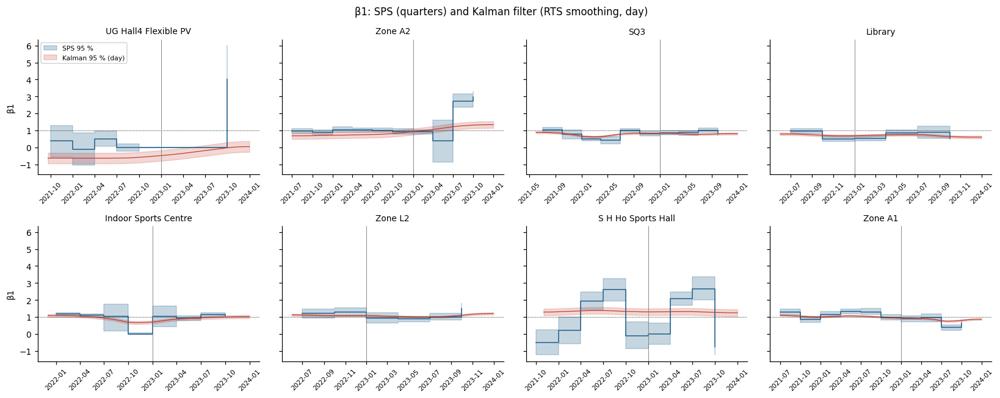

In [48]:
# β1 trajectories for plants with the largest estimator disagreement (quarters: SPS; days: Kalman)
est_sps, est_kf = cmp_res["raw"]["sps"]["est"], cmp_res["raw"]["kalman"]["est"]
d = (est_sps["split"].set_index("plant")["b1_change_pct"] - est_kf["split"].set_index("plant")["b1_change_pct"]).abs()
pick = list(d.sort_values(ascending=False).dropna().index[:8])
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for ax, p in zip(axes.ravel(), pick):
    g = est_sps["periods"][est_sps["periods"].plant == p]
    ax.fill_between(g["period"], g["b1_lo"], g["b1_hi"], step="post", alpha=.25, color="#1f5f8b", label="SPS 95 %")
    ax.step(g["period"], g["theta_b1_Pexp"], where="post", color="#1f5f8b", lw=1)
    if est_kf.get("daily") is not None:
        k = est_kf["daily"][est_kf["daily"].plant == p]
        z = KALMAN_CFG.z
        ax.fill_between(k["day"], k["b1_Pexp"] - z * k["sd_b1_Pexp"], k["b1_Pexp"] + z * k["sd_b1_Pexp"],
                        alpha=.2, color="#c0392b", label="Kalman 95 % (day)")
        ax.plot(k["day"], k["b1_Pexp"], color="#c0392b", lw=.8)
    ax.axhline(1, color="k", lw=.6, ls=":"); ax.axvline(pd.Timestamp(BOUNDARY), color="grey", lw=.6)
    ax.set_title(p, fontsize=9); ax.tick_params(axis="x", rotation=45, labelsize=7)
axes[0, 0].legend(fontsize=7); axes[0, 0].set_ylabel("β1"); axes[1, 0].set_ylabel("β1")
fig.suptitle("β1: SPS (quarters) and Kalman filter (RTS smoothing, day)")
fig.tight_layout(); fig.savefig("results/figures/fig22_sps_vs_kalman_b1.png", dpi=300, bbox_inches="tight"); plt.show()

### 9.1. Export to LaTeX


In [49]:
from IPython.display import FileLink
TEX_PATH = "results/sps_vs_kalman_metrics.tex"
tex = est_cmp.to_latex(cmp_table, TEX_PATH, with_std=True)
cmp_table.to_csv("results/sps_vs_kalman_metrics.csv", index=False)
print(tex)
display(est_cmp.download_link(TEX_PATH, "Download LaTeX table (sps_vs_kalman_metrics.tex)"))
display(FileLink(TEX_PATH))   # the file is also saved to results/ (on Kaggle: Output tab)

% requires \usepackage{booktabs}; Cyrillic: \usepackage[T2A]{fontenc}, \usepackage[utf8]{inputenc}, \usepackage[russian]{babel}
\begin{table}[ht]
\centering
\small
\caption{Comparison of SPS and the Kalman filter on the final model output (Silhouette $\uparrow$, Davies--Bouldin $\downarrow$, Calinski--Harabasz $\uparrow$, ARI $\uparrow$; mean $\pm$ std over STGNN seeds)}
\label{tab:sps_vs_kalman}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llrrccccc}
\toprule
Level & Estimator & $k$ & $N$ & Silhouette $\uparrow$ & Davies--Bouldin $\downarrow$ & Calinski--Harabasz $\uparrow$ & ARI (seeds) $\uparrow$ & ARI SPS--Kalman \\
\midrule
Evidence & SPS & 5 & 60 & $0.007 \pm 0.001$ & $\mathbf{1.242 \pm 0.032}$ & $\mathbf{17.042 \pm 0.567}$ & $0.971$ & $0.381$ \\
 & Kalman & 5 & 60 & $\mathbf{0.010 \pm 0.048}$ & $1.735 \pm 0.080$ & $8.138 \pm 1.103$ & $\mathbf{0.989}$ &  \\
\midrule
Plant clusters & SPS & 2 & 60 & $\mathbf{0.810 \pm 0.000}$ & $\mathbf{0.124 \pm 0.000}$ & $\mathbf{40.676 \pm 0.253}

/kaggle/working/results/sps_vs_kalman_metrics.tex

## 10. Semi-synthetic validation (frozen weights)

The real HKUST fleet time series (weather, measurement noise, and graph connections between plants) are preserved; events with **exact ground-truth labels** (plant, start, end, strength, type, and true energy loss) are injected into the test period (from `BOUNDARY`). The training period remains unchanged.

**Frozen weights.** STGNN is trained only on real data (section 5) and then frozen: `requires_grad=False`, `fit()` and `online_fine_tune()` are blocked, and calibration thresholds are taken from the training period. The SHA-256 weight fingerprint is checked before and after the entire evaluation (the “Frozen-weight integrity” table). Each semi-synthetic realization is compared against **the same** frozen STGNN on clean data, so only *new* detections are counted.

**Scenarios ↔ model anomaly classes** (`pv_clustering.ANOMALY_CLASSES` = `pv_fuzzy.CLASS_NAMES`):

| Scenario | Injection | Expected class |
|---|---|---|
| complete daytime shutdown | $P=0$ during daylight hours | C0 “Disabling / zero generation” |
| clipping | $P=\min(P,(1-s)\,P_{\max})$, clear days | C1 “Power limitation” |
| partial shading | $P\cdot(1-s)$ during 07–10 and 15–18 h windows | C2 “Partial shading” |
| partial power loss at one plant | $P\cdot(1-s)$ | C3 “Gradual loss” |
| supergeneration / outlier | $P\cdot(1+s)$ | C4 “Supergeneration / data outlier” |
| deviation under low irradiance | $P\cdot(1-s)$ when $k_t<0.45$ | C5 “Weather-related deviation” |
| fleet-wide GHI shift | $G\cdot(1-s)$ (pyranometer soiling), recompute $P_{exp}$ | C4 ($P>P_{exp}$) |
| gradual degradation | linear trend $P\cdot(1-s\,\tau)$ until the end of the test | C3; assessed using SPS / Kalman |

**Strengths:** 5, 15, 40%. **Durations:** 1–2 steps (noise-rejection control), one day, one week. **Placement:** plants from different technical clusters and **cohorts** (stratified by “cohort × cluster”), daily weather (clear / variable / overcast), 3 placement seeds; **5 frozen models** (all training seeds in `train_seeds`, as for real data) for all semi-synthetic protocols (sections 10–16, 18, 20); event-free control plants for false alarms, at least one per cohort.

**Cohorts and operating periods** (`D["ca"].cohorts`, as in the graph and STGNN): cohort 1 — 2021–2023, cohort 2 — from 2022, cohort 3 — 2023 only (no training-period data). Plant eligibility is based on coverage within its **own** operating period; events are placed only during operation and no earlier than the end of STGNN cold start (`window` + 168 h of calibration after commissioning); the degradation trend reaches strength $s$ at the plant's final operating hour (decommissioning). Degradation is injected only into cohorts 1–2: cohort 3 has no training period for train/test comparison using SPS or the Kalman filter.

**Metrics:** event precision, recall, and $F_1$; detection delay; false alarms on control plants (per 1000 h); minimum detectable loss (MDL); response of $\hat\eta$ and the physical residual $z_{phys}$; change in $b_1$ from SPS and the Kalman filter; fraction of cases in which fuzzy inference assigns the highest membership to the injected type.

This section is independent: if `pv_semisynth_gen.py` / `pv_semisynth_eval.py` are not available, the cells below are skipped and the rest of the notebook works unchanged.


In [50]:
# 10.0 Import (optional section: the notebook works as before without these files)
try:
    import pv_semisynth_gen as ssg, pv_semisynth_eval as sse
    SEMISYNTH_OK = True
except ImportError as exc:
    SEMISYNTH_OK = False
    print("section 10 skipped:", exc)

PLACEMENT_SEEDS = [0, 1, 2]          # random event placements
MODEL_SEEDS = train_seeds[:2]        # frozen models (STGNN training seeds)
SS_OUT, SS_FIG = "results/semisynth", "results/figures"
if SEMISYNTH_OK:
    display(ssg.scenario_table())

,Scenario,Key,Level,Injection,Expected class
0,Full-day outage,outage,plant,P = 0 during the event,Outage / zero generation
1,Power limitation (clipping),clipping,plant,"P = min(P, (1−s)·P99) — limitation of the uppe...",Power limitation (clipping / curtailment)
2,Partial shading (morning / evening),shading,plant,P ·= (1−s) in the 7–10 h or 15–18 h window,Partial shading (time of day)
3,Partial power loss,partial_loss,plant,P ·= (1−s) for one plant,Gradual loss (soiling / degradation)
4,Overgeneration / data spike,overgen,plant,P ·= (1+s) — meter error / data spike,Overgeneration / data spike (P > P_exp)
5,Deviation at low irradiance,lowlight,plant,P ·= (1−s) only in overcast hours (kt < 0.45),Weather-driven deviation (low irradiance)
6,Fleet-wide GHI shift,ghi_shift,fleet,GHI_meas ·= (1−s) for the whole fleet — pyrano...,Overgeneration / data spike (P > P_exp)
7,Gradual degradation,degradation,trend,P ·= 1 − s·(t − t₀)/(t₁ − t₀) — linear growth ...,Gradual loss (soiling / degradation)


### 10.1. Frozen models

Weight sources are checked in this order: (1) checkpoint `results/cache/stgnn_frozen_multiview_<seed>.pt`, saved by `run_pipeline` after calibration and **before** online fine-tuning; (2) if no checkpoint exists (the old `run_*.pkl` cache stores results only), the model is trained once on real data with the same hyperparameters as in section 5 and saved. Subsequently, weights are read only.


In [51]:
if SEMISYNTH_OK:
    ss_models = sse.frozen_models(D, C, seeds=MODEL_SEEDS, variant="multiview", cache_dir="results/cache",
                                  window=48, hidden=32, epochs=15, train_stride=1, device=DEVICE)
    for s, m in ss_models.items():
        print(f"seed {s}: {m.source}, sha256[:16] = {m.fingerprint()[:16]}")

15:35:22 [semisynth] model seed 0: checkpoint stgnn_frozen_multiview_0.pt, weights sha256[:16] = fa6d719b0b842f57
15:35:22 [semisynth] model seed 1: checkpoint stgnn_frozen_multiview_1.pt, weights sha256[:16] = 9828b1fe35771eaf
seed 0: checkpoint stgnn_frozen_multiview_0.pt, sha256[:16] = fa6d719b0b842f57
seed 1: checkpoint stgnn_frozen_multiview_1.pt, sha256[:16] = 9828b1fe35771eaf


### 10.2. Generation and evaluation

An event plan is built for each placement seed, and each realization is then processed by all frozen models. Detection (STGNN) is shared by both estimators; $b_1$ and final degradation evidence are computed separately for **SPS** and the **Kalman filter** (`KALMAN_CFG` from the import cell). Results are cached in `results/semisynth/semisynth_result.pkl`.


In [52]:
if SEMISYNTH_OK:
    A_ss = A if (isinstance(A, dict) and "anom" in A) else None      # K-Means anomaly clusters from section 5
    plan0 = ssg.plan_semisynthetic(D, C, seed=PLACEMENT_SEEDS[0])
    print("plant roles:", plan0.roles.value_counts().to_dict())
    display(plan0.summary())
    display(plan0.roles_by_cohort())             # plant roles by cohort
    ss_res = sse.run_semisynthetic(D, C, ss_models, placement_seeds=PLACEMENT_SEEDS,
                                   estimators=("sps", "kalman"), A=A_ss, kalman_cfg=KALMAN_CFG, cache_dir=SS_OUT)
    display(ss_res.tables["integrity"])          # weights unchanged: unchanged = True

plant roles: {'unused': 39, 'target': 12, 'control': 6, 'degradation': 3}


duration,day,short,trend,week
scenario,,,,
clipping,3,3,0,3
degradation,0,0,3,0
ghi_shift,3,3,0,3
lowlight,3,3,0,3
outage,1,1,0,1
overgen,3,3,0,3
partial_loss,3,3,0,3
shading,3,3,0,3


Role,control,degradation,target,unused
Cohort,,,,
Cohort 1 (2021–2023),2,2,5,26
Cohort 2 (from 2022),2,1,5,11
Cohort 3 (2023 only),2,0,1,2
Insufficient data,0,0,1,0


15:35:23 [semisynth] clean scoring, model seed 0
15:35:28 [semisynth] clean scoring, model seed 1
15:35:37 [semisynth] placement 0: 60 effective events, targets=12, controls=6
15:35:48 [semisynth] placement 0: b1 estimators ['sps', 'kalman']
15:36:03 [semisynth] placement 1: 56 effective events, targets=12, controls=6
15:36:14 [semisynth] placement 1: b1 estimators ['sps', 'kalman']
15:36:26 [semisynth] placement 2: 58 effective events, targets=12, controls=6
15:36:37 [semisynth] placement 2: b1 estimators ['sps', 'kalman']
15:36:48 [semisynth] weights unchanged: True


,model_seed,source,sha256_16,unchanged
0,0,checkpoint stgnn_frozen_multiview_0.pt,fa6d719b0b842f57,True
1,1,checkpoint stgnn_frozen_multiview_1.pt,9828b1fe35771eaf,True


### 10.3. Tables


In [53]:
if SEMISYNTH_OK:
    sse.show(ss_res)

**Summary by scenario (day + week)**

,Scenario,N (day+week),Recall,Precision,F1,"Delay, h",Short events cut (1–2 steps)
0,Full-day outage,12,0.250,1.000,0.400,3.000,1.000
1,Power limitation (clipping),28,0.000,—,—,—,1.000
2,Partial shading (morning / evening),36,0.000,—,—,—,1.000
3,Partial power loss,34,0.000,—,—,—,1.000
4,Overgeneration / data spike,36,0.250,1.000,0.400,4.000,1.000
5,Deviation at low irradiance,34,0.000,—,—,—,1.000
6,Fleet-wide GHI shift,36,0.056,0.981,0.105,79.500,1.000


**Detection: scenario × strength × duration**

,Scenario,"s, %",Duration,N,Recall,Precision,F1,Raw hit,"Delay, h (median)",Δη̂,Δz_phys,"True loss, %",Fuzzy: correct type,Fuzzy (true interval),Crisp rules,K-Means cluster
0,Full-day outage,100,1–2 steps,6,0.000,—,0.000,0.333,—,0.000,1.522,100.000,—,0.667,—,—
1,Full-day outage,100,day,6,0.000,—,0.000,0.333,—,-0.512,0.187,100.000,—,1.000,—,—
2,Full-day outage,100,week+,6,0.500,1.000,0.667,0.500,3.000,-0.338,-0.019,100.000,1.000,1.000,1.000,0.000
3,Power limitation (clipping),5,1–2 steps,6,0.000,—,0.000,0.000,—,0.001,-0.583,5.922,—,0.000,—,—
4,Power limitation (clipping),15,1–2 steps,6,0.000,—,0.000,0.000,—,0.000,-0.722,8.690,—,0.000,—,—
5,Power limitation (clipping),40,1–2 steps,6,0.000,—,0.000,0.167,—,-0.000,-1.679,32.253,—,0.000,—,—
6,Power limitation (clipping),5,day,4,0.000,—,0.000,0.000,—,-0.000,-0.273,2.824,—,0.000,—,—
7,Power limitation (clipping),15,day,6,0.000,—,0.000,0.000,—,-0.148,-2.780,26.135,—,0.000,—,—
8,Power limitation (clipping),40,day,6,0.000,—,0.000,0.000,—,-0.016,-0.756,26.402,—,0.000,—,—
9,Power limitation (clipping),5,week+,2,0.000,—,0.000,0.000,—,0.000,-0.190,1.892,—,0.000,—,—


**Minimum detectable loss (MDL)**

,Scenario,Duration,"MDL (recall ≥ 0.5), %","MDL interp., %","MDL (recall ≥ 0.8), %"
0,Power limitation (clipping),1–2 steps,—,—,—
1,Power limitation (clipping),day,—,—,—
2,Power limitation (clipping),week+,—,—,—
3,Partial shading (morning / evening),1–2 steps,—,—,—
4,Partial shading (morning / evening),day,—,—,—
5,Partial shading (morning / evening),week+,—,—,—
6,Partial power loss,1–2 steps,—,—,—
7,Partial power loss,day,—,—,—
8,Partial power loss,week+,—,—,—
9,Overgeneration / data spike,1–2 steps,—,—,—


... (22 outputs left out)

**Degradation by cohort**

,Estimator,Cohort,N,"Exp. Δb1 (test), %","Est. Δb1 (test), %","Bias, p.p.",Evidence «β1 decrease»
0,Kalman,Cohort 1 (2021–2023),12,-8.081,-5.926,2.155,0.500
1,Kalman,Cohort 2 (from 2022),6,-13.935,-8.168,5.767,0.333
2,SPS,Cohort 1 (2021–2023),12,-8.081,-1.446,6.635,0.333
3,SPS,Cohort 2 (from 2022),6,-13.935,-2.124,11.811,0.667


**Frozen-weight check**

,model_seed,source,sha256_16,unchanged
0,0,checkpoint stgnn_frozen_multiview_0.pt,fa6d719b0b842f57,True
1,1,checkpoint stgnn_frozen_multiview_1.pt,9828b1fe35771eaf,True


### 10.4. Figures

Recall by strength and duration; delay and response of $\hat\eta$ / $z_{phys}$; fuzzy inference matrix; $\Delta b_1$ (SPS and Kalman) and gradual degradation; examples of injected events.


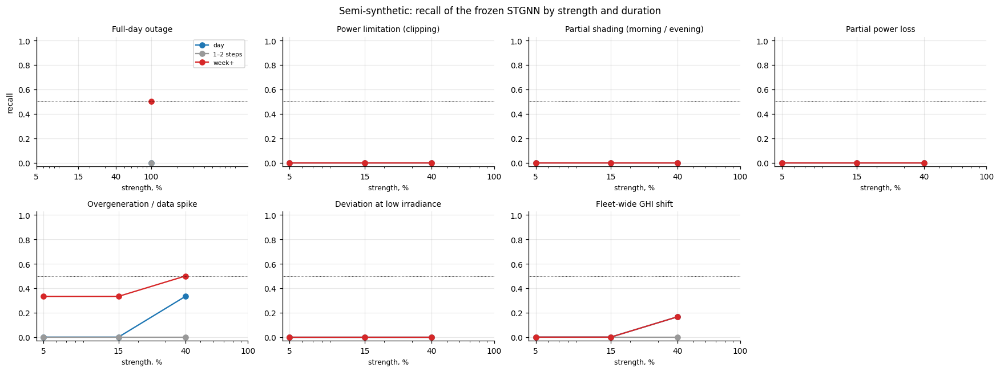

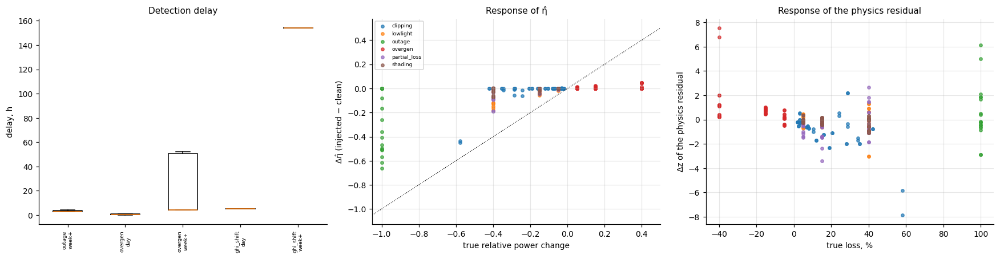

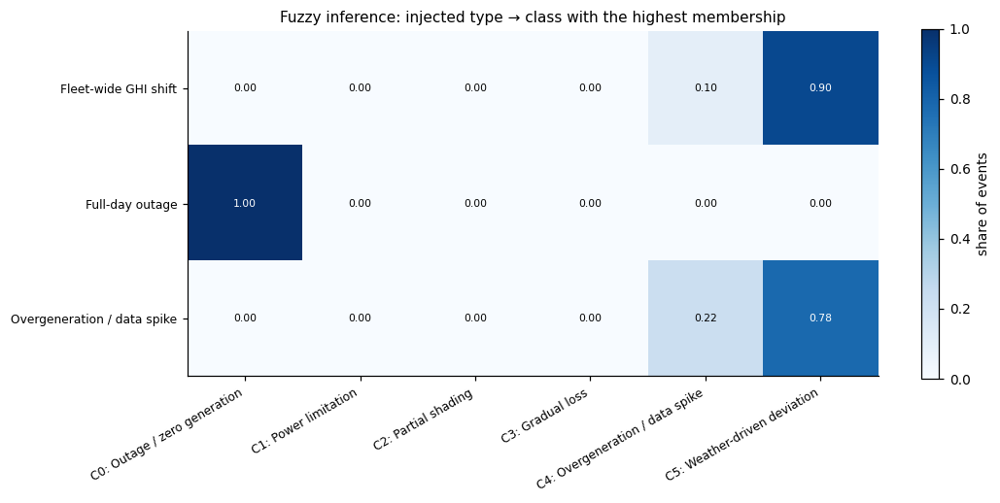

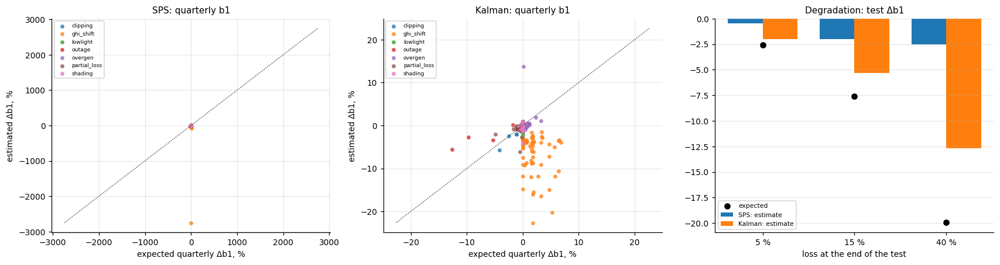

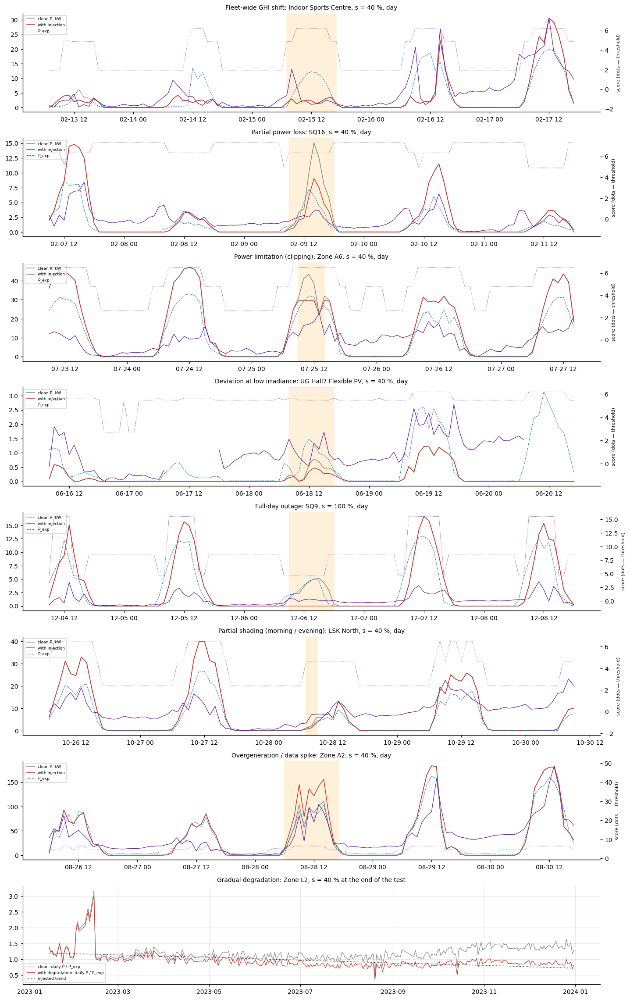

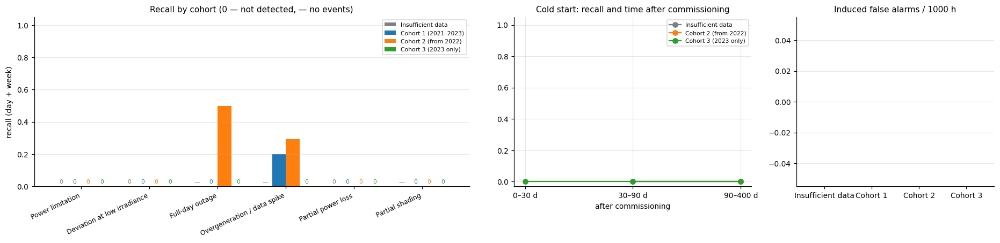

In [54]:
if SEMISYNTH_OK:
    ss_figs = sse.plot_all(ss_res, SS_FIG)
    for f in ss_figs.values():
        display(f)
    plt.close("all")

### 10.5. Export to LaTeX

Each table is saved as a separate `.tex` file (booktabs), and all tables are combined in `semisynth_tables.tex`; `.csv` files are stored alongside them. Captions and tables are in English; preamble: `\usepackage{booktabs,graphicx,longtable,array}`.


In [55]:
if SEMISYNTH_OK:
    from IPython.display import FileLink
    ss_tex = sse.export_latex(ss_res, SS_OUT)
    ss_zip = sse.zip_outputs(SS_OUT, SS_FIG)
    display(sse.download_link(ss_tex["all"], "Download all LaTeX tables (semisynth_tables.tex)"))
    display(sse.download_link(ss_zip, "Download archive: .tex, .csv and figures (semisynth_results.zip)"))
    display(FileLink(ss_tex["all"]))   # also saved to results/semisynth/ (on Kaggle: Output tab)
    print(open(ss_tex["estimators"], encoding="utf-8").read() if "estimators" in ss_tex else "")

/kaggle/working/results/semisynth/semisynth_tables.tex

\begin{table}[ht]
\centering
\small
\caption{Final comparison of the model with SPS and with the Kalman filter on semi-synthetic data}
\label{tab:semisynth_estimators}
{%
\begin{tabular}{lrrrrr}
\toprule
Estimator & \shortstack{F1 STGNN \\ (mean over \\ scenarios)} & \shortstack{Sensitivity \\ $\Delta$b1 \\ (quarters)} & \shortstack{MAE $\Delta$b1, \\ p.p.} & \shortstack{MAE $\Delta$b1 of \\ degradation, \\ p.p.} & \shortstack{Degradation \\ detected \\ (evid.)} \\
\midrule
SPS & 0.30 & 0.57 & 0.99 & 8.36 & 0.44 \\
\midrule
Kalman & 0.30 & 0.38 & 0.75 & 3.36 & 0.44 \\
\bottomrule
\end{tabular}}
\end{table}



### 10.6. How to interpret the results

- **Detection is identical for SPS and Kalman**: both use the same frozen STGNN; only $b_1$, train/test regions, and the final “$\beta_1$ decrease” evidence differ.
- **Noise rejection**: a low detection rate is desirable for events lasting 1–2 steps (the “Short events rejected” column); with `min_len = 3`, such events should not be extracted.
- **GHI shift**: with $G\cdot(1-s)$, $P/P_{exp}$ increases as expected, but in the regression $y=b_0+b_1P_{exp}+b_2T_{cell}+b_3(1-k_t)$ the intercept and the coefficient of $T_{cell}$ (which correlates with GHI) absorb part of the effect, so the estimated $\Delta b_1$ may even have the opposite sign. In the Kalman filter, a nearly constant $b_2$ propagates this distortion to all quarters. This is a property of the regression model, not a generator error.
- **Fuzzy inference**: the “Correct type” fraction indicates whether the injected class receives the highest membership. The `zero_frac high` term in `pv_fuzzy.py` is implemented as a right-shoulder function ($\mu=1$ for `zero_frac` ≥ 0.55; previously, a Gaussian centered at 0.55 gave only ≈ 0.04 at `zero_frac = 1`, causing complete shutdowns to be assigned to C5). Remaining errors involve short events whose detected intervals extend beyond the actual shutdown.
- **Cohorts**: the “By cohort” and “Cold start” tables show whether frozen STGNN detects events at later-commissioned plants. Cohort 3 has no training windows, so `UnsupervisedSTGNN.calibrate` obtains error-normalization statistics ($\mu,\ \sigma$) for its nodes as the median across plants in the same technical cluster (`borrow_error_stats`; fleet-wide if no cluster is available), and takes the threshold from the same cluster; the z-score and threshold are thus on the same scale. Each node's normalization source is saved in `pipe.stats_source` and the checkpoint; old checkpoints are corrected when loaded.
- **MDL** is the smallest strength with recall ≥ 0.5 (with interpolation on a logarithmic scale); “—” means that even 40% is not detected reliably.


## 11. Detection sensitivity: threshold $q$, min_len, and the source of $\hat\eta$

This section tests two detection rules using **the same** frozen models and **the same** semi-synthetic event placements as section 10 (`ss_res.plans`). Weights remain unchanged (SHA-256 before and after).

1. **Threshold and event length**: quantile $q \in \{0.95, 0.97, 0.98, 0.99, 0.995, 0.998, 0.999\}$ at `min_len = 3`, and `min_len` $\in \{1, 2, 3, 4, 6\}$ at $q = 0.995$.
2. **Source of $\hat\eta$** in the physical residual $|\hat\eta\,P_{exp}-P|/P_{rated}$. The model predicts $\hat\eta$ from the current 48-hour window; during a long event, that window already contains the anomaly, allowing $\hat\eta$ to “adapt” to it. Variants:

| Variant | $\hat\eta$ at time $t$ |
|---|---|
| current window (model) | as in the model (baseline) |
| 24 h lag | $\hat\eta(t-24\,\text{h})$ — the same hour on the previous day |
| 168 h lag | $\hat\eta(t-168\,\text{h})$ |
| 7-day median, 24 h lag | median daytime $\hat\eta$ over 7 days ending 24 h before $t$ |
| training period | one value per plant: median daytime $\hat\eta$ from calibration windows (cohort 3: technical-cluster median) |

The network is evaluated once on each dataset (calibration windows, clean test, each placement). The physical residual, its normalization ($\mu$, $\sigma$ from calibration windows), thresholds following the `calibrate` rules (node, weather regime, technical cluster), and events are then recomputed for each variant. At the checkpoint's $q$, the “current window” variant reproduces section 10 exactly (the “Reproduction” table).


In [56]:
# 11.0 Imports and parameters (optional section: requires pv_semisynth_sensitivity.py and section 10 results)
try:
    import pv_semisynth_sensitivity as sss
    SENS_OK = bool(globals().get("SEMISYNTH_OK")) and "ss_models" in globals()
    if not SENS_OK:
        print("section 11 skipped: run section 10 first")
except ImportError as exc:
    SENS_OK = False
    print("section 11 skipped:", exc)

SENS_CFG = sss.SensConfig(qs=(0.95, 0.97, 0.98, 0.99, 0.995, 0.998, 0.999), min_lens=(1, 2, 3, 4, 6),
                          grid="cross") if SENS_OK else None      # grid="full": all q x min_len combinations
SENS_OUT, SENS_FIG = "results/sensitivity", "results/figures"
SENS_MODELS = ss_models if SENS_OK else {}                          # the same frozen models as in section 10

### 11.1. Evaluation

Raw network outputs are cached in `results/sensitivity/raw_<seed>_<sha>.pkl`; reruns take minutes. Placements are taken from `ss_res.plans` (or from `results/semisynth/semisynth_result.pkl` if section 10 was loaded from cache).


In [57]:
if SENS_OK:
    _ss = ss_res if "ss_res" in globals() else None
    if _ss is None and os.path.exists(os.path.join(SS_OUT, "semisynth_result.pkl")):
        _ss = pickle.load(open(os.path.join(SS_OUT, "semisynth_result.pkl"), "rb"))
    sens = sss.run_sensitivity(D, C, SENS_MODELS, ss_res=_ss, placement_seeds=PLACEMENT_SEEDS, cfg=SENS_CFG,
                               cache_dir=SENS_OUT)
    print("weights unchanged:", sens.meta["weights_unchanged"])

15:37:02 [sensitivity] placements from section 10: [0, 1, 2]
15:37:07 [sensitivity] model 0: forward passes (calibration, clean test, 3 placements)
15:37:31 [sensitivity] model 1: forward passes (calibration, clean test, 3 placements)
15:39:07 [sensitivity] model 0: grid done (72s)
15:40:17 [sensitivity] model 1: grid done (143s)
15:40:17 [sensitivity] weights unchanged: True
weights unchanged: True


### 11.2. Tables


In [58]:
if SENS_OK:
    sss.show(sens)

**Reproduction of section 10 (recomputation check)**

,Scenario,Section 10,"Recomputed (current, q_ref, min_len_ref)"
0,Power limitation (clipping),0.000,0.000
1,Fleet-wide GHI shift,0.056,0.056
2,Deviation at low irradiance,0.000,0.000
3,Full-day outage,0.250,0.250
4,Overgeneration / data spike,0.250,0.250
5,Partial power loss,0.000,0.000
6,Partial shading (morning / evening),0.000,0.000
7,All,0.065,0.065


**Curve over q (min_len = 3)**

,η̂,q,min_len,Recall,Precision,F1,Raw hit,"Delay, h",Short events cut,"FA controls, /1000 h","Induced FA, /1000 h","Background all plants, /1000 h",R 5 %,R 15 %,R 40 %
0,current window (model),0.950,3,0.162,0.965,0.277,0.495,29.00,0.958,5.815,0.040,5.066,0.048,0.114,0.236
1,current window (model),0.970,3,0.139,0.971,0.242,0.431,29.50,1.000,3.862,0.034,3.339,0.048,0.100,0.194
2,current window (model),0.980,3,0.125,0.973,0.222,0.356,34.50,1.000,2.961,0.045,2.427,0.048,0.071,0.181
3,current window (model),0.990,3,0.088,0.965,0.160,0.306,15.75,1.000,1.954,0.017,1.603,0.032,0.029,0.153
4,current window (model),0.995,3,0.065,0.983,0.121,0.269,4.00,1.000,1.387,0.000,1.033,0.032,0.029,0.097
5,current window (model),0.998,3,0.046,0.934,0.088,0.227,28.75,1.000,1.161,0.011,0.749,0.032,0.029,0.056
6,current window (model),0.999,3,0.042,0.960,0.080,0.204,40.50,1.000,1.082,0.000,0.666,0.016,0.029,0.056
7,lag 24 h,0.950,3,0.171,0.949,0.290,0.472,28.00,0.958,5.787,0.034,5.048,0.016,0.114,0.236
8,lag 24 h,0.970,3,0.162,0.962,0.277,0.440,24.50,1.000,3.896,0.057,3.347,0.048,0.086,0.250
9,lag 24 h,0.980,3,0.144,0.978,0.250,0.370,37.75,1.000,3.018,0.017,2.477,0.048,0.086,0.208


**Curve over min_len (q = 0.995)**

,η̂,q,min_len,Recall,Precision,F1,Raw hit,"Delay, h",Short events cut,"FA controls, /1000 h","Induced FA, /1000 h","Background all plants, /1000 h"
0,current window (model),0.995,1,0.157,0.962,0.270,0.269,15.00,1.0,7.248,0.017,5.571
1,current window (model),0.995,2,0.088,0.975,0.161,0.269,4.75,1.0,2.474,0.000,1.951
2,current window (model),0.995,3,0.065,0.983,0.121,0.269,4.00,1.0,1.387,0.000,1.033
3,current window (model),0.995,4,0.051,0.975,0.097,0.269,3.75,1.0,0.974,0.000,0.734
4,current window (model),0.995,6,0.032,0.964,0.063,0.269,39.00,1.0,0.646,0.000,0.481
5,lag 24 h,0.995,1,0.171,0.953,0.290,0.259,13.25,1.0,7.316,0.023,5.500
6,lag 24 h,0.995,2,0.106,0.959,0.192,0.259,22.50,1.0,2.520,0.017,1.962
7,lag 24 h,0.995,3,0.079,0.940,0.144,0.259,16.75,1.0,1.523,0.017,1.068
8,lag 24 h,0.995,4,0.046,0.904,0.088,0.259,4.00,1.0,1.127,0.006,0.776
9,lag 24 h,0.995,6,0.037,0.904,0.071,0.259,29.25,1.0,0.736,0.006,0.484


**Recall by scenario at q = 0.995, min_len = 3**

,η̂,q,min_len,Recall,Full-day outage,Power limitation (clipping),Partial shading (morning / evening),Partial power loss,Overgeneration / data spike,Deviation at low irradiance,Fleet-wide GHI shift,Δη̂ outage,Δz_phys outage
0,current window (model),0.995,3,0.065,0.250,0.0,0.0,0.0,0.250,0.0,0.056,-0.425,0.084
1,lag 24 h,0.995,3,0.079,0.417,0.0,0.0,0.0,0.278,0.0,0.056,-0.157,1.160
2,lag 168 h,0.995,3,0.051,0.333,0.0,0.0,0.0,0.194,0.0,0.000,0.001,1.604
3,"7-day median, lag 24 h",0.995,3,0.060,0.333,0.0,0.0,0.0,0.222,0.0,0.028,-0.084,1.505
4,training period,0.995,3,0.056,0.333,0.0,0.0,0.0,0.194,0.0,0.028,0.000,1.681


**Operating point at the false-alarm budget of the reference variant**

,η̂,q,min_len,"FA budget, /1000 h",Interpolated,Recall,Precision,F1,"Background all plants, /1000 h","Delay, h",Full-day outage,Power limitation (clipping),Partial shading (morning / evening),Partial power loss,Overgeneration / data spike,Deviation at low irradiance,Fleet-wide GHI shift
0,current window (model),0.995,3,1.387,True,0.065,0.983,0.121,1.033,4.000,0.250,0.000,0.0,0.0,0.250,0.000,0.056
1,lag 24 h,0.996,3,1.387,True,0.063,0.938,0.117,0.910,23.110,0.337,0.000,0.0,0.0,0.238,0.000,0.029
2,lag 168 h,0.995,3,1.387,True,0.051,0.983,0.097,1.005,4.705,0.330,0.000,0.0,0.0,0.194,0.000,0.000
3,"7-day median, lag 24 h",0.995,3,1.387,True,0.062,0.984,0.115,1.092,3.727,0.338,0.002,0.0,0.0,0.224,0.001,0.031
4,training period,0.996,3,1.387,True,0.049,0.976,0.093,0.937,9.468,0.293,0.000,0.0,0.0,0.181,0.000,0.014


### 11.3. Figures

Recall, background alarms, and the recall–false-alarm trade-off versus $q$; the same versus `min_len`; recall by scenario at an equal false-alarm budget.


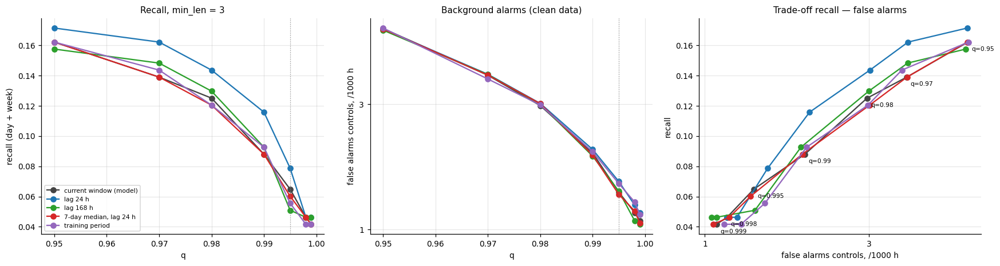

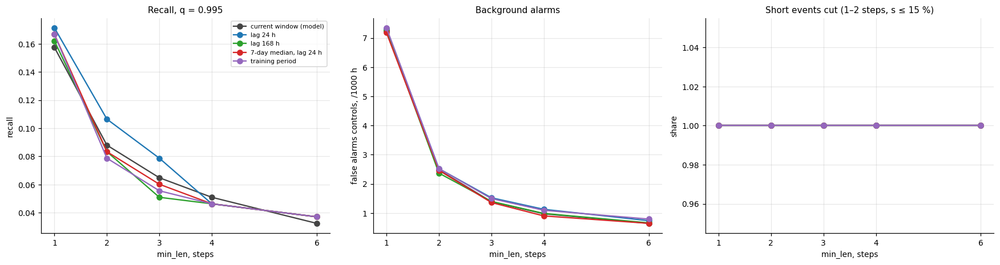

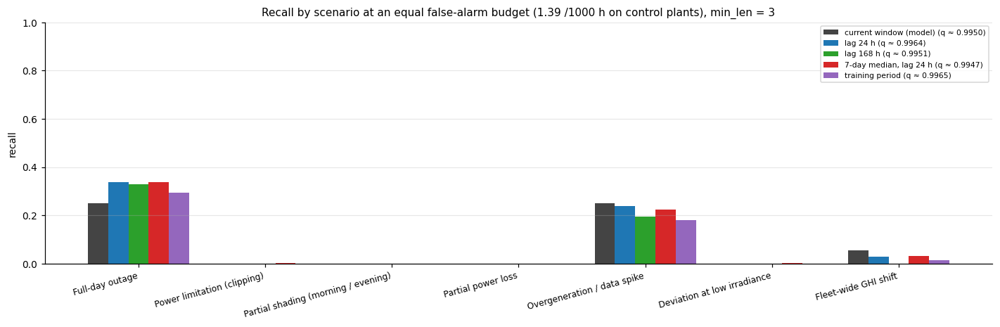

In [59]:
if SENS_OK:
    sens_figs = sss.plot_all(sens, SENS_FIG)
    for f in sens_figs.values():
        display(f)
    plt.close("all")

### 11.4. Export to LaTeX


In [60]:
if SENS_OK:
    sens_tex = sss.export_latex(sens, SENS_OUT)
    sens_zip = sss.zip_outputs(SENS_OUT, SENS_FIG)
    display(sss.download_link(sens_tex["all"], "Download LaTeX tables (sensitivity_tables.tex)"))
    display(sss.download_link(sens_zip, "Download archive: .tex, .csv and figures (sensitivity_results.zip)"))

### 11.5. How to interpret the results

- **Reproduction**: columns should match; otherwise, recomputation is not equivalent to section 10.
- **Curve versus $q$**: lowering $q$ increases recall but also increases background alarms on clean data (“Control FA” refers to control plants; “Background, all plants” refers to all plants). The operating point for the paper is selected according to the acceptable false-alarm count, not maximum semi-synthetic recall (which would tune on test data).
- **min_len**: with `min_len = 1–2`, events lasting 1–2 steps are no longer rejected (the “Short events rejected” column), and false alarms rise sharply.
- **Source of $\hat\eta$**: variants must be compared at the **same false-alarm budget** (the “Operating point” table, “Recall at budget (interpolated)” column). If a lagged or training-period $\hat\eta$ increases recall for shutdowns and partial loss at the same budget, while “Δη̂ shutdown” approaches zero, the baseline model absorbs the anomaly through $\hat\eta$. Otherwise, the cause lies in the reconstruction branch or the threshold.
- The “training period” variant does not account for slow degradation after `BOUNDARY`; this is estimated by $b_1$ (SPS / Kalman), not by the detector.


## 12. Detector corrections: before/after comparison and simple baselines

This section addresses the causes identified in sections 10–11 and evaluates their effects **under the same protocol**: the same frozen models (SHA-256 before and after), the same semi-synthetic event placements (`ss_res.plans`), and the same recall / precision / false-alarm calculations.

| Step | Change | Reason |
|---|---|---|
| S0 | original detector from section 10 (current-window $\hat\eta$, checkpoint $q$, `min_len = 3`) | reference point |
| S1 | $\hat\eta$ = 7-day median with a 24 h lag | anomaly absorption through $\hat\eta$ |
| S2 | `min_len = 2`, $q$ selected on **validation** at the S0 false-alarm budget | threshold and min_len |
| S3 | + “$P \approx 0$ at GHI > 200” rule (OR fusion with STGNN) | missed shutdowns |
| S4 | + calibrated fuzzy rules (clipping, shading, partial loss) | classification errors |

Membership functions are calibrated on **separate** placements (`pv_fuzzy_calibration.CAL_PLACEMENTS`) that do not overlap with evaluation placements. Baselines: a PR threshold rule ($|PR/PR_0-1|$, calibration quantile), **PR+** (hour × month baseline, normalization by technical-cluster peers, causal 30-day rolling median; `pv_prplus`, the same definition as in sections 15, 16, and 18), the “$P\approx0$ at GHI > 200” rule, and Isolation Forest. Comparisons use operating points with the same validation budget and an **equal false-alarm budget** on the clean test (interpolation along the threshold curve).

The effect of the new aggregation (NaN before aggregation, `min_count = 3` out of 4) is shown separately: fractions of zero and missing daytime hours, and bias in partially covered hours under the old zero-filling rule. All tables and figures are in English.


In [61]:
# 12.0 Imports and parameters (optional section: requires pv_fixes_eval.py, pv_fuzzy_calibration.py, pv_preprocess.py)
try:
    import pv_fixes_eval as fx, pv_preprocess as pvp
    FIX_OK = bool(globals().get("SEMISYNTH_OK")) and "ss_models" in globals()
    if not FIX_OK:
        print("section 12 skipped: run section 10 first")
except ImportError as exc:
    FIX_OK = False
    print("section 12 skipped:", exc)

FIX_CFG = fx.FixesConfig(eta_mode="med7d", min_len_after=2, zero_ghi=200.0, zero_min_h=2) if FIX_OK else None
FIX_OUT, FIX_FIG = "results/fixes", "results/figures"
FIX_MODELS = ss_models if FIX_OK else {}          # the same frozen models as in sections 10-11

In [62]:
# 12.1 Aggregation: zero filling before resample (old rule) versus NaN + min_count
AGG_TABLE = None
if FIX_OK and "df_all" in globals():
    _freq = "1h" if tuple(int(x) for x in pd.__version__.split(".")[:2]) >= (2, 2) else "1H"
    _pc = [c for c in df_all.columns if "power" in str(c).lower()]
    _ghi_col = next((c for c in df_all.columns if "irradiance" in str(c).lower()), None)
    _n_exp = {c: 1 for c in globals().get("pv2_cols_list", [])}          # hourly pv2 stations: 1 sample per hour
    AGG_TABLE = pvp.compare_aggregation(df_all, _pc, n_expected=_n_exp, default_n=4,
                                        ghi=df_all[_ghi_col] if _ghi_col else None, min_counts=(4, 3, 2), freq=_freq)
    display(AGG_TABLE.round(2))

,aggregation,daylight hours,"zero hours, %","NaN hours, %","partially covered hours used, %","mean bias of partial hours, %"
0,legacy (zero fill),389640,24.43,0.00,0.03,-49.05
1,min_count=4,389640,1.25,23.20,0.00,NaN
2,min_count=3,389640,1.26,23.19,0.01,NaN
3,min_count=2,389640,1.26,23.19,0.02,NaN


### 12.2. Evaluation

Raw network outputs are loaded from the section 11 cache (`results/sensitivity/raw_<seed>_<sha>.pkl`) and supplemented with validation data; the result is saved to `results/fixes/fixes_result.pkl`.


In [63]:
if FIX_OK:
    _ss = ss_res if "ss_res" in globals() else None
    if _ss is None and os.path.exists(os.path.join(SS_OUT, "semisynth_result.pkl")):
        _ss = pickle.load(open(os.path.join(SS_OUT, "semisynth_result.pkl"), "rb"))
    fx_res = fx.run_fixes(D, C, FIX_MODELS, ss_res=_ss, placement_seeds=PLACEMENT_SEEDS, cfg=FIX_CFG,
                          cache_dir=FIX_OUT, sens_cache_dir="results/sensitivity", aggregation_table=AGG_TABLE)
    print("weights unchanged:", fx_res.meta["weights_unchanged"])

15:40:51 [fixes] placements: [0, 1, 2]
15:41:02 [fixes] model 0: raw outputs of section 11 reused
15:41:04 [fixes] model 1: raw outputs of section 11 reused
15:41:07 [fixes] model 0 S0: q=0.9950 val FA=0.00 test FA=1.36 recall=0.074 (22s)
15:41:09 [fixes] model 0 S1: q=0.9950 val FA=0.00 test FA=1.34 recall=0.074 (23s)
15:41:12 [fixes] model 0 S2: q=0.9972 val FA=0.01 test FA=1.91 recall=0.093 (27s)
15:41:15 [fixes] model 0 S3: q=0.9999 val FA=1.68 test FA=1.63 recall=0.083 (30s)
15:41:17 [fixes] model 0 S4: q=0.9999 val FA=1.68 test FA=1.63 recall=0.083 (31s)
15:41:58 [fixes] model 1 S0: q=0.9950 val FA=0.00 test FA=1.42 recall=0.056 (72s)
15:41:59 [fixes] model 1 S1: q=0.9950 val FA=0.00 test FA=1.38 recall=0.046 (73s)
15:42:02 [fixes] model 1 S2: q=0.9977 val FA=0.01 test FA=1.85 recall=0.083 (76s)
15:42:05 [fixes] model 1 S3: q=0.9999 val FA=1.68 test FA=1.57 recall=0.083 (79s)
15:42:07 [fixes] model 1 S4: q=0.9999 val FA=1.68 test FA=1.57 recall=0.083 (81s)
15:42:58 [fixes] pr_rul

### 12.3. Tables: before/after, baselines, classification


In [64]:
if FIX_OK:
    fx.show(fx_res)

**Hourly aggregation: zero fill vs NaN-aware rule (min_count)**

,aggregation,daylight hours,"zero hours, %","NaN hours, %","partially covered hours used, %","mean bias of partial hours, %"
0,legacy (zero fill),389640,24.435,0.000,0.034,-49.051
1,min_count=4,389640,1.254,23.201,0.000,NaN
2,min_count=3,389640,1.255,23.193,0.008,NaN
3,min_count=2,389640,1.256,23.186,0.015,NaN


**Operating points (q chosen on validation at the false-alarm budget of S0)**

,Method,q,min_len,Val. FA /1000 h,Test FA (controls) /1000 h,Test FA (all plants) /1000 h,Recall,Precision,F1,"Delay, h (median)"
0,S0 before (section 10),0.995,3.0,0.000,1.387,1.033,0.065,0.983,0.121,4.00
1,S1 + eta_hat med7d,0.995,3.0,0.000,1.359,1.064,0.060,0.985,0.113,3.50
2,"S2 + min_len 2, q on validation",0.997,2.0,0.011,1.880,1.444,0.088,0.966,0.161,16.25
3,S3 + rule P~0 at GHI>200,1.000,2.0,1.681,1.602,1.188,0.083,0.951,0.153,1.50
4,S4 after: + calibrated fuzzy rules,1.000,2.0,1.681,1.602,1.188,0.083,0.951,0.153,1.50
5,Baseline: PR threshold rule,0.999,2.0,0.000,1.857,0.586,0.028,1.000,0.054,27.00
6,"Baseline: PR+ (hour x month, peers, rolling)",1.000,2.0,0.500,0.034,0.127,0.028,0.909,0.054,1.00
7,Baseline: rule P~0 at GHI>200,NaN,2.0,1.681,0.011,0.282,0.046,1.000,0.088,1.00
8,Baseline: Isolation Forest,1.000,2.0,0.287,1.823,0.638,0.037,1.000,0.071,7.50


**Recall by scenario at the operating points**

,Method,Recall,Full-day outage,Power limitation (clipping),Partial shading (morning / evening),Partial power loss,Overgeneration / data spike,Deviation at low irradiance,Fleet-wide GHI shift,Δη̂ outage,Δz_phys outage
0,S0 before (section 10),0.065,0.250,0.0,0.0,0.000,0.250,0.000,0.056,-0.425,0.084
1,S1 + eta_hat med7d,0.060,0.333,0.0,0.0,0.000,0.222,0.000,0.028,-0.084,1.505
2,"S2 + min_len 2, q on validation",0.088,0.417,0.0,0.0,0.029,0.278,0.000,0.083,-0.084,1.505
3,S3 + rule P~0 at GHI>200,0.083,0.833,0.0,0.0,0.000,0.194,0.029,0.000,-0.084,1.505
4,S4 after: + calibrated fuzzy rules,0.083,0.833,0.0,0.0,0.000,0.194,0.029,0.000,-0.084,1.505
5,Baseline: PR threshold rule,0.028,0.000,0.0,0.0,0.000,0.111,0.000,0.056,-0.494,0.000
6,"Baseline: PR+ (hour x month, peers, rolling)",0.028,0.167,0.0,0.0,0.000,0.056,0.059,0.000,-0.494,0.000
7,Baseline: rule P~0 at GHI>200,0.046,0.833,0.0,0.0,0.000,0.000,0.000,0.000,-0.494,0.000
8,Baseline: Isolation Forest,0.037,0.333,0.0,0.0,0.000,0.111,0.000,0.000,-0.494,0.000


... (4 outputs left out)

**Calibrated membership parameters (calibration placements disjoint from evaluation)**

,variable,term,centre / peak,sigma,shoulder
0,rel_ratio,below,0.844,0.078,left
1,rel_ratio,near1,1.000,0.052,-
2,rel_ratio,above,1.226,0.113,right
3,edge_gap,low,0.026,0.063,-
4,edge_gap,high,0.151,0.063,right
5,clip_score,low,0.000,0.020,-
6,clip_score,high,0.040,0.020,right
7,lowlight_gap,low,0.013,0.035,-
8,lowlight_gap,high,0.084,0.035,right


**Recall by commissioning cohort at the operating points**

,Method,Insufficient data,Cohort 1 (2021–2023),Cohort 2 (from 2022),Cohort 3 (2023 only)
0,S0 before (section 10),0.0,0.027,0.125,0.000
1,S1 + eta_hat med7d,0.0,0.027,0.125,0.000
2,"S2 + min_len 2, q on validation",0.0,0.054,0.138,0.062
3,S3 + rule P~0 at GHI>200,0.0,0.054,0.150,0.125
4,S4 after: + calibrated fuzzy rules,0.0,0.054,0.150,0.125
5,Baseline: PR threshold rule,0.0,0.027,0.025,0.000
6,"Baseline: PR+ (hour x month, peers, rolling)",0.0,0.000,0.075,0.000
7,Baseline: rule P~0 at GHI>200,0.0,0.027,0.075,0.125
8,Baseline: Isolation Forest,0.0,0.027,0.075,0.000


### 12.4. Figures


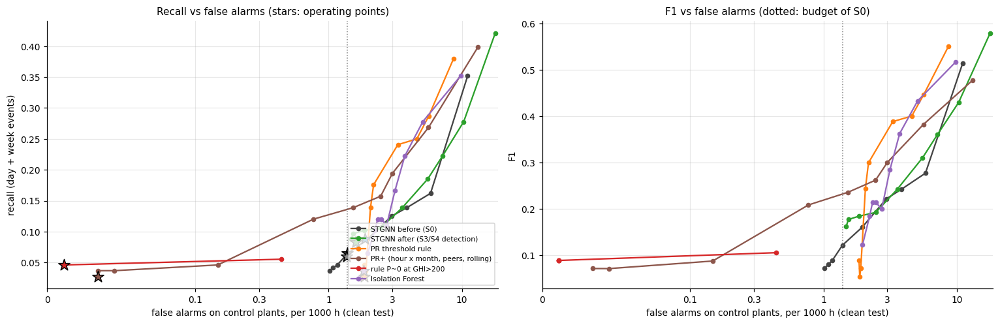

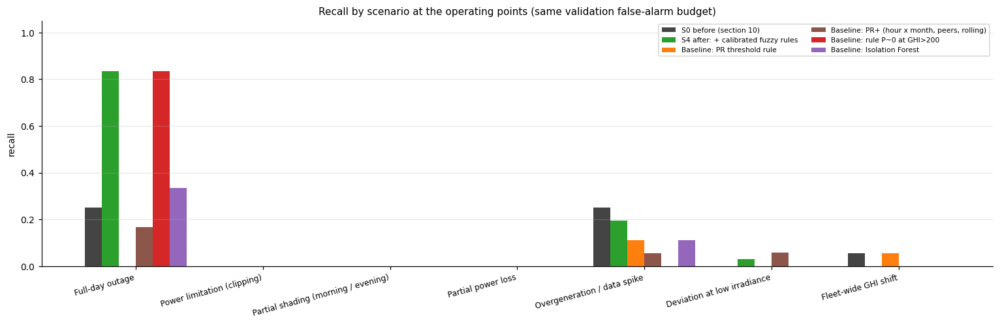

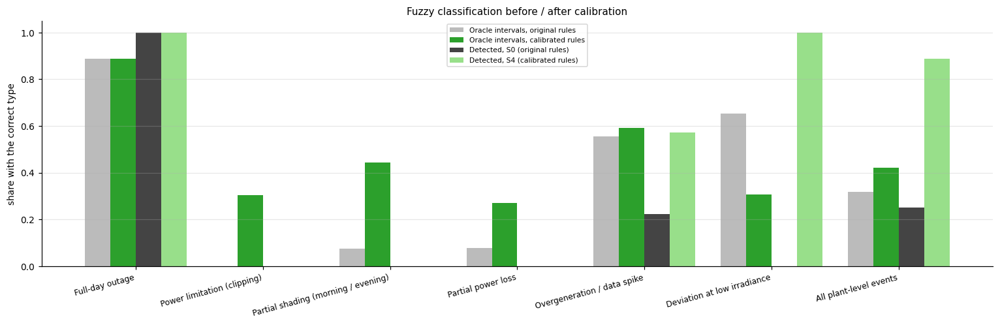

In [65]:
if FIX_OK:
    fx_figs = fx.plot_all(fx_res, FIX_FIG)
    for f in fx_figs.values():
        display(f)
    plt.close("all")

### 12.5. Export to LaTeX


In [66]:
if FIX_OK:
    fx_tex = fx.export_latex(fx_res, FIX_OUT)
    fx_zip = fx.zip_outputs(FIX_OUT, FIX_FIG)
    display(sse.download_link(fx_tex["all"], "Download LaTeX tables (fixes_tables.tex)"))
    display(sse.download_link(fx_zip, "Download archive: .tex, .csv and figures (fixes_results.zip)"))

### 12.6. How to interpret the results

- **operating_points**: S0–S4 and baselines at their operating points; thresholds for S2–S4 and baselines are selected on validation at the S0 budget (minimum: one alarm across all validation hours), so test false alarms may differ.
- **equal_budget**: the main comparison is recall at an equal false-alarm count on the clean test (control plants). The paper's primary comparison is **STGNN (S4) versus PR+**; the PR row shows the gain from PR → PR+ alone. If corrected STGNN does not outperform PR+ at an equal budget, the model's advantage on these scenarios is not established. Paired tests S4 − PR+, S4 − PR, and PR+ − PR at operating points are computed in section 17 (protocol P12).
- **classification**: “Oracle intervals” classifies true intervals (independent of the detector); “Detected” is the fraction of detected events with the correct type.
- **aggregation**: under the old rule, partially covered hours are underestimated and fully missing hours become zeros; with `min_count`, they become NaN and are not counted as “shutdowns.”


## 13. Ablation: k-means versus fuzzy c-means (FCM) for weather regimes and technical clusters

The hypothesis is: “Does soft partitioning improve the final diagnosis?” **Only** the two partitions used by STGNN are replaced: weather regimes (context channels and regime-specific thresholds) and technical clusters (the prior for peer edges and borrowed normalization for new plants). Variants: `kmeans` (frozen models from section 10), `fcm_hard` (FCM with argmax, isolating the algorithm change), and `fcm_soft` (memberships: soft context channels, soft prior $a + (1-a)\cos(u_i,u_j)$, thresholds $\sum_r u_r\,thr_r$). The same $k$, seeds, and hyperparameters are used; each model is trained once and frozen.

Evaluation uses **semi-synthetic data at an equal false-alarm budget** (the S4 detector from section 12, the same placements), not internal indices; the partition coefficient and ARI relative to k-means are provided for reference only. Training the two additional variants on HKUST takes approximately as long as training the models in section 10.


In [67]:
# 13.0 Imports and parameters (optional section: requires pv_fcm_ablation.py and results from sections 10 and 12)
try:
    import pv_fcm_ablation as fca
    FCM_OK = bool(globals().get("FIX_OK")) and "fx_res" in globals()
    if not FCM_OK:
        print("section 13 skipped: run sections 10 and 12 first")
except ImportError as exc:
    FCM_OK = False
    print("section 13 skipped:", exc)

FCM_CFG = fca.AblationConfig(m=2.0, across=0.5, budgets=(0.5, 1.0, 2.0, 5.0)) if FCM_OK else None
FCM_OUT, FCM_FIG = "results/fcm", "results/figures"

In [68]:
if FCM_OK:
    fcm_res = fca.run_ablation(D, C, FIX_MODELS, ss_res=_ss, fixes_res=fx_res, placement_seeds=PLACEMENT_SEEDS,
                               cfg=FCM_CFG, epochs=15, train_stride=1, window=48, hidden=32, device=DEVICE,
                               model_dir="results/cache", raw_cache_dir=FIX_OUT, out_dir=FCM_OUT)

15:44:10 [fcm] weather FCM: k=3 PC=0.402 ARI vs k-means=0.522 ambiguous hours=0.819
15:44:10 [fcm] technical FCM: k=5 PC=0.586 ARI vs k-means=0.471 (technical features of section 4)
15:44:10 [fixes] model 0: raw outputs from cache
15:44:10 [fixes] model 1: raw outputs from cache
15:44:10 [fcm] validation false-alarm budget: 0.011 /1000 h
15:44:15 [fcm] kmeans seed 0: q=0.9999 val FA=1.68 test FA=1.63 recall=0.083 (10s)
15:44:47 [fcm] kmeans seed 1: q=0.9999 val FA=1.68 test FA=1.57 recall=0.083 (42s)
15:45:14 [fcm] fcm_hard seed 0: training (15 epochs), then freezing
train windows: 15725 | val: 1747 | test: 8760
threshold (q=0.995): 13.094 | POT-refined: 17.633
15:48:38 [fcm] fcm_hard seed 0: trained for semi-synthetic test, weights sha256[:16] = 79fb90486d7e8e3d
15:48:38 [fcm] fcm_hard seed 1: training (15 epochs), then freezing
train windows: 15725 | val: 1747 | test: 8760
threshold (q=0.995): 13.279 | POT-refined: 19.768
15:55:03 [fcm] fcm_hard seed 1: trained for semi-synthetic tes

### 13.1. Tables


In [69]:
if FCM_OK:
    fca.show(fcm_res)


=== Partitions (information only; not the evaluation criterion)


,Partition,k,m,Partition coefficient,Mean max membership,Share with max membership < 0.6,ARI (FCM argmax vs k-means)
0,Weather regimes (daylight hours),3,2.0,0.402,0.505,0.819,0.522
1,Technical clusters (plants),5,2.0,0.586,0.689,0.333,0.471



=== Operating points chosen on validation (same budget as section 12)


,Variant,q,Val. FA /1000 h,Test FA (controls) /1000 h,Test FA (all plants) /1000 h,Recall,Recall SD (seeds),Precision,F1,"Delay, h (median)"
0,"k-means (hard, reference)",1.0,1.681,1.602,1.188,0.083,0.000,0.951,0.153,1.5
1,"FCM, hard argmax",1.0,1.681,1.393,1.169,0.074,0.000,0.952,0.137,1.0
2,"FCM, soft memberships",1.0,1.681,1.325,1.183,0.074,0.013,0.970,0.137,1.0



=== Equal false-alarm budget on the clean test (interpolated)


,FA budget (controls) /1000 h,Variant,Recall,Recall SD (seeds),Precision,F1,Test FA (all plants) /1000 h,Interpolated
0,0.500,"k-means (hard, reference)",0.083,0.000,0.993,0.154,1.184,False
1,0.500,"FCM, hard argmax",0.074,0.000,0.952,0.137,1.169,False
2,0.500,"FCM, soft memberships",0.074,0.013,0.970,0.137,1.183,False
3,1.000,"k-means (hard, reference)",0.083,0.000,0.993,0.154,1.184,False
4,1.000,"FCM, hard argmax",0.074,0.000,0.952,0.137,1.169,False
5,1.000,"FCM, soft memberships",0.074,0.013,0.970,0.137,1.183,False
6,1.602,"k-means (hard, reference)",0.084,0.001,0.954,0.154,1.211,False
7,1.602,"FCM, hard argmax",0.079,0.007,0.949,0.146,1.390,True
8,1.602,"FCM, soft memberships",0.085,0.001,0.964,0.156,1.501,True
9,2.000,"k-means (hard, reference)",0.115,0.006,0.953,0.205,1.889,True


... (3 outputs left out)

,Variant,FA budget (controls) /1000 h,Recall (all),Full-day outage,Power limitation (clipping),Partial shading (morning / evening),Partial power loss,Overgeneration / data spike,Deviation at low irradiance,Fleet-wide GHI shift
0,"k-means (hard, reference)",1.602,0.084,0.833,0.0,0.0,0.0,0.194,0.029,0.003
1,"FCM, hard argmax",1.602,0.079,0.833,0.0,0.0,0.0,0.168,0.000,0.028
2,"FCM, soft memberships",1.602,0.085,0.833,0.0,0.0,0.0,0.206,0.011,0.018



=== Share of detected events with the correct fuzzy class


,Scenario,"k-means (hard, reference)","FCM, hard argmax","FCM, soft memberships"
0,Full-day outage,1.000,1.000,1.000
1,Overgeneration / data spike,0.571,0.667,0.667
2,Deviation at low irradiance,1.000,NaN,NaN
3,Fleet-wide GHI shift,0.944,1.000,0.833
4,All plant-level events,0.889,0.935,0.853



Graph rebuilt with FCM prior: {'kmeans': 'reference', 'fcm_hard': True, 'fcm_soft': True}; technical features: technical features of section 4


### 13.2. Figures


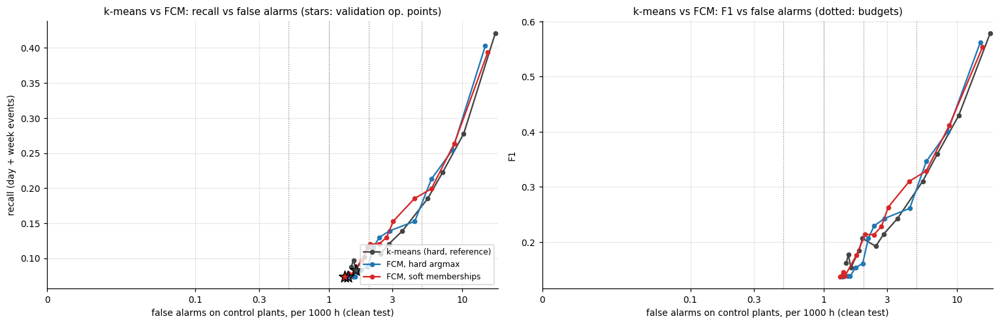

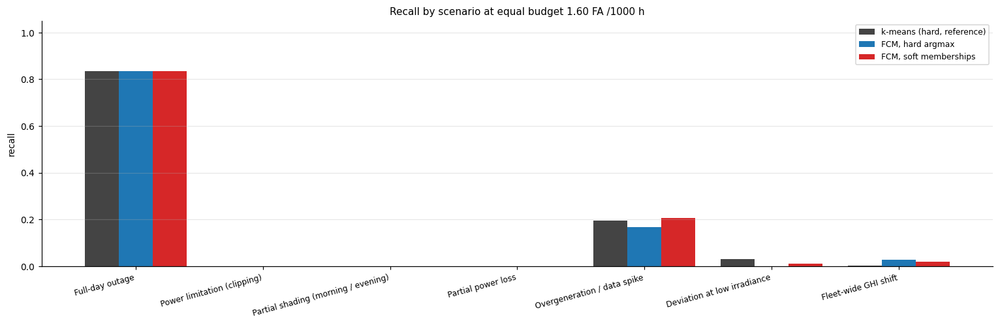

In [70]:
if FCM_OK:
    fcm_figs = fca.plot_all(fcm_res, FCM_FIG)
    for f in fcm_figs.values():
        display(f)
    plt.close("all")

### 13.3. Export to LaTeX


In [71]:
if FCM_OK:
    fcm_tex = fca.export_latex(fcm_res, FCM_OUT)
    fcm_zip = fca.zip_outputs(FCM_OUT, FCM_FIG)
    display(sse.download_link(fcm_tex["all"], "Download LaTeX tables (fcm_tables.tex)"))
    display(sse.download_link(fcm_zip, "Download archive: .tex, .csv and figures (fcm_results.zip)"))

### 13.4. How to interpret the results

- Decisions are based on **delta_recall** and **equal_budget**: the recall difference FCM − k-means at an equal false-alarm count. A difference smaller than the cross-seed variability (`Recall SD (seeds)`) is not considered an improvement.
- `fcm_hard` separates the algorithm's effect from the effect of soft memberships: if `fcm_hard` ≈ `kmeans` but `fcm_soft` is better, soft partitioning itself produces the gain.
- Partition indices (partition coefficient, fraction of hours with max $u$ < 0.6) indicate how “soft” the partition actually is; little difference should be expected when FCM is nearly crisp.


## 14. Does STGNN provide independent value? Testing conditions 2–4

Section 12 showed that a PR threshold rule may perform as well as STGNN on semi-synthetic data. This does not make STGNN useless: it is justified if at least one of the conditions below holds. Condition 1 (STGNN outperforms PR at an equal budget) was already tested in section 12; here, **conditions 2–4** are tested using the same frozen models and event placements.

| Condition | Test | Criterion |
|---|---|---|
| 1+. STGNN versus PR+ | STGNN-day and PR+ at the same total false-alarm budget (primary comparison) | 95% CI for ΔRecall (STGNN-day − PR+) > 0 |
| 2. Fusion | PR OR STGNN at **the same total** false-alarm budget as PR alone | 95% CI for ΔRecall (Fusion − PR) > 0 |
| 3. Difficult conditions | false-alarm rates by stratum: cloud/rain, winter (DJF), plants with high training-period $P/P_{exp}$ variability | pooled rate ratio STGNN-day / PR < 0.8 |
| 4. Cold start and PR weaknesses | cohort 3, first 0–90 days after commissioning; scenarios where $P/P_{exp}$ changes little: 1–2 h profile shift (energy preserved), stuck meter, small loss of 3–8%, multiplicative noise; systemic GHI sensor shift versus plant failure | 95% CI for ΔRecall (STGNN-day − PR) > 0 in at least one stratum or scenario |

Methods:

- **PR** — the threshold rule from section 12; daytime alarms only.
- **PR+** — the baseline from sections 15, 16, and 18 (`pv_prplus`): hour × month, cluster peers, causal rolling median; daytime alarms only. Conditions 2–4 are repeated with PR+ as the reference (rows 2+–4+ of the verdict table); **Fusion+** = PR+ OR STGNN-day with the same 50/50 budget split (75/25 and 25/75 for sensitivity).
- **STGNN** — the unchanged S4 detector from section 12.
- **STGNN-day** — the same S4, but alarms are allowed only during daylight (the same day definition as PR). Otherwise, STGNN spends a substantial share of its budget at night, when PR never alarms, making stratum comparisons inconsistent.
- **Fusion** — PR OR STGNN-day. The total budget is split between components **in advance**: 50/50 (primary variant); 75/25 and 25/75 are sensitivity analyses, not options for selecting the best result.

The budget is the number of alarm events per 1000 evaluated hours on the clean test across all plants; each method's threshold is selected over a quantile grid so its rate does not exceed the budget. The reference budget is the mean S4 background rate from section 12. CIs use paired bootstrap over (model seed, placement, event). Additional scenarios are injected at the same plants and intervals as in section 10 and processed by frozen models using forward passes only (weights checked with SHA-256). All tables and figures are in English.


In [72]:
# 14.0 Imports and parameters (optional section: requires pv_stgnn_value.py and results from sections 10 and 12)
try:
    import pv_stgnn_value as sv
    VAL_OK = bool(globals().get("FIX_OK")) and "fx_res" in globals()
    if not VAL_OK:
        print("section 14 skipped: run sections 10 and 12 first")
except ImportError as exc:
    VAL_OK = False
    print("section 14 skipped:", exc)

VAL_CFG = sv.ValueConfig(budgets=(0.5, 1.0, 2.0, 5.0), n_boot=2000, systemic_share=0.5, hard=True) if VAL_OK else None
VAL_OUT, VAL_FIG = "results/value", "results/figures"


In [73]:
if VAL_OK:
    val_res = sv.run_value_checks(D, C, FIX_MODELS, ss_res=_ss, fixes_res=fx_res, placement_seeds=PLACEMENT_SEEDS,
                                  cfg=VAL_CFG, cfx=FIX_CFG, raw_cache_dir=FIX_OUT, out_dir=VAL_OUT)
    print("reference budget /1000 h:", round(val_res.meta["ref_budget"], 3))

16:10:52 [fixes] model 0: raw outputs from cache
16:10:52 [fixes] model 1: raw outputs from cache
16:10:52 [value] model 0: forward passes on 3 additional realisations
16:11:07 [value] model 1: forward passes on 3 additional realisations
16:11:21 [value] reference alarm budget (clean test, all plants): 1.188 /1000 h; budgets [0.5, 1.0, 1.188, 2.0, 5.0]
16:12:00 [value] seed 0 pr: done (74s)
16:12:13 [value] seed 0 prp: done (86s)
16:12:30 [value] seed 0 stgnn: done (104s)
16:12:42 [value] seed 0 stgnn_day: done (116s)
16:12:57 [value] seed 0 fusion: done (130s)
16:13:11 [value] seed 0 fusion_prp: done (145s)
16:13:23 [value] seed 0 fusion_25: done (156s)
16:13:34 [value] seed 0 fusion_75: done (167s)
16:13:46 [value] seed 0 fusion_prp_25: done (179s)
16:13:57 [value] seed 0 fusion_prp_75: done (190s)
16:14:35 [value] seed 1 pr: done (229s)
16:14:48 [value] seed 1 prp: done (242s)
16:15:05 [value] seed 1 stgnn: done (259s)
16:15:17 [value] seed 1 stgnn_day: done (271s)
16:15:31 [value] 

### 14.1. Tables


In [74]:
if VAL_OK:
    sv.show(val_res)

Reference alarm budget: 1.188 /1000 h (clean test, all plants); weights unchanged: True

=== Conditions 1+ and 2: PR rule, PR+, STGNN and fusions at equal alarm budgets


,"Alarm budget (clean, all plants) /1000 h",Method,q (STGNN / single),q (PR part of fusion),Matched clean rate /1000 h,FA on control plants /1000 h,Recall,Precision,F1,Recall SD (seeds)
0,0.500,PR threshold rule,1.000,NaN,0.497,1.710,0.028,1.000,0.054,0.000
1,0.500,"PR+ (hour x month, peers, rolling)",0.996,NaN,0.463,0.612,0.111,0.803,0.195,0.000
2,0.500,STGNN (S4 detector),1.000,NaN,1.188,1.602,0.083,0.951,0.153,0.000
3,0.500,"STGNN (S4, daylight alarms only)",1.000,NaN,1.114,1.625,0.074,0.962,0.138,0.000
4,0.500,Fusion: PR OR STGNN-daylight (budget 50/50),1.000,1.000,1.186,1.784,0.083,0.987,0.154,0.000
5,0.500,Fusion: PR+ OR STGNN-daylight (budget 50/50),1.000,0.998,1.293,1.818,0.111,0.873,0.197,0.000
6,0.500,Fusion: PR OR STGNN-daylight (budget 75/25),1.000,1.000,1.186,1.784,0.083,0.987,0.154,0.000
7,0.500,Fusion: PR OR STGNN-daylight (budget 25/75),1.000,1.000,1.186,1.784,0.083,0.987,0.154,0.000
8,0.500,Fusion: PR+ OR STGNN-daylight (budget 75/25),1.000,0.997,1.422,1.987,0.139,0.864,0.239,0.000
9,0.500,Fusion: PR+ OR STGNN-daylight (budget 25/75),1.000,1.000,1.214,1.659,0.093,0.966,0.169,0.000



=== Paired bootstrap of the recall difference (vs PR and PR+)


,Alarm budget /1000 h,Comparison,Events,ΔRecall,95% CI low,95% CI high,Only first detects,Only second detects,Result
0,0.5,Fusion − PR,216,0.056,0.023,0.093,14,2,better (CI > 0)
1,0.5,Fusion 75/25 − PR,216,0.056,0.023,0.093,14,2,better (CI > 0)
2,0.5,Fusion 25/75 − PR,216,0.056,0.023,0.093,14,2,better (CI > 0)
3,0.5,STGNN − PR,216,0.056,0.019,0.097,16,4,better (CI > 0)
4,0.5,STGNN-day − PR,216,0.046,0.009,0.083,14,4,better (CI > 0)
...,...,...,...,...,...,...,...,...,...
60,5.0,Fusion+ − PR+,216,-0.019,-0.065,0.028,12,16,no significant difference
61,5.0,Fusion+ 75/25 − PR+,216,0.028,-0.014,0.069,14,8,no significant difference
62,5.0,Fusion+ 25/75 − PR+,216,-0.009,-0.069,0.046,20,22,no significant difference
63,5.0,Fusion+ − STGNN-day,216,0.074,0.014,0.139,31,15,better (CI > 0)



=== Condition 3: where the alarms go (clean test, all plants, reference budget)


,Group,Stratum,Scored plant-hours,Alarms /1000 h: PR,Alarms /1000 h: PR+,Alarms /1000 h: STGNN,Alarms /1000 h: STGNN-day,Alarms /1000 h: Fusion,Alarms /1000 h: Fusion+,Share of alarms: PR,Share of alarms: PR+,Share of alarms: STGNN,Share of alarms: STGNN-day,Share of alarms: Fusion,Share of alarms: Fusion+,Rate ratio STGNN-day / PR,Rate ratio STGNN-day / PR+
0,Weather regime,night,223951,0.000,0.000,0.596,0.000,0.000,0.000,0.000,0.000,0.222,0.000,0.000,0.000,NaN,NaN
1,Weather regime,R2: cloudy,154641,2.852,2.244,1.077,1.927,2.273,2.842,0.759,0.615,0.278,0.502,0.560,0.539,0.676,0.859
2,Weather regime,R1: clear / high irradiance,90425,1.150,1.968,2.875,2.936,2.693,3.677,0.179,0.316,0.433,0.447,0.388,0.407,2.553,1.492
3,Weather regime,R3: rain / low visibility,34267,1.051,1.138,1.167,0.875,0.948,1.284,0.062,0.069,0.067,0.051,0.052,0.054,0.833,0.769
4,Season,DJF (winter),121366,2.085,0.906,1.261,1.141,1.500,1.483,0.435,0.195,0.255,0.233,0.290,0.221,0.547,1.259
5,Season,MAM (spring),127049,0.323,1.039,0.972,0.724,0.716,1.043,0.071,0.234,0.206,0.155,0.145,0.162,2.244,0.697
6,Season,JJA (summer),126926,1.040,1.426,1.442,1.588,1.481,2.174,0.227,0.321,0.305,0.340,0.300,0.338,1.527,1.113
7,Season,SON (autumn),127943,1.211,1.102,1.098,1.262,1.301,1.778,0.267,0.250,0.234,0.272,0.265,0.279,1.042,1.145
8,Physics-model mismatch of the plant,low P/P_exp scatter (train),156075,2.326,1.256,1.291,1.570,1.800,1.983,0.625,0.348,0.336,0.413,0.448,0.379,0.675,1.250
9,Physics-model mismatch of the plant,medium P/P_exp scatter (train),155864,0.610,1.213,0.420,0.330,0.391,0.969,0.164,0.335,0.109,0.087,0.097,0.185,0.542,0.272


... (4 outputs left out)


=== Condition 4c: sensor fault vs plant fault


,Method,Fleet GHI shift: share of plants alarming,Fleet GHI shift: flagged as systemic,Plant events wrongly flagged as systemic
0,PR threshold rule,0.064,0.148,0.111
1,"PR+ (hour x month, peers, rolling)",0.010,0.000,0.000
2,STGNN (S4 detector),0.018,0.000,0.000
3,"STGNN (S4, daylight alarms only)",0.017,0.019,0.000
4,Fusion: PR OR STGNN-daylight (budget 50/50),0.026,0.037,0.000
5,Fusion: PR+ OR STGNN-daylight (budget 50/50),0.018,0.000,0.000



=== Summary of conditions 2-4 (vs PR) and 1+-4+ (vs PR+)


,Condition,Criterion,Evidence,Met
0,2. Fusion PR OR STGNN beats the PR rule at equ...,95% CI of ΔRecall (fusion 50/50 − PR) above 0 ...,"ΔRecall = -0.028 [-0.065, 0.009], n = 216; bud...",False
1,3. Fewer STGNN alarms in difficult conditions ...,alarm-rate ratio STGNN-day / PR < 0.8 pooled o...,pooled ratio = 0.89; R2: cloudy: 0.68; DJF (wi...,False
2,4. STGNN better for new plants or where P/P_ex...,95% CI of ΔRecall (STGNN-day − PR) above 0 for...,Cohort 3 (2023 only): Δ=+0.125; 0–30 d: Δ=+0.0...,False
3,1+. STGNN-daylight beats PR+ at equal budget,95% CI of ΔRecall (STGNN-day − PR+) above 0,"ΔRecall = -0.051 [-0.111, 0.005], n = 216; oth...",False
4,2+. Fusion PR+ OR STGNN beats PR+ at equal budget,95% CI of ΔRecall (Fusion+ − PR+) above 0,"ΔRecall = +0.019 [-0.014, 0.056], n = 216; oth...",False
5,3+. Fewer STGNN alarms than PR+ in difficult c...,alarm-rate ratio STGNN-day / PR+ < 0.8 pooled ...,pooled ratio = 1.34,False
6,4+. STGNN better than PR+ for new plants or wh...,95% CI of ΔRecall (STGNN-day − PR+) above 0 fo...,Cohort 3 (2023 only): Δ=+0.125; 0–30 d: Δ=+0.0...,False


### 14.2. Figures


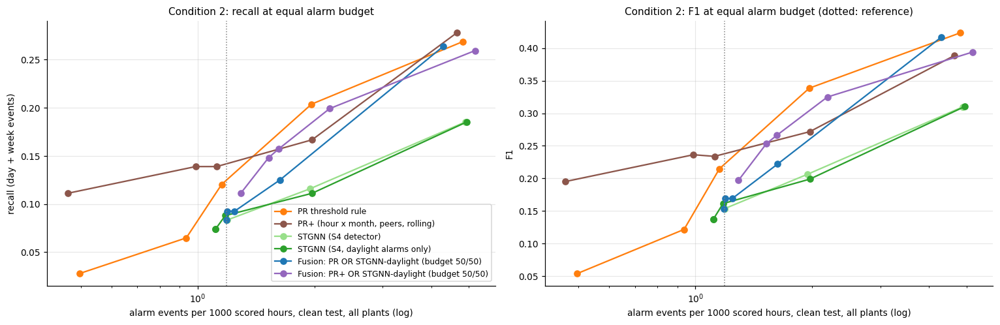

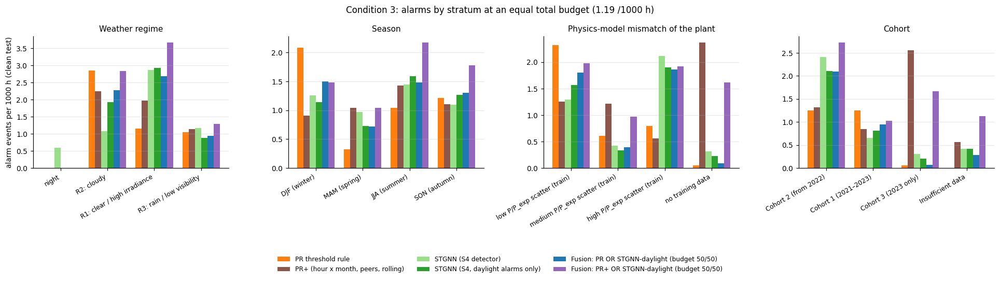

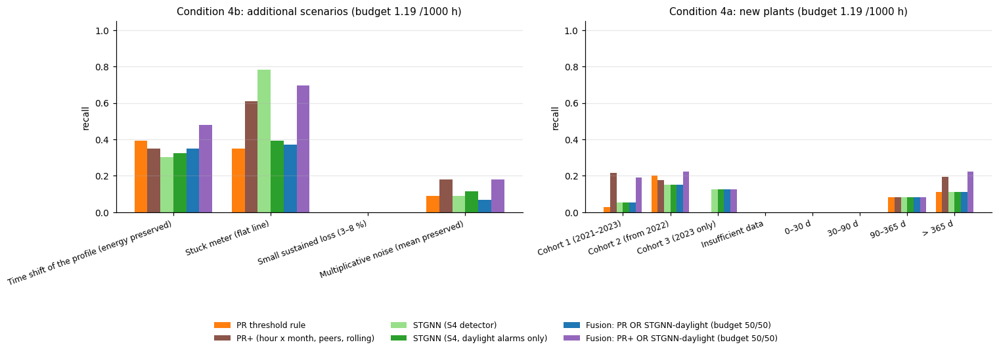

In [75]:
if VAL_OK:
    val_figs = sv.plot_all(val_res, VAL_FIG)
    for f in val_figs.values():
        display(f)
    plt.close("all")

### 14.3. Export to LaTeX


In [76]:
if VAL_OK:
    val_tex = sv.export_latex(val_res, VAL_OUT)
    val_zip = sv.zip_outputs(VAL_OUT, VAL_FIG)
    display(sse.download_link(val_tex["all"], "Download LaTeX tables (value_tables.tex)"))
    display(sse.download_link(val_zip, "Download archive: .tex, .csv and figures (value_results.zip)"))

### 14.4. How to interpret the results

- The final output is the **verdict** table: each condition lists its criterion, numerical evidence, and `Met`. If none of conditions 1–4 holds, STGNN adds no value beyond the PR rule in the current setting; if condition 2 holds, a practical detector is PR OR STGNN. Rows **1+–4+** apply the same criteria against PR+ and address the primary question: “STGNN versus PR+ at an equal budget.”
- **equal_budget** and **fusion_bootstrap** address condition 2. Decisions use the primary 50/50 split; 75/25 and 25/75 show robustness and must not be used to choose the best variant (that would tune on the test set).
- **alarms_by_stratum** addresses condition 3. Clean-test false-alarm rates are compared at the same total budget; the “night” stratum shows how much of the original STGNN budget is spent at night.
- **cold_start**, **hard_scenarios**, and **sensor_vs_plant** address condition 4. In `sensor_vs_plant`, the first column is the fraction of plants alarming under a fleet-wide GHI sensor shift (false alarms at the plant level); `flagged as systemic` is the fraction of cases recognized as fleet-wide; the last column is the fraction of genuine plant failures incorrectly labeled systemic.
- Small strata (fewer than ~10 events) yield wide CIs: “no significant difference” does not imply that the methods are equivalent.


## 15. Multimodal STGNN: HKUST inverter data

Sections 10–14 use only plant power, weather data, and the physical model. The 37 HKUST plants with optimizers also provide **inverter data** (5 min): phase power, grid voltage and frequency, DC voltage, and reactive power. This section tests whether these modalities improve performance and separates their contribution from that of the graph model itself. All SPS–Kalman comparison results (sections 1–14) remain unchanged: this section only reads `D`, `C`, and the frozen models from section 10.

| Stage | Procedure | Data |
|---|---|---|
| 0. Audit | match inverters to plants, coverage, inverter sum vs plant meter, energy vs integrated power, channel ranges | real |
| 1. Sources of variability | variability of $\log(P/P_{exp})$, ratios to cluster peers and to peer inverters at the same plant; 5-min dips; overvoltage fraction among low-PR hours; by season and cloudiness | real |
| 2. Explanation of real alarms | modality-based explanations for PR and PR+ alarms on the 2023 test set | real |
| 3. Consistent semi-synthetic data | inverter failure, short shutdowns, phase loss, grid curtailment (no alarm required, grid class), meter fault (no alarm required, data class), drift + plant failure; changes are injected consistently into plant power and inverter channels | semi-synthetic |
| 4. Equal-budget comparison | PR, PR+, modal rules, PR+ & modal (decision fusion), STGNN, STGNN-mm (early fusion, mask, modality dropout), STGNN-mm + modal edges, leave-one-modality-out, robustness without modalities | semi-synthetic |
| 5. Preregistered criteria | below | — |

**Criteria (fixed before evaluation).** A modality or model is useful if at least one condition holds: (a) the 95% CI for $\Delta$Recall > 0 at the same false-alarm budget; (b) false alarms on “no alarm required” scenarios decrease by at least 20% without reducing recall; (c) macro-F1 across cause classes (plant / inverter / grid / data) increases by at least 0.10. STGNN-mm is considered useful only if it outperforms **PR+ with the same modalities** (otherwise, the gain comes from the modality rather than the neural network).

The budget is the number of alarm events per 1000 clean-test hours; models: 5 seeds (`MODAL_SEEDS = train_seeds`) for STGNN, STGNN-mm, and STGNN-fmm. CIs use paired bootstrap over events (placement, event); rows for the same event across all seeds are sampled together. All STGNN weights are frozen (SHA-256 checked before and after). Multimodal models are trained once and saved to `results/cache/stgnn_mm_<variant>_<seed>.pt`. This section is skipped if the inverter folder is absent. All tables and figures are in English.

**Generator correction.** In `plan_modal`, the `metering` scenario previously did not set its own strength (reusing the last `grid_curtail` coefficient), while `new_obstruction` took its strength from `metering_factor` instead of `obstruction_block`. Each event's strength now comes from its own scenario range, and `check_strengths` stops generation if the labeled strength lies outside that range (test: `tests/modal_gen_strength_test.py`). Results from sections 15–16 obtained before this correction are invalid and must be recomputed.


In [77]:
# 15.0 Imports and parameters (optional section)
import os
try:
    import pv_modal_data as md, pv_semisynth_modal_gen as smg, pv_stgnn_multimodal as smm, pv_modal_eval as me
    import pv_semisynth_eval as sse
    INV_DIR = path + '/Dataset/Time series dataset/PV generation dataset/PV stations with panel level optimizer/Inverter level dataset'
    SITE_DIR = pv_path_1
    MODAL_OK = os.path.isdir(INV_DIR)
    if not MODAL_OK:
        print("section 15 skipped: inverter folder not found:", INV_DIR)
except ImportError as exc:
    MODAL_OK = False
    print("section 15 skipped:", exc)

MODAL_OUT, MODAL_FIG = "results/modal", "results/figures"
MODAL_SEEDS = list(train_seeds[:3])        # >= 3 seeds: STGNN-mm training
MODAL_PLACEMENTS = (0, 1, 2)               # 3 event placements
MODAL_TRAIN_NN = True                      # False: stages 0-3 and rules only (no STGNN)
MODAL_CFG = me.ModalEvalConfig() if MODAL_OK else None

### 15.1. Stage 0: loading and auditing inverter data


In [78]:
if MODAL_OK:
    M_inv = md.load_inverters(INV_DIR, D)
    site_energy = md.load_site_energy(SITE_DIR, D)
    modal_s0 = md.audit(D, M_inv, site_energy)
    for k, v in modal_s0.items():
        print(md.TITLES.get(k, k)); display(v.round(3))

16:17:29 [modal] 44 inverters at 37 sites loaded in 51s
Stage 0: inverter files mapped to sites (Brick consistency, coverage)


,Site,Inverter files,Inverters in Brick,Orientations in Brick,Mixed orientation (Brick),Rated kW,First record,"Missing 5-min samples, %","Valid hours, %"
0,Indoor Sports Centre,1,1,2,False,33.3,2021-11-17 07:00:00,7.64,32.38
1,LSK North,1,1,2,False,55.0,2021-05-04 07:00:00,5.75,41.45
2,LSK South,1,1,1,False,25.0,2021-05-01 06:00:00,11.35,39.09
3,Library,3,3,1,True,170.2,2022-06-01 06:00:00,6.91,24.38
4,S H Ho Sports Hall,2,2,1,False,42.0,2021-11-01 06:00:00,6.94,33.34
5,SQ Apartment1-12,1,1,1,False,17.0,2021-07-08 06:00:00,3.74,39.85
6,SQ Apartment13-24,1,1,1,False,17.0,2021-07-11 07:00:00,3.92,39.59
7,SQ Apartment25-36,1,1,1,False,17.0,2021-07-15 07:00:00,5.18,38.76
8,SQ Apartment37-48,1,1,1,False,16.2,2021-07-11 07:00:00,9.46,36.61
9,SQ Block P,1,1,1,False,33.3,2023-06-22 07:00:00,12.70,7.64


Stage 0: inverter modality — summary


,Item,Value
0,Inverters with data,44.00
1,Sites with inverter data,37.00
2,Sites with >= 2 inverters,5.00
3,Sites without inverter data,23.00
4,Unmatched inverter files,0.00
5,"Mean missing 5-min samples, %",6.69


Stage 0: energy consistency (site meter vs sum of inverters; generation vs integral of power)


,Site,Days compared,"Median |site - sum inv| / site, %","Days with |diff| > 5 %, %","Median |generation - integral of power| / generation, %","Median signed (generation - integral) / generation, %"
0,Indoor Sports Centre,731,0.042,0.00,2.925,2.902
1,LSK North,913,0.037,0.00,2.879,2.878
2,LSK South,855,0.037,0.00,2.866,2.861
3,Library,550,0.000,0.00,2.855,2.847
4,S H Ho Sports Hall,751,0.000,0.00,2.837,2.836
5,SQ Apartment1-12,852,0.017,0.00,2.833,2.829
6,SQ Apartment13-24,852,0.020,0.00,2.830,2.821
7,SQ Apartment25-36,852,0.029,0.00,2.856,2.825
8,SQ Apartment37-48,852,0.063,0.00,2.838,2.827
9,SQ Block P,164,0.032,0.00,2.906,2.906


Stage 0: DC voltage states, AC voltage, frequency, phase imbalance, 5-min zeros


,Inverter,"dcV median producing, V","dcV IQR producing, V","dcV median not producing, V","Producing hours with DC off, %","AC V p50, V","AC V p99, V","Hours with AC V > 233.2 V, %","Over-voltage threshold, V","Max |f - 50| p99, Hz",Phase imbalance p50,Phase imbalance p99,"Producing hours with >= 1 zero 5-min sample, %"
0,Indoor Sports Centre #1,750.1,0.3,273.4,0.00,230.4,260.3,38.10,261.5,0.194,0.010,0.217,15.28
1,LSK North #1,771.8,0.3,114.7,0.00,226.6,231.6,0.00,233.2,0.054,0.013,0.051,1.01
2,LSK South #1,750.1,0.4,529.5,0.00,226.4,231.6,0.19,233.2,0.053,0.010,0.048,1.03
3,Library #1,748.0,0.2,99.6,0.14,225.9,234.5,3.24,233.2,0.053,0.019,0.056,0.62
4,Library #2,748.6,0.2,97.6,0.00,225.7,234.1,3.08,234.1,0.054,0.013,0.040,0.72
5,Library #3,747.9,0.4,343.2,0.00,225.5,233.7,2.50,234.0,0.054,0.020,0.060,0.66
6,S H Ho Sports Hall #1,747.5,0.2,24.9,0.00,227.0,233.8,2.37,234.0,0.056,0.013,0.025,1.25
7,S H Ho Sports Hall #2,750.1,0.3,442.9,0.00,227.7,236.5,10.46,236.6,0.052,0.021,0.074,0.98
8,SQ Apartment1-12 #1,747.7,0.2,24.6,0.00,231.8,241.1,33.02,242.2,0.055,0.008,0.017,1.36
9,SQ Apartment13-24 #1,746.8,0.2,24.9,0.00,233.8,241.9,70.29,242.3,0.055,0.008,0.019,2.35


### 15.2. Frozen models: STGNN (section 10) and STGNN-mm


In [79]:
if MODAL_OK and MODAL_TRAIN_NN:
    base_models = globals().get("ss_models") or sse.frozen_models(D, C, seeds=MODAL_SEEDS, cache_dir="results/cache", device=DEVICE)
    mm_models = {v: smm.frozen_mm_models(D, C, M_inv, seeds=MODAL_SEEDS, mm_variant=v, cache_dir="results/cache",
                                         hidden=64, epochs=15, train_stride=1, device=DEVICE)
                 for v in smm.MM_VARIANTS}
else:
    base_models, mm_models = None, None

16:17:34 [stgnn-mm] training mm_early seed 0 (15 epochs, stride 1), then freezing
train windows: 15725 | val: 1747 | test: 8760
threshold (q=0.995): 13.612 | POT-refined: 19.990
16:28:51 [stgnn-mm] mm_early seed 0: trained multimodal model, weights sha256[:16] = ec56e6b634c8edd6
16:28:51 [stgnn-mm] training mm_early seed 1 (15 epochs, stride 1), then freezing
train windows: 15725 | val: 1747 | test: 8760
threshold (q=0.995): 13.468 | POT-refined: 20.291
16:40:14 [stgnn-mm] mm_early seed 1: trained multimodal model, weights sha256[:16] = fd5673c56cad249d
16:40:14 [stgnn-mm] training mm_early seed 42 (15 epochs, stride 1), then freezing
train windows: 15725 | val: 1747 | test: 8760
threshold (q=0.995): 13.239 | POT-refined: 19.696
16:51:36 [stgnn-mm] mm_early seed 42: trained multimodal model, weights sha256[:16] = f4d39c5f134079b9
16:51:36 [stgnn-mm] training mm_graph seed 0 (15 epochs, stride 1), then freezing
train windows: 15725 | val: 1747 | test: 8760
threshold (q=0.995): 13.182 | 

### 15.3. Stages 1–4: evaluation


In [80]:
if MODAL_OK:
    modal_res = me.run_modal(D, C, M_inv, models=base_models, mm_models=mm_models, placement_seeds=MODAL_PLACEMENTS,
                             cfg=MODAL_CFG, out_dir=MODAL_OUT)
    modal_res.stage0 = modal_s0
    if mm_models:      # weights unchanged
        for v, mods in mm_models.items():
            print(v, {s: m.fingerprint() for s, m in mods.items()})

17:24:43 [modal-eval] 108 modal events in 3 placements
17:24:43 [fixes] model 0: forward passes (calibration, clean test, 3 placements)
17:25:09 [fixes] model 1: forward passes (calibration, clean test, 3 placements)
17:25:35 [modal-eval] mm_early seed 0: forward passes
17:26:29 [modal-eval] mm_early seed 1: forward passes
17:27:23 [modal-eval] mm_early seed 42: forward passes
17:28:17 [modal-eval] mm_graph seed 0: forward passes
17:29:11 [modal-eval] mm_graph seed 0: forward passes, no modal channels
17:30:06 [modal-eval] mm_graph seed 1: forward passes
17:31:00 [modal-eval] mm_graph seed 1: forward passes, no modal channels
17:31:55 [modal-eval] mm_graph seed 42: forward passes
17:32:49 [modal-eval] mm_graph seed 42: forward passes, no modal channels
17:35:01 [modal-eval] seed 0: 15 detectors evaluated (623s)
17:35:38 [modal-eval] seed 1: 15 detectors evaluated (660s)
17:36:19 [modal-eval] done in 701s
mm_early {0: 'ec56e6b634c8edd6', 1: 'fd5673c56cad249d', 42: 'f4d39c5f134079b9'}
mm

### 15.4. Tables


In [81]:
if MODAL_OK:
    me.show(modal_res)

Stage 0: inverter modality — summary


,Item,Value
0,Inverters with data,44.00
1,Sites with inverter data,37.00
2,Sites with >= 2 inverters,5.00
3,Sites without inverter data,23.00
4,Unmatched inverter files,0.00
5,"Mean missing 5-min samples, %",6.69


Stage 0: inverter files mapped to sites (Brick consistency, coverage)


,Site,Inverter files,Inverters in Brick,Orientations in Brick,Mixed orientation (Brick),Rated kW,First record,"Missing 5-min samples, %","Valid hours, %"
0,Indoor Sports Centre,1,1,2,False,33.3,2021-11-17 07:00:00,7.64,32.38
1,LSK North,1,1,2,False,55.0,2021-05-04 07:00:00,5.75,41.45
2,LSK South,1,1,1,False,25.0,2021-05-01 06:00:00,11.35,39.09
3,Library,3,3,1,True,170.2,2022-06-01 06:00:00,6.91,24.38
4,S H Ho Sports Hall,2,2,1,False,42.0,2021-11-01 06:00:00,6.94,33.34
5,SQ Apartment1-12,1,1,1,False,17.0,2021-07-08 06:00:00,3.74,39.85
6,SQ Apartment13-24,1,1,1,False,17.0,2021-07-11 07:00:00,3.92,39.59
7,SQ Apartment25-36,1,1,1,False,17.0,2021-07-15 07:00:00,5.18,38.76
8,SQ Apartment37-48,1,1,1,False,16.2,2021-07-11 07:00:00,9.46,36.61
9,SQ Block P,1,1,1,False,33.3,2023-06-22 07:00:00,12.70,7.64


Stage 0: energy consistency (site meter vs sum of inverters; generation vs integral of power)


,Site,Days compared,"Median |site - sum inv| / site, %","Days with |diff| > 5 %, %","Median |generation - integral of power| / generation, %","Median signed (generation - integral) / generation, %"
0,Indoor Sports Centre,731,0.042,0.00,2.925,2.902
1,LSK North,913,0.037,0.00,2.879,2.878
2,LSK South,855,0.037,0.00,2.866,2.861
3,Library,550,0.000,0.00,2.855,2.847
4,S H Ho Sports Hall,751,0.000,0.00,2.837,2.836
5,SQ Apartment1-12,852,0.017,0.00,2.833,2.829
6,SQ Apartment13-24,852,0.020,0.00,2.830,2.821
7,SQ Apartment25-36,852,0.029,0.00,2.856,2.825
8,SQ Apartment37-48,852,0.063,0.00,2.838,2.827
9,SQ Block P,164,0.032,0.00,2.906,2.906


... (24 outputs left out)

Stage 4: multimodal STGNNs with modalities removed at test time (q of the full model)


,Model,Clean FA /1000 h (q fixed),recall,nuisance,macro_f1,ttd_h,n_fault,n_nonfault
0,STGNN-mm + modal edges (all channels),1.218,0.076,0.028,0.0,2.0,144,72
1,STGNN-mm + modal edges (no modal channels),1.246,0.083,0.028,0.0,3.0,144,72


Stage 5: pre-registered criteria


,Comparison,A,B,Events,Recall A,Recall B,Delta recall,CI low,CI high,Nuisance A,Nuisance B,Macro-F1 A,Macro-F1 B,Verdict,Criteria met
0,All modalities with PR+,PR+ & modal,PR+,216,0.778,0.375,0.403,0.308,0.500,0.111,0.611,0.728,0.060,useful,"(a) recall gain, CI > 0; (b) nuisance alarms -..."
1,Modality: Inverter siblings + DC state,PR+ & modal,prp_m-inverter,216,0.778,0.792,-0.014,-0.048,0.020,0.111,0.167,0.728,0.725,not shown,
2,Modality: Sub-hourly (5-min) power,PR+ & modal,prp_m-subhourly,216,0.778,0.611,0.167,0.095,0.238,0.111,0.167,0.728,0.655,useful,"(a) recall gain, CI > 0; (b) nuisance alarms -..."
3,Modality: Per-phase power,PR+ & modal,prp_m-phase,216,0.778,0.597,0.181,0.119,0.248,0.111,0.111,0.728,0.628,useful,"(a) recall gain, CI > 0"
4,Modality: AC voltage / frequency,PR+ & modal,prp_m-grid,216,0.778,0.778,0.000,0.000,0.000,0.111,0.333,0.728,0.467,useful,(b) nuisance alarms -67 % at no lower recall; ...
5,Modality: Site meter vs inverter sum,PR+ & modal,prp_m-metering,216,0.778,0.778,0.000,0.000,0.000,0.111,0.167,0.728,0.537,useful,(b) nuisance alarms -33 % at no lower recall; ...
6,All modalities with STGNN (decision fusion),STGNN & modal,STGNN,216,0.722,0.076,0.646,0.566,0.720,0.028,0.028,0.663,0.000,useful,"(a) recall gain, CI > 0; (c) macro-F1 +0.66"
7,STGNN-mm (early fusion) vs STGNN,STGNN-mm,STGNN,216,0.069,0.076,-0.007,-0.030,0.014,0.028,0.028,0.000,0.000,not shown,
8,STGNN-mm + modal edges vs STGNN-mm,STGNN-mm+edges,STGNN-mm,216,0.076,0.069,0.007,-0.022,0.036,0.028,0.028,0.000,0.000,not shown,
9,STGNN-mm + modal edges vs STGNN,STGNN-mm+edges,STGNN,216,0.076,0.076,0.000,-0.021,0.021,0.028,0.028,0.000,0.000,not shown,


### 15.5. Figures


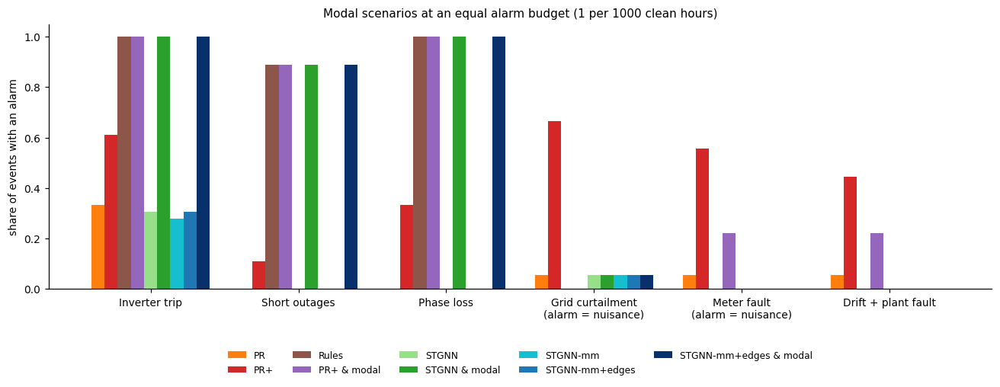

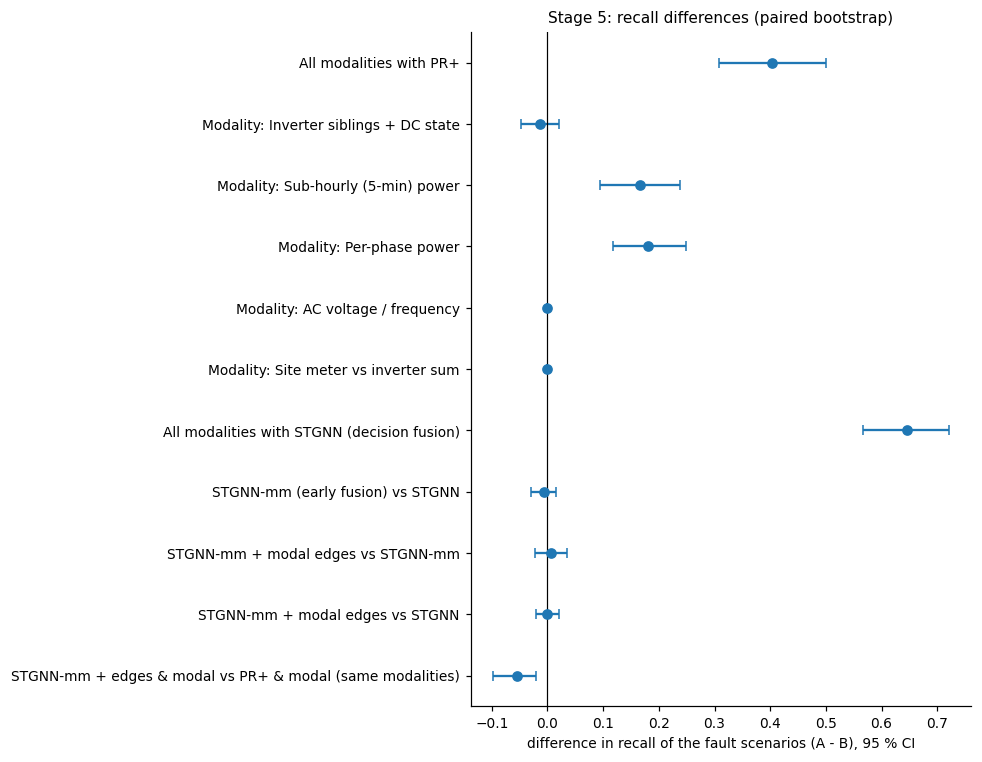

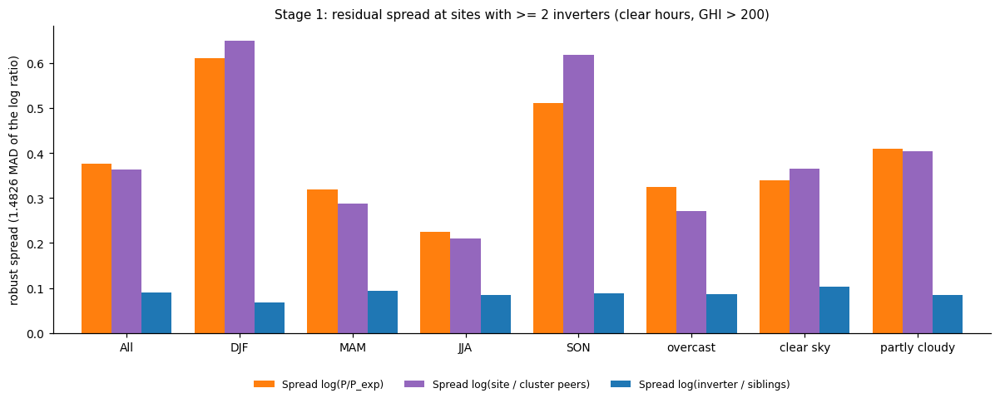

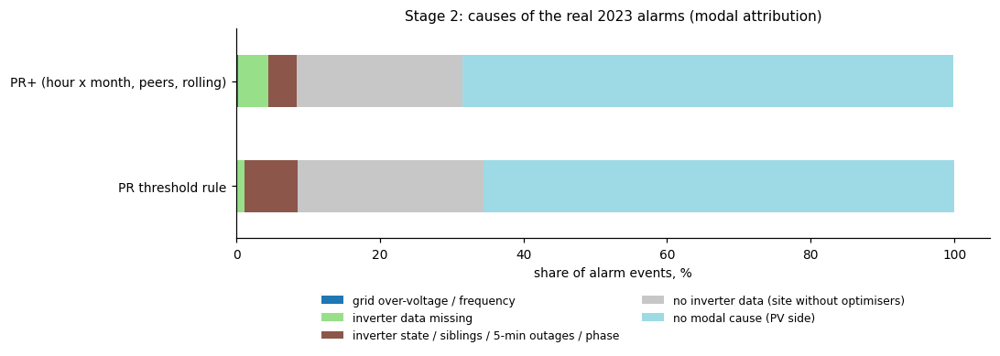

In [82]:
if MODAL_OK:
    modal_figs = me.plot_all(modal_res, MODAL_FIG)
    for f in modal_figs.values():
        display(f)
    plt.close("all")

### 15.6. Export to LaTeX


In [83]:
if MODAL_OK:
    modal_tex = me.export_latex(modal_res, MODAL_OUT)
    modal_zip = me.zip_outputs(MODAL_OUT, MODAL_FIG)
    display(sse.download_link(modal_zip, "Download archive: .tex, .csv and figures (modal_results.zip)"))

### 15.7. How to interpret the results

- **Stage 0.** `energy`: the median |plant meter − Σ inverters| should be < 1%; otherwise, the `meter` channel is unreliable. The generation vs ∫P column shows a systematic energy-meter bias (~+2.9% for HKUST), which is a data property rather than a fault. Inverter files cover only ~06:00–18:00, so nighttime hours have no modal data (mask = 0).
- **Stage 1.** If the ratio to peer inverters is much less variable than $P/P_{exp}$ and the ratio to cluster peers, the main PR uncertainty comes from the $P_{exp}$ model and weather data rather than equipment; the “peer inverters” modality then provides a sensitive detector, but only at plants with ≥ 2 inverters.
- **Stage 2.** Alarms “without a modal explanation” may reflect panel faults/soiling or $P_{exp}$ model errors; their fraction is not an estimate of false alarms.
- **Stages 4–5.** Decisions use the **verdict** table. “PR+ & modal vs PR+” comparisons assess the value of modalities; “STGNN-mm vs PR+ & modal” assesses the neural network's value with the same modalities. Rows `prp_m-<modality>` and the `leave_one_out` table show each modality's contribution; `robustness` shows STGNN-mm behavior when modal channels are absent.
- Plants without inverter data (23 of 60) receive only a zero mask; their results are shown separately in `fa_strata`.


## 16. Factorized multimodal STGNN (STGNN-fmm)

An additional comparison model built on the multimodal STGNN from section 15. Results from sections 1–15 (including the SPS–Kalman comparison) remain unchanged: this section only reads `D`, `C`, `M_inv`, and the frozen models from sections 10 and 15, and performs its own `run_modal` evaluation.

**Principle: factorize multimodal data into descriptive and generative components** (analogous to the Multimodal Factorization Model, Tsai et al., ICLR 2019).

| Component | Function |
|---|---|
| Node modalities (plant, causal 24 h window) | context (P_exp, GHI, solar elevation, direct-radiation fraction, hour, day of year) + 7 groups: inverters, 5-min, phases, grid, meter, **shading mask**, **Kalman estimate variance** |
| Cross-modal graph | nodes represent modalities; domain-prior edges (grid → inverter, inverter → 5-min dips, shading → power, meter ↔ inverters, etc.); weights are learned, and edges outside the prior graph are allowed but penalized by L1 |
| Descriptive factor $z_d$ | attention pooling over available modalities; trained to explain the deviation $\log((P+c)/(P_{exp}+c))$ from modalities without measured power as input; attention weights indicate which modality explains the deviation |
| Generative factors | a generator $G_g(z_d, h_g, h^{spatial}_g, \text{noise})$ for each group reconstructs the missing-modality window; **adversarial** training (LSGAN, conditional discriminator per group) + L1 on artificially hidden real windows |
| Detector | STGNN from section 15 (same losses, calibration, S4 detector), augmented with completed channels, availability masks, $z_d$, and the explained deviation; modality dropout replaces an observed modality with a generated one |

**New modalities.**
- *Shading mask from neighboring buildings and terrain* (`pv_shading`). HKUST Brick specifies a 10° tilt and 180° azimuth for all plants, coordinates are accurate to 0.01°, and no 3D model is available. The default mask is therefore estimated from data: clear training-period hours (kt > 0.55) are grouped by solar azimuth (10°) and elevation (5°); losses relative to high solar elevations are smoothed using a median filter over azimuth and isotonic regression over elevation. If a horizon profile (`HORIZON_CSV`: column/site, azimuth_deg, horizon_deg) or obstacle list (azimuth_deg, width_deg, distance_m, height_m) is available, a geometric mask is used. Channels: $s_{bin}$ (direct-radiation loss at the Sun's position) and $s_{eff} = s_{bin}\cdot$ direct-radiation fraction (Erbs).
- *P_exp uncertainty — Kalman-filter estimate variance* (`pv_kalman_uncertainty`): causal predicted covariance $P_{d|d-1}$ of the section 3 filter parameters and the full prediction sd of normalized power; observation variance and the calibration multiplier are estimated only on the training period.

Training has two stages: (A) the factorized module is trained jointly across all modalities on the training period; (B) it is frozen, and STGNN is trained on its outputs. Checkpoint `results/cache/stgnn_mm_mm_fact_<seed>.pt` contains both networks, shading masks, and Kalman parameters; SHA-256 covers both networks.

**Comparison** (same protocol, equal budget, paired bootstrap): PR+ with shading mask and Kalman sd (`prp_sk`, `prp_skm` — the same new modalities without a neural network), STGNN-fmm, STGNN-fmm & modal; robustness without modal channels, without the mask, and without Kalman sd; false alarms during known-shade hours. The additional **new_obstruction** scenario (a new obstacle — scaffolding or a new building; alarm required) tests whether the fixed mask “hides” new shading. STGNN-fmm is considered useful only if **STGNN-fmm & modal outperforms PR+ (shade, sd) & modal** (CI for $\Delta$Recall > 0). All tables and figures are in English.


In [84]:
# 16.0 Imports and parameters (optional section; requires section 15)
try:
    import pv_shading as psh, pv_kalman_uncertainty as pku, pv_stgnn_factorized as pfm
    FMM_OK = bool(globals().get("MODAL_OK"))
    if not FMM_OK:
        print("section 16 skipped: section 15 (inverter data) is required")
except ImportError as exc:
    FMM_OK = False
    print("section 16 skipped:", exc)

FMM_OUT, FMM_FIG = "results/fmm", "results/figures_fmm"
FMM_SEEDS = list(MODAL_SEEDS) if FMM_OK else []
FMM_PLACEMENTS = MODAL_PLACEMENTS if FMM_OK else ()
HORIZON_CSV = None          # path to the horizon profile (column/site, azimuth_deg, horizon_deg); None = data-derived mask
OBSTACLES_CSV = None        # path to the obstacle list (column/site, azimuth_deg, width_deg, distance_m, height_m)
FMM_CFG = pfm.FMMConfig(epochs=8, stride=3) if FMM_OK else None

### 16.1. New modalities: shading mask and Kalman-filter sd


In [85]:
if FMM_OK:
    hz = pd.read_csv(HORIZON_CSV) if HORIZON_CSV else None
    ob = pd.read_csv(OBSTACLES_CSV) if OBSTACLES_CSV else None
    SH = psh.fit_shading(D, C, horizon=hz, obstacles=ob)
    KU = pku.fit_uncertainty(D, C)
    for k, v in psh.evaluate(D, C, SH).items():
        if k != "per_site":
            print(psh.TITLES[k]); display(v.round(3))
    for k, v in pku.evaluate(D, C, KU).items():
        print(pku.TITLES[k]); display(v.round(3))

17:36:27 [shading] 54 masks (0 geometric); sites with shaded sun positions: 54
17:36:27 [kalman-unc] observation variance fitted on the training period for 54 / 60 plants
Section 16: shading masks (training period)


,Site,Mask,Clear training hours,Sun positions covered,Shaded positions (loss > 0),Mean loss over shaded positions,Max loss
0,Indoor Sports Centre,data-driven,768,50,7,0.203,0.397
1,LSK North,data-driven,1065,59,21,0.107,0.205
2,LSK South,data-driven,1065,59,10,0.093,0.136
3,Library,data-driven,490,37,19,0.179,0.283
4,S H Ho Sports Hall,data-driven,852,53,21,0.495,0.871
5,SQ Apartment1-12,data-driven,1013,59,21,0.125,0.227
6,SQ Apartment13-24,data-driven,1013,59,23,0.133,0.244
7,SQ Apartment25-36,data-driven,1013,59,21,0.120,0.222
8,SQ Apartment37-48,data-driven,1013,59,22,0.194,0.336
9,SQ Block P,none,0,0,0,0.000,NaN


Section 16: shading correction on clear hours (median over sites; test = out of sample)


,Period,Sites,N sites,"Spread log(P/P_exp), raw","Spread log(P/P_exp), shading-corrected","Hour-of-day bias range, raw","Hour-of-day bias range, shading-corrected",Sites with lower test spread
0,test,with shaded sun positions,54,0.201,0.152,0.474,0.288,40
1,training,with shaded sun positions,54,0.249,0.132,0.425,0.160,53


Section 16: causal Kalman predictive interval of the normalised power (daylight, valid hours)


,Period,Plants,Coverage of the 95 % interval (median),"Spearman(sd, |error|) (median)",Relative sd (median)
0,training,54,0.957,0.039,0.245
1,test,54,0.957,0.071,0.266


### 16.2. Frozen STGNN-fmm (train once, then freeze)


In [86]:
if FMM_OK and MODAL_TRAIN_NN:
    fmm_models = pfm.frozen_fmm_models(D, C, M_inv, seeds=FMM_SEEDS, cache_dir="results/cache",
                                       hidden=64, epochs=15, train_stride=1, device=DEVICE, fmm_cfg=FMM_CFG, S=SH, K=KU)
    fmm_all = {"mm_graph": mm_models["mm_graph"], "mm_fact": fmm_models}
    display(pfm.training_history(fmm_models).round(4))
else:
    fmm_models, fmm_all = None, None

17:36:31 [stgnn-fmm] training mm_fact seed 0, then freezing
17:36:35 [stgnn-fmm] seed 0: stage A (factorized module, adversarial generation, 8 epochs)


/kaggle/input/datasets/skaldfire/pv-stgnn-fuzzy-multi-full-lib-v5-05-11-26/pv_stgnn_factorized.py:367: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  stats.append([float(rec), float(adv) / max(ng, 1), float(desc), float(lossD) / max(nD, 1) if nD else np.nan])


17:36:39 [stgnn-fmm] epoch 1/8: L1 rec 1.2752 | adv 0.536 | descriptive 0.1653 | D 0.697
17:36:43 [stgnn-fmm] epoch 2/8: L1 rec 0.7104 | adv 0.298 | descriptive 0.1484 | D 0.472
17:36:46 [stgnn-fmm] epoch 3/8: L1 rec 0.6237 | adv 0.441 | descriptive 0.1239 | D 0.371
17:36:50 [stgnn-fmm] epoch 4/8: L1 rec 0.6026 | adv 0.422 | descriptive 0.1129 | D 0.383
17:36:53 [stgnn-fmm] epoch 5/8: L1 rec 0.6038 | adv 0.460 | descriptive 0.1077 | D 0.379
17:36:56 [stgnn-fmm] epoch 6/8: L1 rec 0.5789 | adv 0.498 | descriptive 0.1047 | D 0.337
17:36:59 [stgnn-fmm] epoch 7/8: L1 rec 0.5643 | adv 0.491 | descriptive 0.1029 | D 0.345
17:37:02 [stgnn-fmm] epoch 8/8: L1 rec 0.5604 | adv 0.504 | descriptive 0.1014 | D 0.332
17:37:15 [stgnn-fmm] seed 0: stage B (STGNN on completed modalities, 15 epochs, stride 1)
train windows: 15725 | val: 1747 | test: 8760
threshold (q=0.995): 13.341 | POT-refined: 20.042
17:48:15 [stgnn-fmm] mm_fact seed 0: trained factorized multimodal model, weights sha256[:16] = 6818f7

,Seed,Epoch,L1 reconstruction (hidden groups),Adversarial (generator),Descriptive (Huber),Discriminator
0,0,1,1.2752,0.5360,0.1653,0.6969
1,0,2,0.7104,0.2976,0.1484,0.4719
2,0,3,0.6237,0.4408,0.1239,0.3706
3,0,4,0.6026,0.4216,0.1129,0.3835
4,0,5,0.6038,0.4598,0.1077,0.3785
5,0,6,0.5789,0.4978,0.1047,0.3373
6,0,7,0.5643,0.4906,0.1029,0.3447
7,0,8,0.5604,0.5041,0.1014,0.3324
8,1,1,1.2948,0.5617,0.1686,0.7215
9,1,2,0.7180,0.2977,0.1567,0.4795


### 16.3. Evaluation (stages 3–5 with new methods and the new_obstruction scenario)


In [87]:
if FMM_OK:
    import pv_semisynth_modal_gen as smg
    FMM_GEN = smg.ModalGenConfig(scenarios=tuple(smg.MODAL_SCENARIOS) + ("new_obstruction",))
    fmm_res = me.run_modal(D, C, M_inv, models=base_models, mm_models=fmm_all, placement_seeds=FMM_PLACEMENTS,
                           cfg=MODAL_CFG, gen_cfg=FMM_GEN, out_dir=FMM_OUT, shading=SH, kunc=KU, stages_012=False)
    if fmm_models:
        for s, m in fmm_models.items():
            assert m.unchanged(), "weights changed"
            print("mm_fact", s, m.fingerprint())

18:11:40 [modal-eval] 126 modal events in 3 placements
18:11:40 [fixes] model 0: forward passes (calibration, clean test, 3 placements)
18:12:05 [fixes] model 1: forward passes (calibration, clean test, 3 placements)
18:12:30 [modal-eval] mm_graph seed 0: forward passes
18:13:24 [modal-eval] mm_graph seed 0: forward passes, no modal channels
18:14:17 [modal-eval] mm_graph seed 1: forward passes
18:15:10 [modal-eval] mm_graph seed 1: forward passes, no modal channels
18:16:05 [modal-eval] mm_graph seed 42: forward passes
18:16:59 [modal-eval] mm_graph seed 42: forward passes, no modal channels
18:17:51 [modal-eval] mm_fact seed 0: forward passes
18:19:53 [modal-eval] mm_fact seed 0: forward passes, no modal channels
18:21:25 [modal-eval] mm_fact seed 0: forward passes, no shading
18:23:20 [modal-eval] mm_fact seed 0: forward passes, no Kalman sd
18:25:15 [modal-eval] mm_fact seed 1: forward passes
18:27:15 [modal-eval] mm_fact seed 1: forward passes, no modal channels
18:28:46 [modal-ev

### 16.4. Tables


In [88]:
if FMM_OK:
    me.show(fmm_res)

Stage 4: methods at equal clean alarm budgets (modal scenarios)


,Method,Budget /1000 h,Clean FA /1000 h,"Clean FA, sites with inverters","Clean FA, sites without inverters",recall,nuisance,macro_f1,ttd_h,n_fault,n_nonfault
0,"STGNN-fmm (factorized, generative imputation, ...",0.5,1.256,0.991,1.677,0.117,0.083,0.040,4.0,180,72
1,STGNN-fmm + modal decision fusion,0.5,1.752,1.800,1.677,0.622,0.028,0.669,1.0,180,72
2,"STGNN-fmm (factorized, generative imputation, ...",0.5,1.252,1.006,1.643,0.117,0.097,0.035,4.0,180,72
3,"STGNN-fmm (factorized, generative imputation, ...",0.5,1.228,0.936,1.692,0.083,0.083,0.027,5.0,180,72
4,"STGNN-fmm (factorized, generative imputation, ...",0.5,1.235,0.970,1.656,0.128,0.083,0.040,4.0,180,72
5,STGNN-mm early fusion + modal edges,0.5,1.218,0.932,1.674,0.089,0.028,0.028,3.0,180,72
6,STGNN-mm + modal edges + decision fusion,0.5,1.707,1.727,1.674,0.606,0.028,0.651,0.0,180,72
7,STGNN-mm early fusion + modal edges (no modal ...,0.5,1.246,0.961,1.700,0.100,0.028,0.033,4.0,180,72
8,PR threshold rule,0.5,0.497,0.783,0.041,0.011,0.000,0.014,31.0,180,72
9,"PR+ (hour x month, peers, rolling)",0.5,0.485,0.689,0.160,0.300,0.361,0.072,3.0,180,72


Stage 4: recall (fault scenarios) and nuisance-alarm share (non-fault scenarios) at the reference budget


scenario,Method,Recall: Drift + plant fault,Recall: Inverter trip,Recall: New obstruction,Recall: Phase loss,Recall: Short outages,Nuisance: Grid curtailment,Nuisance: Meter fault
0,PR,0.056,0.333,0.222,0.000,0.000,0.056,0.056
1,PR+,0.444,0.611,0.444,0.333,0.111,0.667,0.556
2,Rules,0.000,1.000,0.056,1.000,0.889,0.000,0.000
3,PR+ & modal,0.222,1.000,0.389,1.000,0.889,0.000,0.222
4,STGNN,0.000,0.306,0.139,0.000,0.000,0.056,0.000
5,STGNN & modal,0.000,1.000,0.139,1.000,0.889,0.056,0.000
6,STGNN-mm+edges,0.000,0.306,0.139,0.000,0.000,0.056,0.000
7,STGNN-mm+edges & modal,0.000,1.000,0.139,1.000,0.889,0.056,0.000
8,"PR+ (shade, sd)",0.444,0.611,0.444,0.333,0.111,0.611,0.556
9,"PR+ (shade, sd) & modal",0.278,1.000,0.389,1.000,0.889,0.000,0.333


Stage 4: alarms of the other plants during the pyranometer drift


,Method,"Other plants, drift window /1000 h","Same window, clean /1000 h",Excess alarms /1000 h
0,STGNN-fmm,1.424,1.405,0.019
1,STGNN-fmm & modal,1.637,1.505,0.132
2,mm_fact|no Kalman sd,1.392,1.366,0.025
3,mm_fact|no modal channels,1.499,1.531,-0.032
4,mm_fact|no shading,1.366,1.385,-0.019
5,STGNN-mm+edges,1.405,1.354,0.050
6,STGNN-mm+edges & modal,1.599,1.436,0.163
7,mm_graph|no modal channels,1.336,1.298,0.038
8,PR,0.688,0.613,0.075
9,PR+,0.481,0.543,-0.062


... (20 outputs left out)

Section 16: generative factor, modality generated with that modality hidden (test period)


,Modality,Channel,Test hours,MAE generated,MAE training median,MAE neighbour mean,Corr generated,Corr neighbour mean
0,Inverter siblings + DC state,sib,71842,0.020,0.015,0.033,0.010,0.132
1,Inverter siblings + DC state,dc_off,71842,0.001,0.000,0.001,0.005,-0.003
2,Sub-hourly (5-min) power,n_zero,71858,0.005,0.004,0.007,0.180,0.005
3,Per-phase power,imb,71805,0.005,0.004,0.004,0.115,0.340
4,AC voltage / frequency,vac,71858,0.463,0.389,0.336,0.051,0.600
5,AC voltage / frequency,f_dev,71858,0.036,0.072,0.028,-0.085,0.543
6,Site meter vs inverter sum,meter,71650,0.069,0.071,0.038,0.436,0.811
7,Shading mask (generated),s_bin,46761,0.118,0.121,0.076,0.662,0.785
8,Shading mask (generated),s_eff,46761,0.065,0.068,0.036,0.640,0.852
9,Kalman sd of P_exp,k_sd_par,109307,0.042,0.043,0.025,0.374,0.662


Section 16: change of the attention of the descriptive factor at event hours (event - clean, same plant and hours)


,Scenario,Events,"Delta attention: Context (P_exp, weather)",Delta attention: Inverter siblings + DC state,Delta attention: Sub-hourly (5-min) power,Delta attention: Per-phase power,Delta attention: AC voltage / frequency,Delta attention: Site meter vs inverter sum,Delta attention: Shading mask (generated),Delta attention: Kalman sd of P_exp
0,Drift + plant fault,18,0.000,0.000,-0.000,-0.000,0.001,-0.000,0.000,0.0
1,Grid curtailment,18,-0.001,-0.010,-0.019,-0.018,0.070,-0.020,-0.001,-0.0
2,Inverter trip,18,0.003,-0.035,-0.065,0.032,0.027,0.035,0.002,0.0
3,Meter fault,18,0.002,0.025,0.020,0.020,0.009,-0.077,0.001,0.0
4,New obstruction,18,0.000,0.000,-0.000,-0.000,0.001,-0.000,0.000,0.0
5,Phase loss,18,0.001,0.013,0.026,-0.082,0.010,0.030,0.001,0.0
6,Short outages,18,0.000,0.002,-0.009,0.003,0.002,0.003,0.000,0.0


### 16.5. Figures


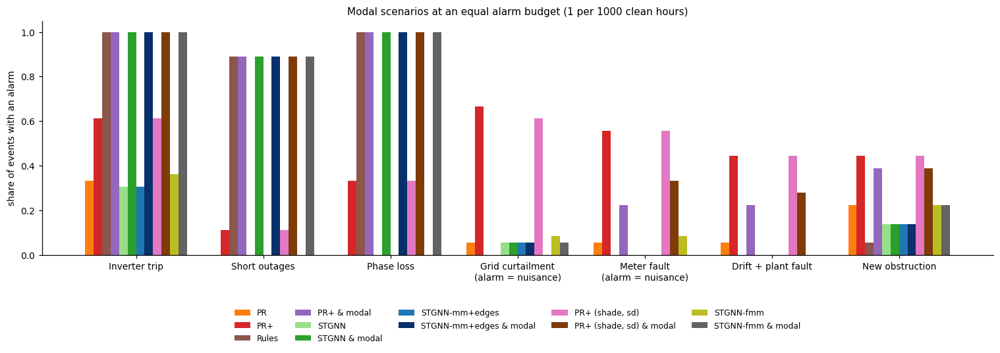

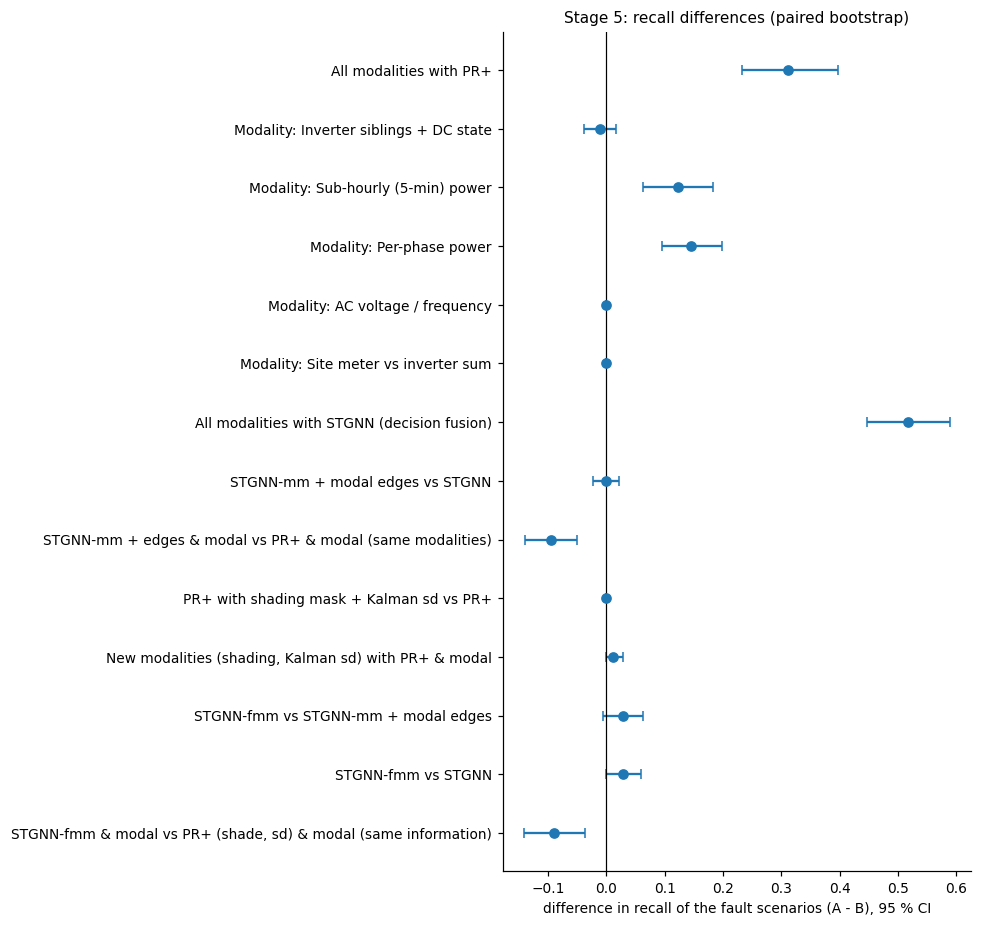

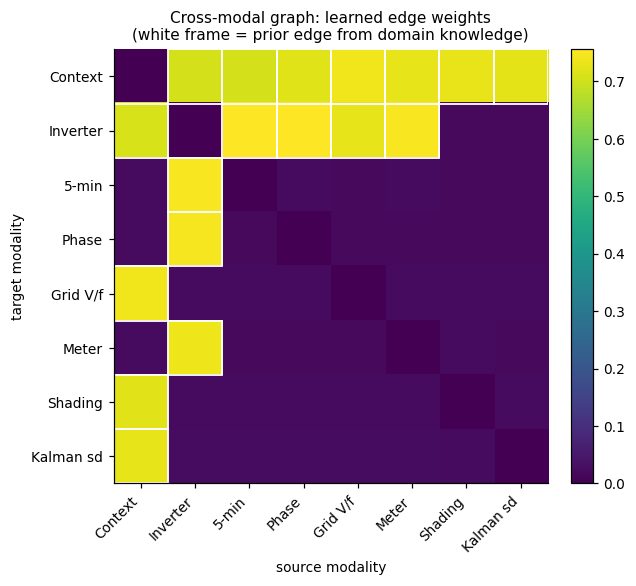

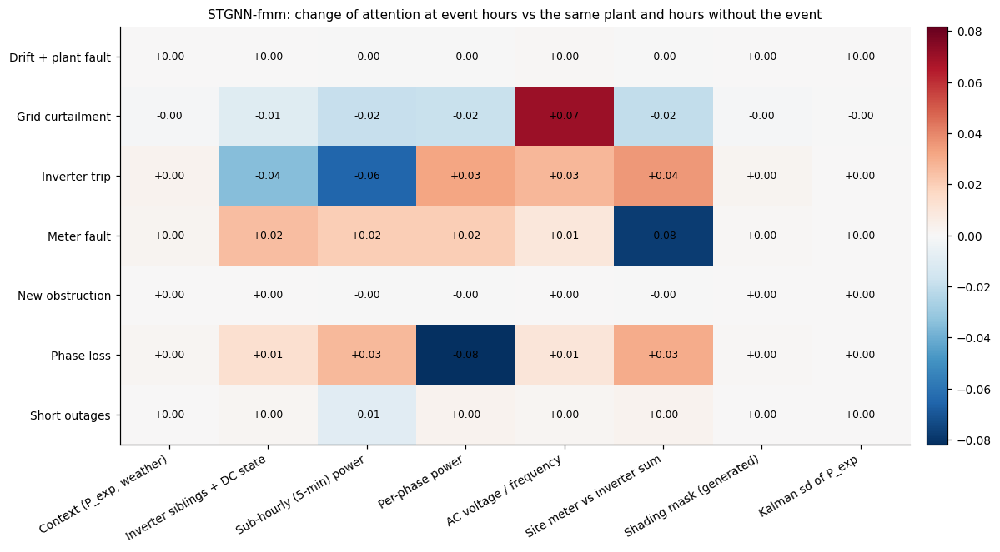

In [89]:
if FMM_OK:
    fmm_figs = me.plot_all(fmm_res, FMM_FIG)
    for f in fmm_figs.values():
        display(f)
    plt.close("all")

### 16.6. Export to LaTeX


In [90]:
if FMM_OK:
    fmm_tex = me.export_latex(fmm_res, FMM_OUT)
    fmm_zip = me.zip_outputs(FMM_OUT, FMM_FIG, name="fmm_results.zip")
    display(sse.download_link(fmm_zip, "Download archive: .tex, .csv and figures (fmm_results.zip)"))

### 16.7. How to interpret the results

- **Shading mask** (`shading_summary`). A reduction in $\log(P/P_{exp})$ variability and the range of hour-specific bias on the test set (outside the mask-training sample) indicates that the mask captures real shading. A data-derived mask also absorbs systematic low-Sun $P_{exp}$ errors (albedo, incidence angle), so it represents “shading + low-Sun model error” rather than pure geometry. A geometric mask (`HORIZON_CSV`) does not have this limitation.
- **Kalman sd** (`kalman_calibration`). Coverage of the 95% interval near 0.95 indicates correct calibration; rank correlation between sd and |error| indicates how informative sd is across hours. With constant observation variance, it is low: sd mainly reflects missing data and season rather than cloudiness.
- **Cross-modal graph** (`fmm_crossmodal`, figure). Learned weights of prior edges versus edges outside the prior graph: a large out-of-prior edge weight suggests a potential new domain relationship (or leakage), while a small prior-edge weight indicates a relationship unsupported by the data.
- **Generative factor** (`fmm_generation`). A modality generated while hidden is compared with the plant median and neighbor mean. Generation is useful only if its MAE is lower than both baselines; otherwise, the generated modality merely avoids harming performance (the availability mask remains an input).
- **Attention** (`fmm_attention`). Change in the descriptive factor's attention weight during event hours relative to the same plant at the same hours without the event. Matching the plant is essential; otherwise, differences merely reflect which plants have which modalities. Increased weight on the “correct” modality (e.g., phases during phase loss, mask for a new obstruction) is an interpretable model output; changes near zero mean attention does not respond to the event.
- **Decision**: use `verdict`. “New modalities ... with PR+ & modal” measures the value of the mask and sd without a neural network; “STGNN-fmm & modal vs PR+ (shade, sd) & modal” measures the factorized neural network's value with the same information. `fa_shaded` measures false-alarm reduction during known-shade hours; recall for `New obstruction` should not decrease relative to PR+.
- A generated modality adds no information beyond the original data (data processing inequality): any STGNN-fmm gain comes from information transfer across neighbors and other modalities and robustness to missing data, not from “new data.”


## 17. Summary of classification metrics across all models (synthetic data)

This section only collects previously computed results from sections 10, 12, 13, 14, 15, and 16: it performs no training or recomputation. Skipped sections are simply omitted from the table.

Each row specifies a protocol, task, model, operating point (alarm budget), event count, and metrics defined by that protocol. Metrics not defined by the protocol remain blank and are not imputed.

| Protocol | Section | Operating point | Metrics |
|---|---|---|---|
| P10 | 10 | frozen STGNN's own calibration (q = 0.995) | event Recall, Precision, F1; fraction of correctly classified causes (fuzzy classifier, crisp rules, k-means); degradation detection (SPS, Kalman), and FPR without injection |
| P12 | 12 | equal false-alarm budget on control plants (S0) | Recall, Precision, F1; cause accuracy |
| P13 | 13 | equal budget = k-means operating point | Recall, Precision, F1; cause accuracy |
| P14 | 14 | equal clean-data alarm budget | Recall, Precision, F1 |
| P15 | 15 | equal clean-data alarm budget (all plants) | Recall, false-positive rate on no-alarm scenarios, cause macro-F1, time to detection |
| P16 | 16 | as P15 + “new obstruction” scenario | as P15 |

**Metrics are comparable only within a protocol**: scenarios, event definitions, and operating points differ. P15/P16 do not compute Precision (using an equal budget and false-positive rate instead). Event counts in P15/P16 include repetitions across random model initializations. All tables are in English.

Export: `results/summary/summary_metrics_all.tex` (summary table, protocols, best detector per protocol with 95% CIs, metric table with 95% CIs, paired comparisons — see 17.2) and CSV. The LaTeX preamble requires `booktabs`, `longtable`, `array`, `graphicx`, and `pdflscape` (the summary table uses a landscape page).


In [91]:
# 17.1 Summary table (from previously computed results)
import pv_metrics_summary as pms
SUMMARY = pms.summary_table(ss_res=globals().get("ss_res"), fx_res=globals().get("fx_res"),
                            fcm_res=globals().get("fcm_res"), val_res=globals().get("val_res"),
                            modal_res=globals().get("modal_res"), fmm_res=globals().get("fmm_res"),
                            ablations=False)          # True: include modality-removal variants
print("protocols in the table:", ", ".join(SUMMARY["Protocol"].unique()) if len(SUMMARY) else "none")
pms.show(SUMMARY)

protocols in the table: P10, P12, P13, P14, P15, P16
Classification metrics of all models on (semi-)synthetic data; metrics are comparable within a protocol only


,Protocol,Section,Task,Model,Operating point,Alarm budget /1000 h,Events,Recall,Precision,F1,Macro-F1 (cause),Nuisance share,Cause accuracy,FPR (no injection),Clean FA /1000 h,"Delay, h"
0,P10,10,"Fault event detection (plant + fleet, day / week)","Frozen STGNN (multi-view, S0 detection)",own calibration (q = 0.995),,216,0.065,0.984,0.122,,,,,1.387,4.000
1,P10,10,Cause classification of detected events,Fuzzy classifier (Mamdani rules) on frozen STGNN detections,own calibration (q = 0.995),,28,,,,,,0.250,,,
2,P10,10,Cause classification of detected events,Crisp rules on frozen STGNN detections,own calibration (q = 0.995),,28,,,,,,0.929,,,
3,P10,10,Cause classification of detected events,K-means anomaly clusters on frozen STGNN detections,own calibration (q = 0.995),,28,,,,,,0.500,,,
4,P10,10,Cause classification (true event interval),"Fuzzy classifier (Mamdani rules), oracle interval",true event interval,,276,,,,,,0.319,,,
5,P10,10,Degradation detection (evidence of a beta1 decrease),Frozen STGNN + Kalman estimator,statistical evidence rule of the estimator,,18,0.444,,,,,,0.111,,
6,P10,10,Degradation detection (evidence of a beta1 decrease),Frozen STGNN + SPS estimator,statistical evidence rule of the estimator,,18,0.444,,,,,,0.333,,
7,P12,12,Fault event detection,STGNN before (S0 detection),equal FA budget on control plants,1.387,108,0.066,0.981,0.123,,,,,1.387,
8,P12,12,Fault event detection,STGNN after (S3/S4 detection),equal FA budget on control plants,1.387,108,0.097,0.976,0.176,,,,,1.387,
9,P12,12,Fault event detection,Baseline: PR threshold rule,equal FA budget on control plants,1.387,108,0.046,1.000,0.088,,,,,1.387,


Evaluation protocols of the summary table


,Protocol,Section,Data,Scenarios,Operating point,Metrics
0,P10,10,"Semi-synthetic: HKUST (or fixture) + injected plant / fleet events, 3 cohorts","Full-day outage; Power limitation (clipping); Partial shading (morning / evening); Partial power loss; Overgeneration / data spike; Deviation at low irradiance; Fleet-wide GHI shift; Gradual degradation (durations: short 1-2 steps, day, week+)","Threshold of the frozen STGNN from its own calibration (q = 0.995, POT)",Event recall; precision = detections overlapping an event / all detections near events; F1; share of detected events with the correct fuzzy / crisp / k-means type; degradation: share with evidence of a beta1 decrease (recall) and the same without injection (FPR)
1,P12,12,"As P10, same placements",As P10,Equal false-alarm budget on control plants = rate of S0 at its operating point,"Recall, precision, F1 at the budget (interpolated threshold curve); cause accuracy of detected events"
2,P13,13,As P10,As P10,Equal false-alarm budget on control plants = k-means operating point,"Recall, precision, F1 at the budget; cause accuracy of detected events (validation operating point)"
3,P14,14,As P10 + hard scenarios,As P10 + Time shift of the profile (energy preserved); Stuck meter (flat line); Small sustained loss (3–8 %); Multiplicative noise (mean preserved),"Equal alarm budget on clean data (all plants), reference budget of the section","Recall, precision, F1; FA on control plants"
4,P15,15,Semi-synthetic modal events on the inverter data (sites with inverter files),"Single inverter trip (multi-inverter site); Short inverter outages, 10-30 min; Loss of one AC phase; Grid over-voltage curtailment (no fault) (no alarm expected); Site meter fault (inverters unchanged) (no alarm expected); Pyranometer drift + plant fault","Equal clean alarm budget (events per 1000 scored hours, all plants), reference budget",Recall over fault events; nuisance share = alarms on no-alarm scenarios; macro-F1 over cause classes (plant / sensor / grid / data); time to detection. Events include model seeds
5,P16,16,As P15,"Single inverter trip (multi-inverter site); Short inverter outages, 10-30 min; Loss of one AC phase; Grid over-voltage curtailment (no fault) (no alarm expected); Site meter fault (inverters unchanged) (no alarm expected); Pyranometer drift + plant fault; New obstruction (scaffold / new building): beam blocked at new sun positions",As P15,As P15


Best detector per protocol


,Protocol,Task,Best model,Criterion,Value,Recall
0,P10,"Fault event detection (plant + fleet, day / week)","Frozen STGNN (multi-view, S0 detection)",F1,0.122,0.065
1,P12,Fault event detection,"Baseline: PR+ (hour x month, peers, rolling)",F1,0.231,0.135
2,P13,Fault event detection,"STGNN + FCM, soft memberships regimes / clusters",F1,0.156,0.085
3,P14,Fault event detection,Fusion: PR+ OR STGNN-daylight (budget 75/25),F1,0.306,0.185
4,P15,Modal fault detection + cause class,PR+ with modal decision fusion,Macro-F1 (cause),0.728,0.778
5,P16,Modal fault detection + cause class,PR+ with modal decision fusion,Macro-F1 (cause),0.727,0.700


### 17.2. Confidence intervals and paired comparisons

No retraining is performed: statistics use previously saved event-level results (`*.events`) from sections 10–16 (module `pv_metrics_stats.py`).

- **The resampling unit is an injected event** (cluster `placement, event_id`). All rows for an event (different `model_seed` values and methods) are sampled together, so repetitions of the same event across seeds are not treated as independent observations.
- **95% CIs** use percentile cluster bootstrap (`n_boot = 2000`). Ratios (recall, precision, F1, macro-F1, false-positive rate, MAE Δβ1) are recomputed from resampled counts.
- **P12 / P13**: “equal-budget” rows are interpolated along threshold curves, with no event-level outcomes at that point, so recall uses a Wilson interval with $n$ = number of unique events (approximate, marked `W`). Classification accuracy on detected events in P12 / P13 uses event-level bootstrap.
- **Paired comparisons A − B** are specified in advance (`pst.P10_COMPS … pst.MODAL_COMPS`), not selected from the results. Both methods are evaluated on the same events; difference CIs use paired cluster bootstrap, $p$ uses a paired permutation test (swapping A and B outcomes within each event), and Holm correction is applied within each protocol. “A better / B better” is reported only if the CI excludes 0 and $p_{Holm} < 0.05$.
- “Only A / B hit” denotes discordant events (detected / correctly classified by only one method).
- In P12 and P13, detectors are compared at their validation-selected operating points (`Clean FA A / B` column); P12 includes S4 − PR+, S4 − PR, and PR+ − PR (baseline rules do not depend on the seed and are matched to each STGNN seed). The primary equal-budget comparison is in P14: STGNN − PR+, STGNN-day − PR+, Fusion PR+ OR STGNN − PR+, PR+ − PR, followed by the previous comparisons with PR. For final paper tables, `N_PERM = 10000` is recommended (minimum attainable $p = 1/(N_{perm}+1)$).


In [92]:
# 17.2 Confidence intervals and paired comparisons (from saved results only)
import pv_metrics_stats as pst
N_BOOT, N_PERM = 2000, 10000          # for the paper: N_PERM = 10000
SUMMARY_STATS = pst.compute(SUMMARY, ss_res=globals().get("ss_res"), fx_res=globals().get("fx_res"),
                            fcm_res=globals().get("fcm_res"), val_res=globals().get("val_res"),
                            modal_res=globals().get("modal_res"), fmm_res=globals().get("fmm_res"),
                            n_boot=N_BOOT, n_perm=N_PERM, seed=0) if len(SUMMARY) else {}
if SUMMARY_STATS:
    print(pms.TITLES["summary_ci"].replace("\\%", "%")); display(SUMMARY_STATS["summary_ci"])
    print(pms.TITLES["best"]); display(pms.tables(SUMMARY, SUMMARY_STATS)["best"])
    print(pms.TITLES["paired"].replace("\\%", "%"))
    P = SUMMARY_STATS["paired"]
    display(P.style.format({c: "{:.3f}" for c in ("A", "B", "Delta (A - B)", "CI low", "CI high",
                                                   "p (permutation)", "p (Holm)")}, na_rep=""))


Summary metrics with 95% confidence intervals (cluster bootstrap over injected events; Wilson intervals for interpolated equal-budget points)


,Protocol,Task,Model,Events,Recall (95% CI),Precision (95% CI),F1 (95% CI),Nuisance share (95% CI),Macro-F1 (cause) (95% CI),Cause accuracy (95% CI),FPR (no injection) (95% CI),"MAE Δβ1, p.p. (95% CI)","MAE Δβ1 (degradation), p.p. (95% CI)",CI method
0,P10,"Fault event detection (plant + fleet, day / week)","Frozen STGNN (multi-view, S0 detection)",108,"0.065 [0.028, 0.111]","0.984 [0.946, 1.000]","0.122 [0.054, 0.200]",,,,,,,cluster bootstrap over events
1,P10,Cause classification of detected events,Fuzzy classifier (Mamdani rules) on frozen STG...,18,,,,,,"0.250 [0.074, 0.444]",,,,cluster bootstrap over events
2,P10,Cause classification of detected events,Crisp rules on frozen STGNN detections,18,,,,,,"0.929 [0.778, 1.000]",,,,cluster bootstrap over events
3,P10,Cause classification of detected events,K-means anomaly clusters on frozen STGNN detec...,18,,,,,,"0.500 [0.267, 0.750]",,,,cluster bootstrap over events
4,P10,Cause classification (true event interval),"Fuzzy classifier (Mamdani rules), oracle interval",138,,,,,,"0.319 [0.239, 0.399]",,,,cluster bootstrap over events
5,P10,Degradation detection (evidence of a beta1 dec...,Frozen STGNN + Kalman estimator,9,"0.444 [0.111, 0.778]",,,,,,"0.111 [0.000, 0.333]","0.754 [0.528, 1.045]","3.359 [1.500, 5.707]",cluster bootstrap over events
6,P10,Degradation detection (evidence of a beta1 dec...,Frozen STGNN + SPS estimator,9,"0.444 [0.111, 0.778]",,,,,,"0.333 [0.000, 0.667]","0.990 [0.694, 1.340]","8.360 [4.172, 12.765]",cluster bootstrap over events
7,P12,Fault event detection,STGNN before (S0 detection),108,"0.066 [0.032, 0.129]",,,,,,,,,"Wilson, n = events (interpolated equal-budget ..."
8,P12,Fault event detection,STGNN after (S3/S4 detection),108,"0.097 [0.054, 0.167]",,,,,,,,,"Wilson, n = events (interpolated equal-budget ..."
9,P12,Fault event detection,Baseline: PR threshold rule,108,"0.046 [0.020, 0.104]",,,,,,,,,"Wilson, n = events (interpolated equal-budget ..."


Best detector per protocol


,Protocol,Task,Best model,Criterion,Value,Value 95% CI,Recall,Recall 95% CI
0,P10,"Fault event detection (plant + fleet, day / week)","Frozen STGNN (multi-view, S0 detection)",F1,0.121621,"[0.054, 0.200]",0.064815,"[0.028, 0.111]"
1,P12,Fault event detection,"Baseline: PR+ (hour x month, peers, rolling)",F1,0.230564,,0.135434,"[0.083, 0.213]"
2,P13,Fault event detection,"STGNN + FCM, soft memberships regimes / clusters",F1,0.156478,,0.085283,"[0.046, 0.153]"
3,P14,Fault event detection,Fusion: PR+ OR STGNN-daylight (budget 75/25),F1,0.306011,"[0.198, 0.405]",0.185185,"[0.111, 0.259]"
4,P15,Modal fault detection + cause class,PR+ with modal decision fusion,Macro-F1 (cause),0.727975,"[0.639, 0.810]",0.777778,"[0.676, 0.871]"
5,P16,Modal fault detection + cause class,PR+ with modal decision fusion,Macro-F1 (cause),0.727082,"[0.647, 0.796]",0.700000,"[0.608, 0.789]"


Pre-specified paired comparisons on the same events: difference A - B, 95% paired bootstrap CI, paired permutation p-value and Holm correction within each protocol


,Protocol,Comparison (A vs B),Operating point,Metric,Events,A,B,Delta (A - B),CI low,CI high,p (permutation),p (Holm),Only A hit,Only B hit,Clean FA A / B,Result
0,P10,Kalman vs SPS: beta1 change error (all quarters),all evaluated quarters,"MAE Δβ1, p.p.",135,0.754,0.990,-0.236,-0.604,0.150,0.242,0.725,,,,no difference shown
1,P10,Kalman vs SPS: beta1 error under injected degradation,estimator evidence rule,"MAE Δβ1 (degradation), p.p.",9,3.359,8.360,-5.002,-8.621,-2.138,0.004,0.018,,,,A better
2,P10,Kalman vs SPS: evidence of a beta1 decrease (degradation),estimator evidence rule,Recall,9,0.444,0.444,0.000,-0.333,0.333,1.000,1.000,2,2,,no difference shown
3,P10,Fuzzy vs crisp rules: cause of detected events,frozen STGNN detections,Cause accuracy,18,0.250,0.929,-0.679,-0.875,-0.467,0.000,0.001,0,19,,B better
4,P10,Fuzzy vs k-means clusters: cause of detected events,frozen STGNN detections,Cause accuracy,18,0.250,0.500,-0.250,-0.593,0.074,0.248,0.725,5,12,,no difference shown
5,P12,STGNN S4 vs S0 (validation operating points),validation operating point,Recall,108,0.083,0.065,0.019,-0.019,0.060,0.486,1.000,8,4,1.60 / 1.39,no difference shown
6,P12,STGNN S4 vs S0 (validation operating points),validation operating point,F1,108,0.153,0.122,0.032,-0.032,0.099,0.462,1.000,,,1.60 / 1.39,no difference shown
7,P12,STGNN S2 vs S0 (validation operating points),validation operating point,Recall,108,0.088,0.065,0.023,0.000,0.046,0.129,0.650,6,1,1.88 / 1.39,no difference shown
8,P12,STGNN S2 vs S0 (validation operating points),validation operating point,F1,108,0.161,0.122,0.040,0.000,0.079,0.099,0.650,,,1.88 / 1.39,no difference shown
9,P12,STGNN S4 vs PR+ (validation operating points),validation operating point,Recall,108,0.083,0.028,0.056,0.005,0.111,0.072,0.650,16,4,1.60 / 0.03,no difference shown


In [93]:
# 17.3 Export to LaTeX and CSV (summary table, CIs, paired comparisons)
if len(SUMMARY):
    SUMMARY_TEX = pms.export_latex(SUMMARY, "results/summary", globals().get("SUMMARY_STATS"))
    for k, p in SUMMARY_TEX.items():
        print(k, "->", p)
    display(sse.download_link(SUMMARY_TEX["all"], "Download LaTeX: summary_metrics_all.tex"))

summary -> results/summary/summary_summary.tex
protocols -> results/summary/summary_protocols.tex
best -> results/summary/summary_best.tex
summary_ci -> results/summary/summary_summary_ci.tex
paired -> results/summary/summary_paired.tex
all -> results/summary/summary_metrics_all.tex


## 18. Semi-synthetic data: configuration changes (module removal and addition)

Independent section (module `pv_semisynth_config.py`): sections 1–17 and their results remain unchanged, and the notebook works without it. This section only reads `D`, `C`, inverter data `M_inv` (section 15, optional), and frozen models `ss_models` (section 10, optional); weights are not trained.

**Scenarios** (a copy of real HKUST data, test period only, from time $t_0$ to the end of the data; rated power and $P_{exp}$ are **not updated**, as in real monitoring before the asset registry is corrected):

| Scenario | Class | Change |
|---|---|---|
| `module_loss` | plant | a fraction $f$ of DC capacity (strings / modules) is disconnected: $P_k \times (1-g)$ for affected inverters, with plant power reduced by the same amount |
| `module_add` | config | new strings with capacity $f$ are connected: $P_k \times (1+g)$, capped at the inverter AC limit $L_k = 1.1 \cdot q_{99.9}(P_k)$ from training → more midday clipping |

$f \in \{5, 15, 40\%\}$ of plant DC capacity. At multi-inverter plants, the change is assigned to the minimum number of inverters such that each changes by no more than 50% of its strings. For `module_add`, an alarm means “configuration-change notification required,” not a fault.

**Evaluation.**
- Detection is counted only within the change-onset window $[t_0, t_0 + 7\,\text{days}]$ at the same clean-data false-alarm budget (PR, PR+, PR+ with modal rules, STGNN S4).
- After the window: fraction of alarm hours during days 7–30 and 30–90 after the change minus the corresponding clean-data fraction. A fixed-reference detector (PR) keeps alarming, whereas a rolling-reference detector (PR+) adapts.
- $\beta_1$: quarterly SPS and Kalman-filter estimates versus the exact expected change; for Kalman, adaptation delay of the filtered daily estimate (days to 90% of the step).
- In each realization, no more than $\max(1, \lfloor 0.2 \cdot n_{cluster}\rfloor)$ plants per cluster are modified, keeping PR+ peers mostly unchanged.
- CIs use event-level bootstrap; paired comparisons use within-event permutation tests with Holm correction.


In [94]:
# 18.0 Imports and parameters (optional section)
try:
    import pv_semisynth_config as psc
    CONFIG_OK = True
except ImportError as exc:
    CONFIG_OK = False
    print("section 18 skipped:", exc)
CONFIG_OUT, CONFIG_FIG = "results/config", "results/figures"
CONFIG_PLACEMENTS = (0, 1, 2)
CONFIG_M = globals().get("M_inv") if globals().get("MODAL_OK") else None      # inverter data (section 15)
CONFIG_MODELS = globals().get("ss_models") or globals().get("base_models")       # frozen STGNN models (section 10)
if CONFIG_OK:
    display(psc.scenario_table())

,Scenario,Title,Class,Alarm / notice expected
0,module_loss,Disconnection of part of the modules (permanent),plant,yes
1,module_add,Addition of new modules (permanent; rated powe...,config,yes


In [95]:
# 18.1 Run: generation, equal-budget detection, b1 (SPS and Kalman filter)
if CONFIG_OK:
    cres = psc.run_config(D, C, M=CONFIG_M, models=CONFIG_MODELS, placement_seeds=CONFIG_PLACEMENTS,
                          cfg=psc.ConfigEvalConfig(n_perm=10000), kalman_cfg=globals().get("KALMAN_CFG"),
                          out_dir=CONFIG_OUT)
    print("weights unchanged:", cres.meta["weights_unchanged"], "| neural:", cres.meta["neural"],
          "| inverter data:", cres.meta["modal"])

18:44:11 [config] 36 configuration changes in 5 realisations (36 effective)
18:44:11 [fixes] model 0: forward passes (calibration, clean test, 5 placements)
18:44:46 [fixes] model 1: forward passes (calibration, clean test, 5 placements)
18:46:15 [config] seed 0: 4 detectors (126s)
18:46:26 [config] seed 1: 4 detectors (137s)
18:46:42 [config] b1 estimators ['sps', 'kalman'] done (153s)
18:46:42 [config] done in 153s
weights unchanged: True | neural: True | inverter data: True


In [96]:
# 18.2 Tables
if CONFIG_OK:
    psc.show(cres)

Configuration-change scenarios


,Scenario,Title,Class,Alarm / notice expected
0,module_loss,Disconnection of part of the modules (permanent),plant,yes
1,module_add,Addition of new modules (permanent; rated powe...,config,yes


Generated configuration changes


,Scenario,Strength (DC share),Events,Effective,With inverter data,"Median change in first 30 d, %",Median inverters affected
0,module_add,0.05,6,6,3,4.995,0.5
1,module_add,0.15,6,6,4,14.958,1.0
2,module_add,0.40,6,6,2,36.136,0.0
3,module_loss,0.05,6,6,4,-5.001,1.0
4,module_loss,0.15,6,6,2,-15.000,0.0
5,module_loss,0.40,6,6,5,-39.992,1.0


Detection of configuration changes in the onset window (reference budget)


,Detector,Scenario,Strength,Events,Recall (95% CI),"Median TTD, h"
0,PR,module_loss,0.05,6,"0.000 [0.000, 0.000]",NaN
1,PR,module_loss,0.15,6,"0.000 [0.000, 0.000]",NaN
2,PR,module_loss,0.4,6,"0.167 [0.000, 0.500]",78.0
3,PR,module_loss,all,18,"0.056 [0.000, 0.167]",78.0
4,PR,module_add,0.05,6,"0.000 [0.000, 0.000]",NaN
5,PR,module_add,0.15,6,"0.333 [0.000, 0.667]",54.0
6,PR,module_add,0.4,6,"0.000 [0.000, 0.000]",NaN
7,PR,module_add,all,18,"0.111 [0.000, 0.278]",54.0
8,PR,all,all,36,"0.083 [0.000, 0.194]",78.0
9,PR+,module_loss,0.05,6,"0.000 [0.000, 0.000]",NaN


... (6 outputs left out)

Quarterly b1 response to configuration changes: SPS vs Kalman filter


,Estimator,Scenario,Strength,Quarters,Events,"Mean expected Δb1, %","Mean estimated Δb1, %","MAE, p.p. (95% CI)","Median lag to 90% of step, d (Kalman)"
0,Kalman filter,module_add,0.05,full quarters after the change,6,4.808,2.091,"2.43 [1.43, 3.56]",NaN
1,Kalman filter,module_add,0.05,change quarter,6,3.211,1.401,"1.81 [0.79, 3.22]",NaN
2,Kalman filter,module_add,0.15,full quarters after the change,6,13.041,-13.258,"34.98 [3.81, 93.27]",NaN
3,Kalman filter,module_add,0.15,change quarter,5,7.018,3.391,"4.32 [1.53, 8.14]",NaN
4,Kalman filter,module_add,0.40,full quarters after the change,6,38.327,5.926,"32.52 [25.16, 40.03]",NaN
5,Kalman filter,module_add,0.40,change quarter,6,17.966,1.548,"16.42 [10.41, 23.28]",NaN
6,Kalman filter,module_loss,0.05,full quarters after the change,6,-4.981,-2.949,"2.48 [1.45, 3.75]",232.0
7,Kalman filter,module_loss,0.05,change quarter,6,-1.548,-1.093,"0.74 [0.32, 1.47]",NaN
8,Kalman filter,module_loss,0.15,full quarters after the change,6,-13.799,-7.369,"7.10 [4.13, 10.60]",153.0
9,Kalman filter,module_loss,0.15,change quarter,6,-7.381,-4.154,"3.74 [2.53, 4.95]",NaN


Paired comparison of the b1 estimators on the same configuration changes


,Comparison,Scenario,Quarters,Metric,Events,A,B,Delta (A - B),95% CI,p,p (Holm),Result
0,Kalman filter vs SPS,module_loss,full quarters after the change,"MAE Δb1, p.p.",18,8.389,1.086,7.304,"[4.59, 10.22]",0.000,0.001,B better
1,Kalman filter vs SPS,module_loss,change quarter,"MAE Δb1, p.p.",18,4.882,5.677,-0.794,"[-3.86, 2.55]",0.658,1.000,no difference shown
2,Kalman filter vs SPS,module_add,full quarters after the change,"MAE Δb1, p.p.",18,23.309,3.210,20.099,"[6.64, 41.05]",0.000,0.001,B better
3,Kalman filter vs SPS,module_add,change quarter,"MAE Δb1, p.p.",17,7.705,7.061,0.644,"[-3.73, 4.13]",0.791,1.000,no difference shown
4,Kalman filter vs SPS,all,full quarters after the change,"MAE Δb1, p.p.",36,15.849,2.148,13.701,"[6.50, 24.43]",0.000,0.001,B better
5,Kalman filter vs SPS,all,change quarter,"MAE Δb1, p.p.",35,6.253,6.349,-0.096,"[-2.92, 2.47]",0.946,1.000,no difference shown


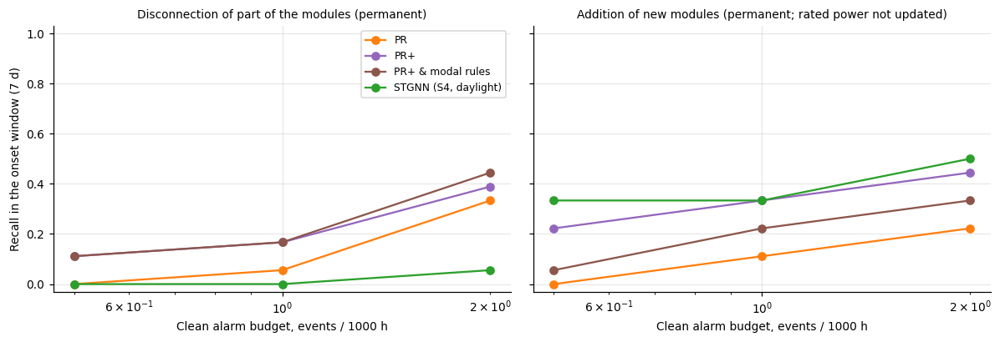

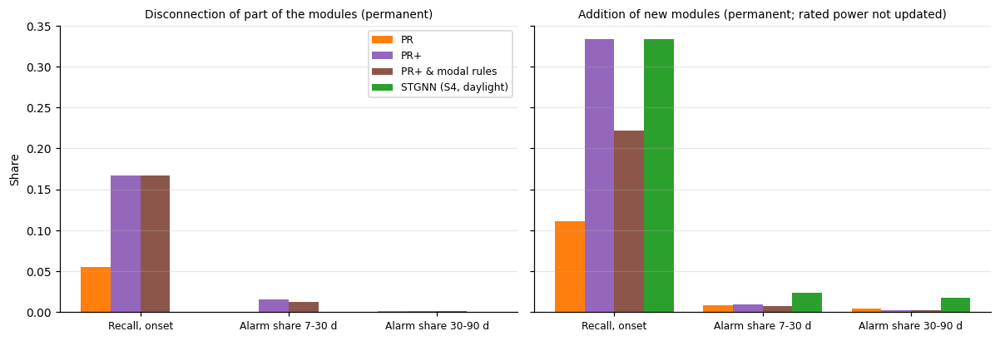

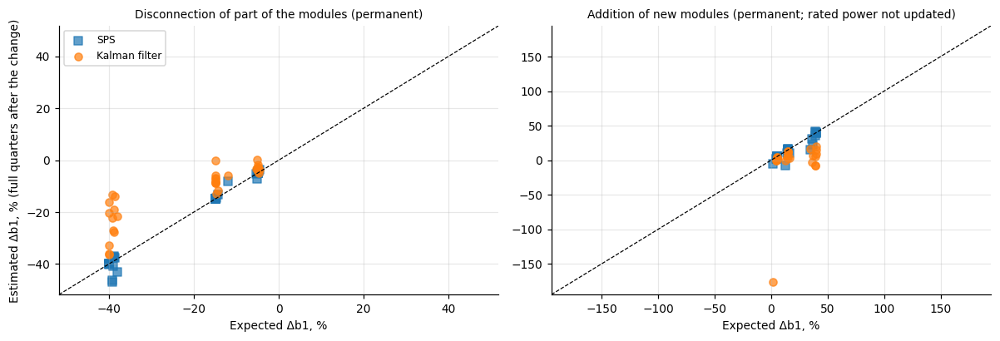

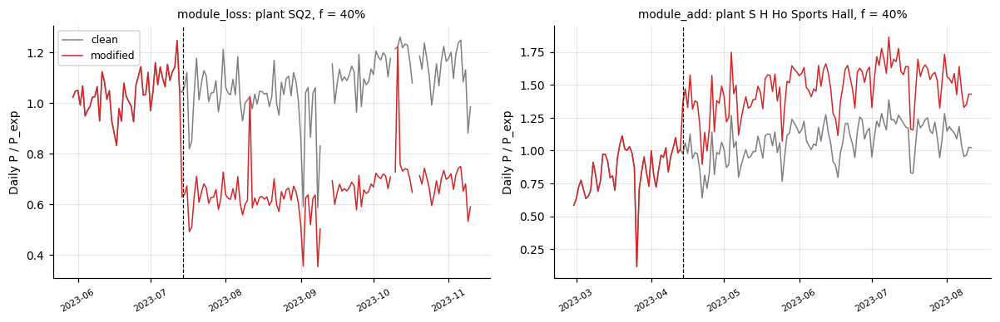

In [97]:
# 18.3 Figures
if CONFIG_OK:
    config_figs = psc.plot_all(cres, CONFIG_FIG)
    for f in config_figs.values():
        display(f)
    plt.close("all")

In [98]:
# 18.4 Export to LaTeX and CSV
if CONFIG_OK:
    config_tex = psc.export_latex(cres, CONFIG_OUT)
    config_zip = psc.zip_outputs(CONFIG_OUT, CONFIG_FIG)
    display(sse.download_link(config_zip, "Download archive: .tex, .csv and figures (config_results.zip)"))

### 18.5. How to interpret the results

- **`detection`**: recall within the onset window by strength $f$. A 15–40% step is easy for power-ratio detectors; weak changes (5%) and equal-budget comparisons are informative.
- **`persistence`**: alarms after the onset window. For `module_add` (a legitimate change), prolonged alarms are unnecessary; for `module_loss`, they indicate an unresolved fault. PR with a fixed plant baseline alarms for months, while PR+ “gets used to” the change in ~30 days (rolling median).
- **`cause`**: the cause assigned by modal rules; disconnecting strings at one inverter may resemble an inverter fault (asymmetric inverter shares).
- **`paired`**: predefined pairs: STGNN versus PR+ and PR, PR+ versus PR, PR+ with modal rules versus PR+; “A better / B better” is reported only if the CI excludes 0 and $p_{Holm} < 0.05$ (lower post-change alarm fraction is better).
- **`b1`, `b1_paired`**: quarterly $\Delta\beta_1$ estimates, separately for the change quarter (a before/after mixture) and full quarters afterward. The Kalman-filter model assumes a random walk for slow degradation, so it tracks a step with a delay (lag column); SPS is recomputed independently each quarter.
- A configuration change is not degradation: if a $\beta_1$ estimate does not separate the step, it cannot be interpreted as a degradation rate without accounting for the plant maintenance log.


## 19. Fleet remaining useful life (RUL)

Independent section (module `pv_rul.py`): reads only `ca` (section 3) and quarterly $\beta_1$ estimates `per` (section 6), without modifying them; the notebook works without it.

**The degradation rate** is obtained not from the median “raw” PR, but from two sources:
- **PR, fleet-adjusted**: monthly PR divided by the median PR of cohort 1 plants in the same month (excluding the plant itself, leave-one-out). This removes a fleet-wide shift (the 2023 pyranometer replacement, etc.). It also removes common fleet degradation, so the rate is **relative to the fleet**, and its RUL is optimistic if the whole fleet degrades;
- **SPS $\beta_1$**: quarterly physical-regression coefficient (section 6) using harmonized irradiance; the common trend is retained. If section 6 uses the Kalman filter, **Kalman $\beta_1$** is also shown.
- **STGNN $\eta$**: a third source, the hourly physical efficiency index $\eta_{i,t}\in(0,1)$ from frozen trained STGNN models (section 10 / `base_models`), averaged across seeds; daytime hours ($a_t > 0.05$), monthly medians, and then the same year-over-year ratios are used. Weights remain unchanged (fingerprints checked). Caveats: $\eta$ is a sigmoid output, so it saturates near 1 and underestimates the rate; 2021–2022 is the model's training period (in-sample). This source is optional: without models, the section uses two sources.

The first two sources bound RUL from two sides: plant-specific degradation and total degradation.

**Calculation.** Rate $r$ is the median year-over-year ratio (same month or same quarter), %/year. Current level $c$ is the ratio of the last-year median to the first-year median. Remaining useful life to level $\theta = 0.8$ of the initial level:
$$\mathrm{RUL} = \frac{c - \theta}{|r|}.$$
The 95% interval uses bootstrap: year-over-year pairs and months from the first and last years are resampled simultaneously; more than just the median is reported.

**Statuses:**
- `estimated`: the rate is significantly negative, and the entire RUL interval lies within horizon $H = 30$ years;
- `estimated, upper bound > H`: the rate is significant, but the RUL upper bound exceeds the horizon;
- `censored`: no significant degradation (rate upper bound $\ge 0$) or RUL $> H$; such plants are **not excluded** and appear as “RUL > 30” in the table and a right arrow in the figure;
- `below threshold`: the threshold has already been reached;
- cohort 2 (from 2022): only one year pair, 2023/2022, so RUL is a **conditional scenario**, “if the 2023/2022 change persists” (`RUL_COHORT2 = "conditional"`), or is not calculated (`"skip"`); cohort 3 (2023 only) is not assessed.


In [99]:
# 19.0 Imports and parameters (optional section)
try:
    import pv_rul
    RUL_OK = True
except ImportError as exc:
    RUL_OK = False
    print("section 19 skipped:", exc)
RUL_OUT, RUL_FIG = "results/rul", "results/figures"
RUL_COHORT2 = "conditional"            # "conditional" or "skip"
RUL_SPS_RECOMPUTE = True               # if ESTIMATOR == "kalman": compute SPS b1 separately for RUL
if RUL_OK:
    RUL_CFG = pv_rul.RULConfig(threshold=0.80, horizon=30.0, n_boot=2000, cohort2=RUL_COHORT2)

In [100]:
# 19.1 Quarterly b1 (section 6) and RUL estimation
if RUL_OK:
    _est = globals().get("ESTIMATOR", "sps")
    per_sps_rul = per if _est == "sps" else None
    per_kf_rul = per if _est == "kalman" else None
    if per_sps_rul is None and RUL_SPS_RECOMPUTE:
        per_sps_rul = sps_mod.sps_periods(df, phys, pv_cols, rated, valid, t_cell, cloud)
    RUL_MODELS = globals().get("ss_models") or globals().get("base_models")   # STGNN: third source (optional)
    rul_res = pv_rul.run_rul(ca, per_sps=per_sps_rul, per_kalman=per_kf_rul, cfg=RUL_CFG, out_dir=RUL_OUT,
                             models=RUL_MODELS, df=df if RUL_MODELS else None, phys=phys if RUL_MODELS else None)
    print("rate sources:", rul_res.meta["sources"], "| STGNN seeds:", rul_res.meta["stgnn_seeds"])

rate sources: ['PR, fleet-adjusted', 'SPS b1', 'STGNN eta'] | STGNN seeds: 2


In [101]:
# 19.2 Tables
if RUL_OK:
    pv_rul.show(rul_res)

Threshold: 0.80 of the reference-year level; horizon H = 30 yr; bootstrap B = 2000; cohort 2: conditional
RUL status by rate source and cohort


,Rate source,Cohort,n,Estimated,Upper bound > H,"Censored, n.s.","Censored, RUL > 30 yr",Below threshold,Not estimable,Conditional,"Median RUL of estimated, yr","Median rate, %/yr"
0,"PR, fleet-adjusted",Insufficient data,1,0,0,0,0,0,1,,NaN,NaN
1,"PR, fleet-adjusted",Cohort 1 (2021-2023),35,5,2,28,0,0,0,,3.504258,-0.578237
2,"PR, fleet-adjusted",Cohort 2 (from 2022),19,6,1,6,0,2,4,yes,1.593405,-3.427027
3,"PR, fleet-adjusted",Cohort 3 (2023 only),5,0,0,0,0,0,5,,NaN,NaN
4,SPS b1,Insufficient data,1,0,0,0,0,0,1,,NaN,NaN
5,SPS b1,Cohort 1 (2021-2023),35,0,0,32,0,3,0,,NaN,-2.914053
6,SPS b1,Cohort 2 (from 2022),19,1,0,12,0,1,5,yes,1.089344,-10.530936
7,SPS b1,Cohort 3 (2023 only),5,0,0,0,0,0,5,,NaN,NaN
8,STGNN eta,Insufficient data,1,0,0,0,0,0,1,,NaN,NaN
9,STGNN eta,Cohort 1 (2021-2023),35,3,0,19,13,0,0,,1.692499,-0.010666


Agreement of RUL status between rate sources (cohort 1)


,Source A,Source B,n,Same class,Finite in A only,Finite in B only,Share same
0,"PR, fleet-adjusted",SPS b1,35,29,5,1,0.828571
1,"PR, fleet-adjusted",STGNN eta,35,27,6,2,0.771429
2,SPS b1,STGNN eta,35,29,3,3,0.828571


Per-plant RUL (bootstrap intervals; censored plants kept)


,Plant,Cohort,Rate source,YoY pairs,"Rate, %/yr (95% CI)",Current level,"RUL, yr (95% CI)",Status
0,Shaw Auditorium,0,"PR, fleet-adjusted",0,n/a,n/a,n/a,not estimable (insufficient data)
1,CYT (Station 1),1,"PR, fleet-adjusted",15,"3.31 [-0.74, 5.98]",1.088,> 30 (lower 29.4),censored: no significant degradation
2,CYT (Station 2),1,"PR, fleet-adjusted",18,"-0.08 [-2.28, 2.51]",1.092,> 30 (lower 10.4),censored: no significant degradation
3,LSK North,1,"PR, fleet-adjusted",19,"-1.98 [-4.74, 0.27]",0.965,> 30 (lower 3.0),censored: no significant degradation
4,LSK South,1,"PR, fleet-adjusted",17,"-0.58 [-4.16, 0.67]",0.987,> 30 (lower 4.0),censored: no significant degradation
...,...,...,...,...,...,...,...,...
175,SQ Block P,3,STGNN eta,0,n/a,n/a,n/a,not estimable (2023 only)
176,SQ Block Q,3,STGNN eta,0,n/a,n/a,n/a,not estimable (2023 only)
177,SQ Block Q (Phrase 2),3,STGNN eta,0,n/a,n/a,n/a,not estimable (2023 only)
178,UG Hall8,3,STGNN eta,0,n/a,n/a,n/a,not estimable (2023 only)


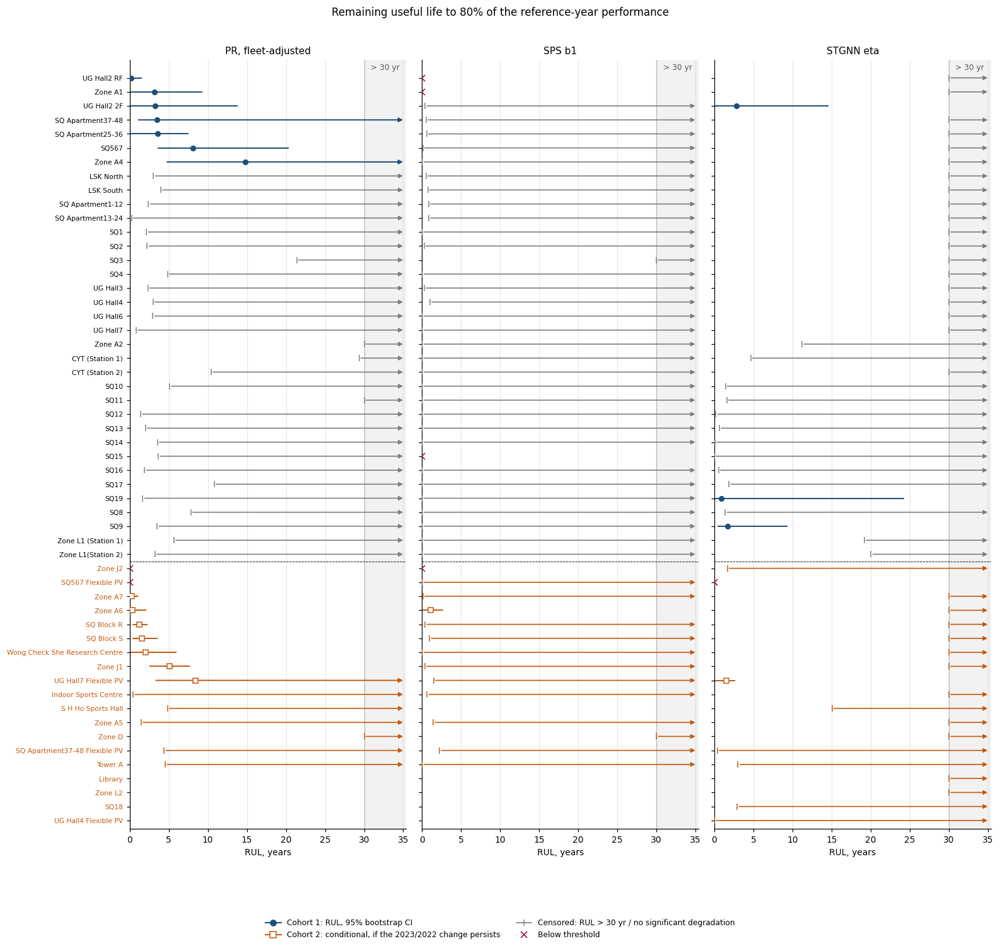

In [102]:
# 19.3 Figure: per-plant RUL (point and interval; right arrow for censored estimates)
if RUL_OK:
    rul_fig_path = f"{RUL_FIG}/fig_rul_forest.png"
    rul_fig = pv_rul.plot_forest(rul_res, rul_fig_path)
    if rul_fig is not None:
        display(rul_fig)
    plt.close("all")

In [103]:
# 19.4 Export to LaTeX and CSV
if RUL_OK:
    rul_tex = pv_rul.export_latex(rul_res, RUL_OUT)
    rul_zip = pv_rul.zip_outputs(RUL_OUT, [rul_fig_path])
    try:
        display(sse.download_link(rul_zip, "Download archive: .tex, .csv and figure (rul_results.zip)"))
    except NameError:
        print("archive:", rul_zip)

### 19.5. How to interpret the results

- RUL is calculated only to 80% of the plant's **first year** of data, not of rated capacity; it is a projection assuming the current rate persists (linear extrapolation), not a warranty period.
- The data cover 2021–2023: cohort 1 has two year pairs, so intervals are wide and most plants are likely to be censored. This is expected, not a method failure.
- Source disagreement (`agreement`) shows where RUL depends on whether the common fleet trend is removed: finite RUL only from $\beta_1$ indicates common degradation or drift, while finite RUL only from fleet-adjusted PR indicates plant-specific degradation.
- Cohort 2 results are labeled as conditional scenarios: one year pair, 2023/2022, cannot distinguish long-term degradation from a one-off change (soiling, repair, sensor replacement).


## 20. Semi-synthetic validation of RUL algorithms

Independent section (module `pv_rul_semisynth.py`): uses the semi-synthetic dataset from section 10 (`D`, `C`) and frozen STGNN models; neither the notebook nor sections 3–19 depend on it.

**Design.** On a copy of the real data, known degradation $P'_{i,t} = P_{i,t}\,(1 + r_i\,\tau_t)$, $r_i \in \{-0.5;\,-1;\,-2;\,-4\}$ %/year, is applied to a subset of plants (40%, different placements across seeds); the rest are controls ($r_i = 0$). Expected power from the physical model remains unchanged. Three scenarios:
- **Plant-specific degradation**: only individual-plant degradation;
- **+ fleet-wide step**: all plants receive a $-5$% step from 2023-01-01 (sensor replacement, **not** degradation; the true rate remains unchanged);
- **+ common fleet rate**: additional fleet-wide degradation of $-0.5$%/year (included in the true rate).

**Paired protocol.** Each algorithm is applied to original and modified data; rate and RUL are calculated from the “modified / original” series ratio, removing the real plants' unknown degradation and retaining only the injected component. Ground truth is the year-over-year ratio of the injected multiplier over the same covered months; $\mathrm{RUL}_{true} = (c_{true} - 0.8)/|r_{true}|$.

**Algorithms:** fleet-adjusted PR, SPS $\beta_1$, Kalman $\beta_1$, STGNN $\eta$ — the same functions as in section 19.

**Metrics:** rate MAE and bias (percentage points/year, CIs from plant-level cluster bootstrap), RUL MAE (finite true RUL only), interval coverage of the true value, sensitivity/specificity/balanced accuracy for classifying “finite RUL” versus “censored.” Paired comparisons use MAE differences on the same plants, bootstrap, and a sign-flip permutation test with Holm correction. Cohort 2 has a separate table (conditional scenario based on one year pair).


In [104]:
# 20.0 Import (optional section)
try:
    import pv_rul_semisynth as prs
    RULSS_OK = all(k in globals() for k in ("D", "C"))
    if not RULSS_OK:
        print("section 20 skipped: semi-synthetic data D, C (section 10) not found")
except ImportError as exc:
    RULSS_OK = False
    print("section 20 skipped:", exc)
RULSS_OUT, RULSS_FIG = "results/rul_semisynth", "results/figures"
RULSS_PLACEMENTS = (0, 1, 2)            # placements of degrading plants

In [105]:
# 20.1 Run: all algorithms on the same modified data
if RULSS_OK:
    RULSS_MODELS = globals().get("ss_models") or globals().get("base_models")
    rulss_res = prs.run_rul_semisynth(D, C, models=RULSS_MODELS, placement_seeds=RULSS_PLACEMENTS,
                                      kalman_cfg=globals().get("KALMAN_CFG"), out_dir=RULSS_OUT)

18:48:41 [rul-semisynth] placement 0, plant: 22 plants changed, 4 sources
18:49:24 [rul-semisynth] placement 0, plant+step: 54 plants changed, 4 sources
18:50:06 [rul-semisynth] placement 0, plant+common: 54 plants changed, 4 sources
18:50:40 [rul-semisynth] placement 1, plant: 22 plants changed, 4 sources
18:51:22 [rul-semisynth] placement 1, plant+step: 54 plants changed, 4 sources
18:52:04 [rul-semisynth] placement 1, plant+common: 54 plants changed, 4 sources
18:52:39 [rul-semisynth] placement 2, plant: 22 plants changed, 4 sources
18:53:21 [rul-semisynth] placement 2, plant+step: 54 plants changed, 4 sources
18:54:03 [rul-semisynth] placement 2, plant+common: 54 plants changed, 4 sources


In [106]:
# 20.2 Summary comparison of RUL algorithms and detailed tables
if RULSS_OK:
    prs.show(rulss_res)

placements: [0, 1, 2] | sources: ['PR, fleet-adjusted', 'SPS b1', 'Kalman b1', 'STGNN eta'] | STGNN seeds: [0, 1] | weights unchanged: True | 398 s
Semi-synthetic RUL design


,Item,Value
0,Scenarios,Plant-specific degradation; Plant-specific deg...
1,"Plant-specific rates, %/yr","-0.5, -1, -2, -4 (controls: 0)"
2,Degraded share of plants,40%
3,Fleet-wide step (not degradation),-5% from 2023-01-01
4,Common fleet rate,-0.5 %/yr
5,Threshold / horizon,0.80 / 30 yr
6,Placements,"0, 1, 2"
7,Rate sources,"PR, fleet-adjusted, SPS b1, Kalman b1, STGNN eta"


Comparison of RUL algorithms on semi-synthetic data (cohort 1, all scenarios)


,Source,n,"Rate MAE, p.p./yr",Rate MAE CI,"Rate bias, p.p./yr","RUL MAE, yr",CI coverage,Sensitivity,Specificity,Balanced accuracy
0,"PR, fleet-adjusted",315,0.798,"[0.74, 0.86]",0.798,2.371,0.829,0.500,1.000,0.750
1,SPS b1,315,1.639,"[1.59, 1.67]",-1.638,2.705,0.867,1.000,0.944,0.972
2,Kalman b1,315,1.067,"[0.99, 1.14]",-0.785,4.674,0.543,0.961,0.657,0.809
3,STGNN eta,315,0.850,"[0.67, 1.03]",0.661,7.078,0.695,0.206,0.981,0.594


Comparison of RUL algorithms by scenario (cohort 1)


,Source,Scenario,n,"Rate MAE, p.p./yr",Rate MAE CI,"Rate bias, p.p./yr","RUL MAE, yr",CI coverage,Sensitivity,Specificity,Balanced accuracy
0,"PR, fleet-adjusted",Plant-specific degradation,105,0.627,"[0.57, 0.68]",0.627,1.464,0.905,0.567,1.000,0.783
1,SPS b1,Plant-specific degradation,105,0.013,"[0.01, 0.02]",-0.012,0.173,1.000,1.000,1.000,1.000
2,Kalman b1,Plant-specific degradation,105,0.158,"[0.10, 0.22]",0.156,3.343,0.762,0.933,1.000,0.967
3,STGNN eta,Plant-specific degradation,105,0.638,"[0.45, 0.83]",0.637,6.619,0.714,0.167,1.000,0.583
4,"PR, fleet-adjusted",Plant-specific degradation + fleet-wide step (...,105,0.627,"[0.57, 0.68]",0.627,1.462,0.914,0.533,1.000,0.767
5,SPS b1,Plant-specific degradation + fleet-wide step (...,105,4.882,"[4.73, 4.96]",-4.882,8.779,0.600,1.000,0.840,0.920
6,Kalman b1,Plant-specific degradation + fleet-wide step (...,105,2.776,"[2.48, 3.06]",-2.776,7.592,0.210,0.967,0.027,0.497
7,STGNN eta,Plant-specific degradation + fleet-wide step (...,105,0.820,"[0.64, 1.01]",0.251,5.223,0.771,0.300,0.947,0.623
8,"PR, fleet-adjusted",Plant-specific + common fleet degradation,105,1.141,"[1.08, 1.20]",1.141,4.036,0.667,0.429,1.000,0.714
9,SPS b1,Plant-specific + common fleet degradation,105,0.022,"[0.02, 0.03]",-0.021,0.174,1.000,1.000,1.000,1.000


... (2 outputs left out)

Cohort 2 (conditional, one year pair): comparison of RUL algorithms


,Source,n,"Rate MAE, p.p./yr",Rate MAE CI,"Rate bias, p.p./yr","RUL MAE, yr",CI coverage,Sensitivity,Specificity,Balanced accuracy
0,"PR, fleet-adjusted",135,0.493,"[0.47, 0.52]",0.479,1.503,0.822,0.519,1.000,0.760
1,SPS b1,126,1.678,"[1.67, 1.69]",-1.678,3.298,0.754,0.935,0.788,0.861
2,Kalman b1,135,1.154,"[1.00, 1.28]",-0.627,5.160,0.459,0.962,0.651,0.806
3,STGNN eta,171,0.817,"[0.58, 1.08]",0.745,6.360,0.649,0.367,0.955,0.661


Paired comparisons of RUL algorithms (cohort 1; Holm-adjusted)


,A,B,Metric,n,Plants,A - B,CI low,CI high,p,p (Holm),Verdict
0,"PR, fleet-adjusted",SPS b1,"absolute rate error, p.p./yr",315,35,-0.841,-0.914,-0.759,0.000,0.006,A better
1,"PR, fleet-adjusted",SPS b1,correct status (finite vs censored),315,35,-0.124,-0.184,-0.070,0.001,0.006,B better
2,"PR, fleet-adjusted",Kalman b1,"absolute rate error, p.p./yr",315,35,-0.269,-0.370,-0.168,0.000,0.006,A better
3,"PR, fleet-adjusted",Kalman b1,correct status (finite vs censored),315,35,0.083,0.000,0.156,0.051,0.153,no difference shown
4,"PR, fleet-adjusted",STGNN eta,"absolute rate error, p.p./yr",315,35,-0.052,-0.253,0.146,0.627,1.000,no difference shown
5,"PR, fleet-adjusted",STGNN eta,correct status (finite vs censored),315,35,0.108,0.032,0.181,0.006,0.032,A better
6,SPS b1,Kalman b1,"absolute rate error, p.p./yr",315,35,0.572,0.500,0.640,0.000,0.006,B better
7,SPS b1,Kalman b1,correct status (finite vs censored),315,35,0.206,0.175,0.238,0.000,0.006,A better
8,SPS b1,STGNN eta,"absolute rate error, p.p./yr",315,35,0.789,0.606,0.965,0.000,0.006,B better
9,SPS b1,STGNN eta,correct status (finite vs censored),315,35,0.232,0.152,0.311,0.000,0.006,A better


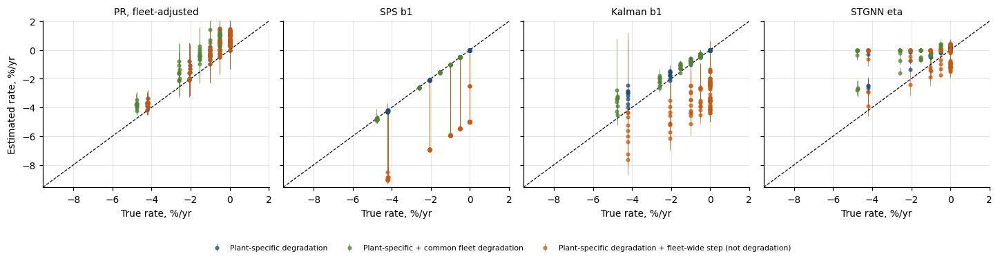

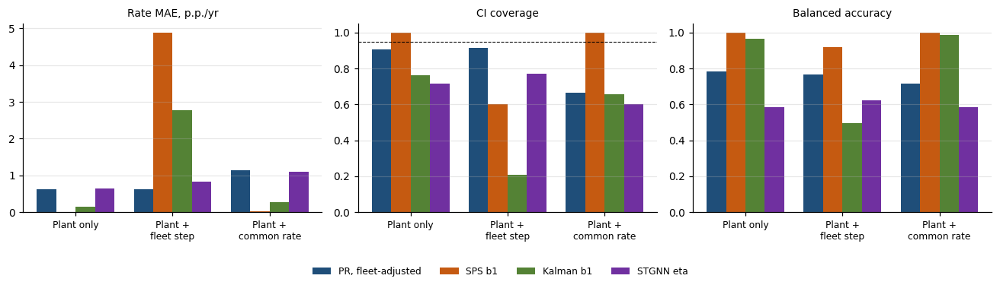

In [107]:
# 20.3 Figures: estimated versus true rate; metrics by scenario
if RULSS_OK:
    rulss_figs = prs.plot_all(rulss_res, RULSS_FIG)
    for f in rulss_figs.values():
        display(f)
    plt.close("all")

In [108]:
# 20.4 Export to LaTeX/CSV and archive
if RULSS_OK:
    rulss_tex = prs.export_latex(rulss_res, RULSS_OUT)
    rulss_zip = prs.zip_outputs(RULSS_OUT, RULSS_FIG)
    try:
        display(sse.download_link(rulss_zip, "Download archive: .tex, .csv and figures (rul_semisynth_results.zip)"))
    except NameError:
        print("archive:", rulss_zip)

### 20.5. How to interpret the results

- **`overall`** is the main summary: one row per algorithm across all cohort 1 scenarios. Lower rate and RUL MAE are better; coverage should be near 0.95; balanced accuracy measures the ability to distinguish finite from censored RUL.
- **`comparison`** shows the same table by scenario. As expected, in the step scenario, SPS/Kalman $\beta_1$ interpret the step as degradation (negative bias, false finite RUL for controls), whereas fleet-adjusted PR removes it. In the common-rate scenario, fleet-adjusted PR also removes that rate (bias of at least $+0.5$ percentage points/year: with few plants, degrading plants further shift the fleet median; RUL is optimistic), whereas $\beta_1$ does not. No source is therefore best in all scenarios, and they should be interpreted jointly in section 19.
- **STGNN $\eta$** saturates (sigmoid), underestimating the rate magnitude and pushing RUL beyond the horizon; low MAE at small rates does not imply sensitivity — inspect sensitivity and `by_rate`.
- **`paired`** reports “A better / B better” only when the difference CI excludes 0 and $p_{Holm} < 0.05$; with few plants and placements, “no difference shown” is expected.
- This validates recovery of **injected** linear degradation from three years of data; it does not establish long-term RUL prediction accuracy for real plants.


## 21. Method summary tables by protocol (best results highlighted)

This section performs no training or recomputation: it uses saved results from sections 10, 12–16, 18, and 20 (`pms.method_tables` in `pv_metrics_summary.py`). Missing sections are skipped.

Each protocol receives **one “methods × metrics” table**, rather than pairwise comparisons:

| Protocol | Methods | Metrics highlighted |
|---|---|---|
| P10 | fuzzy classifier, crisp rules, k-means; SPS and Kalman filter | fraction of correctly identified failure types; β1 change MAE, β1 change sensitivity, fraction of degradation detected |
| P12 | S0–S4, PR, PR+, zero-power rule, Isolation Forest | recall by scenario, precision, F1, false alarms, delay |
| P13 | k-means, hard and soft FCM | recall, F1, cross-seed variability |
| P14 | PR, PR+, STGNN, STGNN-day, both fusion variants | recall by scenario, precision, F1, false alarms |
| P15/P16 | PR, PR+, PR+ with modal rules, STGNN and its modal variants | recall, cause macro-F1, unnecessary-alarm fraction |
| P18 | PR, PR+, PR+ with modal rules, STGNN (S4); SPS and Kalman | detection within the first 7 days, alarm fraction during days 7–30 and 30–90, β1 change, Kalman-filter delay |
| P20 | fleet-adjusted PR, SPS β1, Kalman β1, STGNN η | degradation-rate MAE, bias, RUL MAE, interval coverage, balanced accuracy |

**How to read the highlighting.**
- **Bold**: the best value in a column (closest to 0 for bias, to 1 for sensitivity, and to the nominal level for coverage; within-group for grouped tables).
- <u>Underlined</u>: a value not statistically distinguishable from the best: paired test on the same events (permutation test or paired event-level bootstrap), Holm correction across the entire table, $p_{Holm} \geq 0.05$.
- Where event-level outcomes are unavailable (interpolated “equal-budget” P12/P13 rows), no underlining is applied; this is stated in the table note.

**Comparisons are valid only within a single table**: protocols differ in scenarios, event definitions, and operating points. All tables and captions are in English; export: `results/summary/methods_<protocol>.csv`, `..._marks.csv`, `..._tie_tests.csv`, `.tex`, and combined `methods_all.tex` (packages `booktabs`, `array`, `graphicx`).


In [109]:
# 21.1 Method summary tables by protocol (from saved results only)
import pv_metrics_summary as pms
METHOD_TABLES = pms.method_tables(ss_res=globals().get("ss_res"), fx_res=globals().get("fx_res"),
                                  fcm_res=globals().get("fcm_res"), val_res=globals().get("val_res"),
                                  modal_res=globals().get("modal_res"), fmm_res=globals().get("fmm_res"),
                                  cfg_res=globals().get("cres"), rul_res=globals().get("rulss_res"),
                                  alpha=0.05, n_boot=1000, n_perm=10000)
print("tables:", ", ".join(METHOD_TABLES) if METHOD_TABLES else "none (no saved results of sections 10-20)")
pms.show_method_tables(METHOD_TABLES)

tables: P10_class, P10_estimators, P12_equal_budget, P12_operating_points, P13, P14, P18_detectors, P18_estimators, P20, P15, P16
[P10_class] P10: share of detected events with the correct fault type (frozen STGNN detections, majority class per event)


Method,Full-day outage,Overgeneration / data spike,Fleet-wide GHI shift,All detected events
Fuzzy classifier (Mamdani rules),1.000,0.222,0.125,0.250
Crisp rules,1.000,0.778,1.000,0.929
K-means anomaly clusters,0.000,0.000,0.875,0.500


  bold = best; underlined = not significantly different from the best (paired test, Holm, p >= alpha).  Not tested: none.  Same detected events for all classifiers; columns = injected scenario.
[P10_estimators] P10: degradation estimators (SPS vs Kalman filter) on the same injected events


Method,"MAE Δβ1, p.p.",Sensitivity to Δβ1 (est. / true),"MAE Δβ1 under degradation, p.p.",Degradation detected (evidence share),False evidence without injection
SPS,0.99,0.569,8.36,0.444,0.333
Kalman,0.75,0.380,3.36,0.444,0.111


  bold = best; underlined = not significantly different from the best (paired test, Holm, p >= alpha).  Not tested: Sensitivity to Δβ1 (est. / true).  Sensitivity: median ratio estimated / injected Δβ1 (target 1).
[P12_equal_budget] P12: methods at the equal false-alarm budget on control plants (1.39 /1000 h, S0 operating point)


Method,Full-day outage,Power limitation (clipping),Partial shading (morning / evening),Partial power loss,Overgeneration / data spike,Deviation at low irradiance,Fleet-wide GHI shift,Recall (all),Precision,F1,Test FA (all plants) /1000 h,"Delay, h (median)"
S0 before (section 10),0.254,0.002,0.000,0.000,0.250,0.001,0.057,0.066,0.981,0.123,1.03,5.9
S4 after: + calibrated fuzzy rules,0.833,0.000,0.000,0.000,0.247,0.000,0.056,0.097,0.976,0.176,1.34,1.7
Baseline: PR threshold rule,0.167,0.000,0.000,0.000,0.167,0.000,0.056,0.046,1.000,0.088,0.77,11.0
"Baseline: PR+ (hour x month, peers, rolling)",0.167,0.272,0.056,0.118,0.212,0.176,0.000,0.135,0.776,0.231,0.89,2.7
Baseline: rule P~0 at GHI>200,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.056,1.000,0.105,1.50,1.0
Baseline: Isolation Forest,0.333,0.143,0.000,0.000,0.111,0.000,0.056,0.065,1.000,0.122,0.77,10.0


... (13 outputs left out)

Method,Recall: Drift + plant fault,Recall: Inverter trip,Recall: Short outages,Recall: Phase loss,Recall (all faults),Nuisance: Grid curtailment,Nuisance: Meter fault,Nuisance share (all),Macro-F1 (cause)
PR threshold rule,0.056,0.333,0.000,0.000,0.097,0.056,0.056,0.056,0.019
"PR+ (hour x month, peers, rolling)",0.444,0.611,0.111,0.333,0.375,0.667,0.556,0.611,0.060
Modal rules only,0.000,1.000,0.889,1.000,0.722,0.000,0.000,0.000,0.670
PR+ with modal decision fusion,0.222,1.000,0.889,1.000,0.778,0.000,0.222,0.111,0.728
"STGNN (S4, daylight)",0.000,0.306,0.000,0.000,0.076,0.056,0.000,0.028,0.000
STGNN with modal decision fusion,0.000,1.000,0.889,1.000,0.722,0.056,0.000,0.028,0.663
STGNN-mm early fusion,0.000,0.278,0.000,0.000,0.069,0.056,0.000,0.028,0.000
STGNN-mm early fusion + modal edges,0.000,0.306,0.000,0.000,0.076,0.056,0.000,0.028,0.000
STGNN-mm + modal edges + decision fusion,0.000,1.000,0.889,1.000,0.722,0.056,0.000,0.028,0.663


  bold = best; underlined = not significantly different from the best (paired test, Holm, p >= alpha).  Not tested: none.  Nuisance = alarms on non-fault scenarios (grid curtailment, meter fault). Results of the metering / new-obstruction scenarios depend on the open generator issue.
[P16] P16: modal scenarios (section 16) at the equal clean alarm budget (1 /1000 h)


Method,Recall: Drift + plant fault,Recall: Inverter trip,Recall: Short outages,Recall: Phase loss,Recall: New obstruction,Recall (all faults),Nuisance: Grid curtailment,Nuisance: Meter fault,Nuisance share (all),Macro-F1 (cause)
PR threshold rule,0.056,0.333,0.000,0.000,0.222,0.122,0.056,0.056,0.056,0.051
"PR+ (hour x month, peers, rolling)",0.444,0.611,0.111,0.333,0.444,0.389,0.667,0.556,0.611,0.086
Modal rules only,0.000,1.000,0.889,1.000,0.056,0.589,0.000,0.000,0.000,0.639
PR+ with modal decision fusion,0.222,1.000,0.889,1.000,0.389,0.700,0.000,0.222,0.111,0.727
"STGNN (S4, daylight)",0.000,0.306,0.000,0.000,0.139,0.089,0.056,0.000,0.028,0.028
STGNN with modal decision fusion,0.000,1.000,0.889,1.000,0.139,0.606,0.056,0.000,0.028,0.651
STGNN-mm early fusion + modal edges,0.000,0.306,0.000,0.000,0.139,0.089,0.056,0.000,0.028,0.028
STGNN-mm + modal edges + decision fusion,0.000,1.000,0.889,1.000,0.139,0.606,0.056,0.000,0.028,0.651
PR+ with shading mask and Kalman sd,0.444,0.611,0.111,0.333,0.444,0.389,0.611,0.556,0.583,0.087
"PR+ with shading mask, Kalman sd and modal decision fusion",0.278,1.000,0.889,1.000,0.389,0.711,0.000,0.333,0.167,0.718


  bold = best; underlined = not significantly different from the best (paired test, Holm, p >= alpha).  Not tested: none.  Nuisance = alarms on non-fault scenarios (grid curtailment, meter fault). Results of the metering / new-obstruction scenarios depend on the open generator issue.


In [110]:
# 21.2 Export to LaTeX and CSV
if METHOD_TABLES:
    MT_FILES = pms.export_method_tables(METHOD_TABLES, "results/summary")
    print("LaTeX (all tables):", MT_FILES["all"])
    try:
        display(sse.download_link(MT_FILES["all"], "Download LaTeX: methods_all.tex"))
    except NameError:
        pass

LaTeX (all tables): results/summary/methods_all.tex


### 21.3. Checking seed counts and modal-scenario labels

Nothing is recomputed. For each saved result, the number of frozen models (seeds) used to obtain it is shown; all semi-synthetic protocols should have 5 seeds. For sections 15–16, the labeled strength of each event is checked again against its scenario range (`smg.check_strengths`).


In [111]:
# 21.3 Seeds per protocol and modal label check (only saved results)
import os
import pv_semisynth_eval as sse
EXPECTED_SEEDS = len(train_seeds)
_seed_rows = []
for _name, _proto in [("ss_res", "P10/P11"), ("sens", "P11"), ("fx_res", "P12"), ("fcm_res", "P13"), ("val_res", "P14"),
                      ("modal_res", "P15"), ("fmm_res", "P16"), ("cres", "P18"), ("rulss_res", "P20")]:
    _r = globals().get(_name)
    if _r is None:
        continue
    _m = getattr(_r, "meta", {}) or {}
    _s = _m.get("model_seeds") or _m.get("seeds") or _m.get("stgnn_seeds") or []
    _E = getattr(_r, "events", None)
    if not _s and isinstance(_E, pd.DataFrame) and "model_seed" in _E:
        _s = list(_E["model_seed"].unique())
    _s = sorted({str(x) for x in _s if str(x) not in ("-", "nan", "None")},
                key=lambda x: (0, int(x)) if x.lstrip("-").isdigit() else (1, x))
    _seed_rows.append({"Protocol": _proto, "Result": _name, "Model seeds": len(_s), "Seeds": ", ".join(_s),
                       "OK": len(_s) >= EXPECTED_SEEDS})
SEED_CHECK = pd.DataFrame(_seed_rows)
display(SEED_CHECK)
if len(SEED_CHECK):
    os.makedirs("results/summary", exist_ok=True)
    SEED_CHECK.to_csv("results/summary/seed_check.csv", index=False)
    with open("results/summary/seed_check.tex", "w") as _f:
        _f.write(sse.df_to_latex(SEED_CHECK.assign(OK=SEED_CHECK["OK"].map({True: "yes", False: "no"})),
                                 "Number of frozen model seeds per semi-synthetic protocol.", "tab:seed_check"))
    print("LaTeX: results/summary/seed_check.tex")
if len(SEED_CHECK) and not SEED_CHECK["OK"].all():
    print("WARNING: fewer than", EXPECTED_SEEDS, "model seeds in:", SEED_CHECK.loc[~SEED_CHECK["OK"], "Result"].tolist())
try:
    import pv_semisynth_modal_gen as smg
    _cfg16 = smg.ModalGenConfig()
    _rng = smg.strength_ranges(_cfg16)
    _st = []
    for _name, _proto in (("modal_res", "P15"), ("fmm_res", "P16")):
        _r = globals().get(_name)
        if _r is not None and "labels" in getattr(_r, "meta", {}):
            _L = _r.meta["labels"]
            smg.check_strengths(_L, _cfg16)            # raises ValueError if a label is out of range
            for _scn, _g in _L.groupby("scenario"):
                _st.append({"Protocol": _proto, "Scenario": _scn, "Events": len(_g),
                            "Min": _g["strength"].min(), "Max": _g["strength"].max(),
                            "Distinct": _g["strength"].nunique(),
                            "Configured range": "%g--%g" % _rng[_scn]})
            print(_name, ": labelled strengths within configured ranges")
    MODAL_STRENGTHS = pd.DataFrame(_st)
    if len(MODAL_STRENGTHS):
        display(MODAL_STRENGTHS.round(3))
        os.makedirs("results/modal", exist_ok=True)
        MODAL_STRENGTHS.to_csv("results/modal/modal_strengths.csv", index=False)
        with open("results/modal/modal_strengths.tex", "w") as _f:
            _f.write(sse.df_to_latex(MODAL_STRENGTHS.rename(columns={"Scenario": "Scenario name"}),
                                     "Labelled strength by modal scenario (P15, P16).", "tab:modal_strengths", digits=2))
        print("LaTeX: results/modal/modal_strengths.tex")
except ImportError:
    pass


,Protocol,Result,Model seeds,Seeds,OK
0,P10/P11,ss_res,2,"0, 1",False
1,P11,sens,2,"0, 1",False
2,P12,fx_res,2,"0, 1",False
3,P13,fcm_res,2,"0, 1",False
4,P14,val_res,2,"0, 1",False
5,P15,modal_res,2,"0, 1",False
6,P16,fmm_res,2,"0, 1",False
7,P18,cres,2,"0, 1",False
8,P20,rulss_res,2,"0, 1",False


LaTeX: results/summary/seed_check.tex
modal_res : labelled strengths within configured ranges
fmm_res : labelled strengths within configured ranges


,Protocol,Scenario,Events,Min,Max,Distinct,Configured range
0,P15,drift_fault,18,0.300,0.300,1,0.3--0.3
1,P15,grid_curtail,18,0.413,0.768,18,0.4--0.8
2,P15,inverter_trip,18,1.000,3.000,3,1--3
3,P15,metering,18,0.508,0.779,18,0.5--0.8
4,P15,phase_loss,18,1.000,2.000,2,1--2
5,P15,short_outage,18,10.000,30.000,4,10--30
6,P16,drift_fault,18,0.300,0.300,1,0.3--0.3
7,P16,grid_curtail,18,0.413,0.768,18,0.4--0.8
8,P16,inverter_trip,18,1.000,3.000,3,1--3
9,P16,metering,18,0.508,0.779,18,0.5--0.8


LaTeX: results/modal/modal_strengths.tex


## References
- Csáji B. Cs., Campi M. C., Weyer E. (2015) Sign-Perturbed Sums. IEEE TSP 63(1):169–181. https://doi.org/10.1109/TSP.2014.2369000
- Kalman R. E. (1960) A new approach to linear filtering and prediction problems. J. Basic Eng. 82(1):35–45. https://doi.org/10.1115/1.3662552
- Rauch H. E., Tung F., Striebel C. T. (1965) Maximum likelihood estimates of linear dynamic systems. AIAA J. 3(8):1445–1450. https://doi.org/10.2514/3.3166
- Durbin J., Koopman S. J. (2012) Time Series Analysis by State Space Methods, 2nd ed. Oxford Univ. Press. https://doi.org/10.1093/acprof:oso/9780199641178.001.0001
- Hubert L., Arabie P. (1985) Comparing partitions. J. Classif. 2:193–218. https://doi.org/10.1007/BF01908075
- Jordan D. C., Kurtz S. R. (2013) Photovoltaic degradation rates — an analytical review. Prog. Photovolt. 21:12–29. https://doi.org/10.1002/pip.1182
- Mamdani E. H., Assilian S. (1975) An experiment in linguistic synthesis with a fuzzy logic controller. Int. J. Man-Mach. Stud. 7(1):1–13. https://doi.org/10.1016/S0020-7373(75)80002-2
- Takagi T., Sugeno M. (1985) Fuzzy identification of systems and its applications to modeling and control. IEEE Trans. Syst. Man Cybern. 15(1):116–132. https://doi.org/10.1109/TSMC.1985.6313399
- Lin Z. et al. (2025) A high-resolution three-year dataset supporting rooftop PV generation analytics. Sci. Data 12:63. https://doi.org/10.1038/s41597-025-04397-y
- Tsai Y.-H. H., Liang P. P., Zadeh A., Morency L.-P., Salakhutdinov R. (2019) Learning factorized multimodal representations. ICLR 2019. https://arxiv.org/abs/1806.06176
- Mao X. et al. (2017) Least squares generative adversarial networks. ICCV 2017. https://arxiv.org/abs/1611.04076
- Erbs D. G., Klein S. A., Duffie J. A. (1982) Estimation of the diffuse radiation fraction for hourly, daily and monthly-average global radiation. Solar Energy 28(4):293–302. https://doi.org/10.1016/0038-092X(82)90302-4
- For other physical-model and architecture references, see `print(REFERENCES)`.